In [1]:
import os
from itertools import product
from datetime import datetime

import pandas as pd

from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle
)

# ============================================================
# 0. IMPORTS
# ============================================================

import os
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt

from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

from reportlab.lib import colors
from reportlab.lib.colors import HexColor
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import (
    getSampleStyleSheet,
    ParagraphStyle
)
from reportlab.lib.enums import TA_CENTER, TA_LEFT, TA_RIGHT

from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    Image,
    PageBreak,
    KeepTogether
)

from reportlab.graphics.shapes import (
    Drawing,
    Rect,
    Circle,
    Line,
    String,
    Polygon
)

print("Environment ready.")

Environment ready.


In [2]:
# ============================================================
# UNCERTAINTY SCENARIOS
# ============================================================

uncertainty_scenarios = {

    "Baseline": {
        "demand": 100,
        "fuel_cost": 1.0,
        "quality_pressure": 1.0,
        "maintenance_risk": 1.0
    },

    "High Demand": {
        "demand": 130,
        "fuel_cost": 1.0,
        "quality_pressure": 1.0,
        "maintenance_risk": 1.0
    },

    "High Fuel Cost": {
        "demand": 100,
        "fuel_cost": 1.5,
        "quality_pressure": 2.0,
        "maintenance_risk": 2.0
    },

    "High Quality Pressure": {
        "demand": 100,
        "fuel_cost": 1.0,
        "quality_pressure": 1.5,
        "maintenance_risk": 1.0
    },

    "High Maintenance Risk": {
        "demand": 100,
        "fuel_cost": 1.0,
        "quality_pressure": 1.0,
        "maintenance_risk": 1.5
    }
}

print(
    "Number of scenarios:",
    len(uncertainty_scenarios)
)

Number of scenarios: 5


In [3]:
# ============================================================
# GAME DEFINITION
# ============================================================

players = [
    "Production",
    "Quality",
    "Maintenance"
]

strategies = {
    "Production": ["P1", "P2", "P3"],
    "Quality": ["Q1", "Q2", "Q3"],
    "Maintenance": ["M1", "M2", "M3"]
}

print("Players:", players)
print("Strategies:", strategies)

Players: ['Production', 'Quality', 'Maintenance']
Strategies: {'Production': ['P1', 'P2', 'P3'], 'Quality': ['Q1', 'Q2', 'Q3'], 'Maintenance': ['M1', 'M2', 'M3']}


In [4]:
# ============================================================
# PAYOFF TABLE
# ============================================================

payoffs = {
    ("P1","Q1","M1"): (6,6,6),
    ("P1","Q1","M2"): (5,7,7),
    ("P1","Q1","M3"): (4,5,8),

    ("P1","Q2","M1"): (7,5,7),
    ("P1","Q2","M2"): (8,6,8),
    ("P1","Q2","M3"): (6,7,9),

    ("P1","Q3","M1"): (5,8,6),
    ("P1","Q3","M2"): (7,9,8),
    ("P1","Q3","M3"): (6,10,9),

    ("P2","Q1","M1"): (8,6,5),
    ("P2","Q1","M2"): (9,7,7),
    ("P2","Q1","M3"): (7,6,8),

    ("P2","Q2","M1"): (9,8,7),
    ("P2","Q2","M2"): (10,9,8),
    ("P2","Q2","M3"): (8,8,9),

    ("P2","Q3","M1"): (8,9,7),
    ("P2","Q3","M2"): (9,10,9),
    ("P2","Q3","M3"): (8,11,10),

    ("P3","Q1","M1"): (7,5,6),
    ("P3","Q1","M2"): (8,6,8),
    ("P3","Q1","M3"): (6,5,9),

    ("P3","Q2","M1"): (8,7,7),
    ("P3","Q2","M2"): (9,8,9),
    ("P3","Q2","M3"): (7,8,10),

    ("P3","Q3","M1"): (7,9,7),
    ("P3","Q3","M2"): (8,10,9),
    ("P3","Q3","M3"): (7,11,11),
}

print("Number of payoff profiles:", len(payoffs))

Number of payoff profiles: 27


In [5]:
# ============================================================
# PROFILE NORMALIZATION
# ============================================================

def profile_to_dict(profile, players):
    if profile is None:
        return None

    if isinstance(profile, dict):
        missing = [
            player for player in players
            if player not in profile
        ]

        if missing:
            raise KeyError(
                f"Profile is missing players: {missing}"
            )

        return {
            player: profile[player]
            for player in players
        }

    if isinstance(profile, (tuple, list)):
        if len(profile) != len(players):
            raise ValueError(
                f"Profile length ({len(profile)}) does not match "
                f"number of players ({len(players)})."
            )

        return dict(zip(players, profile))

    raise TypeError(
        f"Unsupported profile type: {type(profile)}"
    )


def profile_to_tuple(profile, players):
    profile_dict = profile_to_dict(
        profile,
        players
    )

    return tuple(
        profile_dict[player]
        for player in players
    )


def format_profile(profile, players=None):
    if profile is None:
        return "None"

    if isinstance(profile, dict):
        if players is None:
            players = list(profile.keys())

        return "(" + ", ".join(
            str(profile[player])
            for player in players
        ) + ")"

    if isinstance(profile, (tuple, list)):
        return "(" + ", ".join(
            str(x) for x in profile
        ) + ")"

    return str(profile)

In [6]:
# ============================================================
# PAYOFF FUNCTION
# ============================================================

def payoff(profile, player):

    key = profile_to_tuple(
        profile,
        players
    )

    if key not in payoffs:
        raise KeyError(
            f"Profile {key} was not found in payoffs."
        )

    values = payoffs[key]

    if isinstance(values, dict):

        if player not in values:
            raise KeyError(
                f"Player '{player}' is not present "
                f"in payoff profile {key}."
            )

        return values[player]

    if isinstance(values, (tuple, list)):

        return values[
            players.index(player)
        ]

    raise TypeError(
        f"Unsupported payoff format: {type(values)}"
    )


def normalize_payoff_function(players, payoff_data):

    if callable(payoff_data):
        return payoff_data

    if not isinstance(payoff_data, dict):
        raise TypeError(
            "payoff must be callable or a dictionary."
        )

    def payoff_function(profile, player):

        key = profile_to_tuple(
            profile,
            players
        )

        if key not in payoff_data:
            raise KeyError(
                f"Profile {key} was not found."
            )

        values = payoff_data[key]

        if isinstance(values, dict):
            return values[player]

        if isinstance(values, (tuple, list)):
            return values[
                players.index(player)
            ]

        raise TypeError(
            f"Unsupported payoff format: {type(values)}"
        )

    return payoff_function

In [7]:
# ============================================================
# PAYOFF TEST
# ============================================================

test_profile = {
    "Production": "P2",
    "Quality": "Q3",
    "Maintenance": "M2"
}

print("Profile:", format_profile(test_profile, players))

for player in players:
    print(
        player,
        "Payoff =",
        payoff(test_profile, player)
    )

print(
    "System Payoff =",
    sum(
        payoff(test_profile, player)
        for player in players
    )
)

Profile: (P2, Q3, M2)
Production Payoff = 9
Quality Payoff = 10
Maintenance Payoff = 9
System Payoff = 28


In [8]:
# ============================================================
# BEST RESPONSE
# ============================================================

def find_best_responses(
    player,
    opponents_profile,
    strategies,
    payoff
):

    opponents_profile = profile_to_dict(
        opponents_profile,
        list(strategies.keys())
    )

    best_value = None
    best_responses = []

    for strategy in strategies[player]:

        candidate_profile = opponents_profile.copy()

        candidate_profile[player] = strategy

        value = payoff(
            candidate_profile,
            player
        )

        if best_value is None or value > best_value:

            best_value = value
            best_responses = [strategy]

        elif value == best_value:

            best_responses.append(strategy)

    return {
        "best_responses": best_responses,
        "best_payoff": best_value
    }

In [9]:
# ============================================================
# BEST RESPONSE ANALYSIS
# ============================================================

def best_response(player, opponents):

    alternatives = {}

    for strategy in strategies[player]:

        profile = opponents.copy()

        profile[player] = strategy

        value = payoff(
            profile,
            player
        )

        alternatives[strategy] = {
            "opponents": opponents.copy(),
            "payoff": value
        }

    maximum = max(
        item["payoff"]
        for item in alternatives.values()
    )

    best_strategies = [
        strategy
        for strategy, item in alternatives.items()
        if item["payoff"] == maximum
    ]

    return {
        "player": player,
        "opponents": opponents.copy(),
        "alternatives": alternatives,
        "n_strategies": len(strategies[player]),
        "n_alternatives": len(alternatives),
        "max_payoff": maximum,
        "best_strategies": best_strategies
    }

In [10]:
# ============================================================
# BEST RESPONSE TEST
# ============================================================

result = best_response(
    "Production",
    {
        "Quality": "Q1",
        "Maintenance": "M3"
    }
)

print("Player:", result["player"])
print("Opponents:", result["opponents"])
print("Maximum Payoff:", result["max_payoff"])
print("Best Strategies:", result["best_strategies"])

print("\nAlternative strategies:")

for strategy, data in result["alternatives"].items():

    print(
        strategy,
        "→ Payoff:",
        data["payoff"]
    )

Player: Production
Opponents: {'Quality': 'Q1', 'Maintenance': 'M3'}
Maximum Payoff: 7
Best Strategies: ['P2']

Alternative strategies:
P1 → Payoff: 4
P2 → Payoff: 7
P3 → Payoff: 6


In [11]:
# ============================================================
# NASH EQUILIBRIA
# ============================================================

def find_nash_equilibria(
    players,
    strategies,
    payoff
):
    equilibria = []

    all_combinations = product(
        *(strategies[player] for player in players)
    )

    for combination in all_combinations:

        profile = dict(
            zip(players, combination)
        )

        is_nash = True

        for player in players:

            br = find_best_responses(
                player=player,
                opponents_profile=profile,
                strategies=strategies,
                payoff=payoff
            )

            best_responses = br["best_responses"]

            if profile[player] not in best_responses:
                is_nash = False
                break

        if is_nash:
            equilibria.append(
                profile.copy()
            )

    return equilibria

In [12]:
# ============================================================
# NASH SEARCH TEST
# ============================================================

nash_equilibria = find_nash_equilibria(
    players=players,
    strategies=strategies,
    payoff=payoff
)

print("Number of Nash Equilibria:", len(nash_equilibria))

for i, equilibrium in enumerate(
    nash_equilibria,
    start=1
):
    print(
        f"Nash {i}:",
        format_profile(
            equilibrium,
            players
        )
    )

Number of Nash Equilibria: 1
Nash 1: (P2, Q3, M3)


In [13]:
# ============================================================
# SYSTEM PAYOFF
# ============================================================

def calculate_system_payoff(
    profile,
    players,
    payoff
):
    profile = profile_to_dict(
        profile,
        players
    )

    return sum(
        payoff(profile, player)
        for player in players
    )

In [14]:
# ============================================================
# SYSTEM OPTIMUM
# ============================================================

def find_system_optimum(
    players,
    strategies,
    payoff
):

    system_optima = []
    maximum_system_payoff = None

    all_combinations = product(
        *(strategies[player] for player in players)
    )

    for combination in all_combinations:

        profile = dict(
            zip(players, combination)
        )

        total_payoff = calculate_system_payoff(
            profile,
            players,
            payoff
        )

        if (
            maximum_system_payoff is None
            or total_payoff > maximum_system_payoff
        ):

            maximum_system_payoff = total_payoff

            system_optima = [
                profile.copy()
            ]

        elif total_payoff == maximum_system_payoff:

            system_optima.append(
                profile.copy()
            )

    return {
        "system_optima": system_optima,
        "system_payoff": maximum_system_payoff
    }

In [15]:
# ============================================================
# SYSTEM OPTIMUM TEST
# ============================================================

system_result = find_system_optimum(
    players=players,
    strategies=strategies,
    payoff=payoff
)

system_optima = system_result[
    "system_optima"
]

system_payoff = system_result[
    "system_payoff"
]

print(
    "System Payoff:",
    system_payoff
)

print(
    "Number of System Optima:",
    len(system_optima)
)

for i, optimum in enumerate(
    system_optima,
    start=1
):

    print(
        f"System Optimum {i}:",
        format_profile(
            optimum,
            players
        )
    )

System Payoff: 29
Number of System Optima: 2
System Optimum 1: (P2, Q3, M3)
System Optimum 2: (P3, Q3, M3)


In [16]:
# ============================================================
# STRATEGY DISTANCE
# ============================================================

def calculate_strategy_distance(
    profile_a,
    profile_b,
    players
):

    profile_a = profile_to_dict(
        profile_a,
        players
    )

    profile_b = profile_to_dict(
        profile_b,
        players
    )

    distance = sum(
        int(
            profile_a[player]
            != profile_b[player]
        )
        for player in players
    )

    return distance

In [17]:
# ============================================================
# STRATEGY DISTANCE TEST
# ============================================================

if nash_equilibria and system_optima:

    nash = nash_equilibria[0]
    optimum = system_optima[0]

    distance = calculate_strategy_distance(
        nash,
        optimum,
        players
    )

    print(
        "Nash:",
        format_profile(nash, players)
    )

    print(
        "System Optimum:",
        format_profile(optimum, players)
    )

    print(
        "Strategy Distance:",
        distance
    )

Nash: (P2, Q3, M3)
System Optimum: (P2, Q3, M3)
Strategy Distance: 0


In [18]:
# ============================================================
# NASH → BEST RESPONSE DISTANCE
# ============================================================

def calculate_nash_best_response_distance(
    nash_profile,
    players,
    strategies,
    payoff
):

    nash_profile = profile_to_dict(
        nash_profile,
        players
    )

    best_response_profile = {}
    player_details = []

    total_distance = 0

    for player in players:

        br = find_best_responses(
            player=player,
            opponents_profile=nash_profile,
            strategies=strategies,
            payoff=payoff
        )

        best_responses = br[
            "best_responses"
        ]

        best_payoff = br[
            "best_payoff"
        ]

        nash_strategy = nash_profile[
            player
        ]

        is_best_response = (
            nash_strategy in best_responses
        )

        difference = (
            0
            if is_best_response
            else 1
        )

        total_distance += difference

        selected_best_response = (
            best_responses[0]
            if best_responses
            else None
        )

        best_response_profile[player] = (
            selected_best_response
        )

        player_details.append({

            "player": player,

            "nash_strategy":
                nash_strategy,

            "best_responses":
                best_responses,

            "selected_best_response":
                selected_best_response,

            "best_payoff":
                best_payoff,

            "difference":
                difference,

            "is_best_response":
                is_best_response
        })

    return {

        "best_response_profile":
            best_response_profile,

        "player_details":
            player_details,

        "strategy_distance":
            total_distance,

        "is_nash":
            total_distance == 0
    }

In [19]:
# ============================================================
# NASH → BEST RESPONSE TEST
# ============================================================

if nash_equilibria:

    nash = nash_equilibria[0]

    br_analysis = calculate_nash_best_response_distance(
        nash_profile=nash,
        players=players,
        strategies=strategies,
        payoff=payoff
    )

    print(
        "Nash:",
        format_profile(nash, players)
    )

    print(
        "Best Response Profile:",
        format_profile(
            br_analysis["best_response_profile"],
            players
        )
    )

    print(
        "Nash → Best Response Distance:",
        br_analysis["strategy_distance"]
    )

    print(
        "Is Valid Nash:",
        br_analysis["is_nash"]
    )

    print("\nPlayer-level analysis:")

    for detail in br_analysis["player_details"]:

        print(
            detail["player"],
            "| Nash =",
            detail["nash_strategy"],
            "| Best Response =",
            detail["best_responses"],
            "| Difference =",
            detail["difference"]
        )

Nash: (P2, Q3, M3)
Best Response Profile: (P2, Q3, M3)
Nash → Best Response Distance: 0
Is Valid Nash: True

Player-level analysis:
Production | Nash = P2 | Best Response = ['P2'] | Difference = 0
Quality | Nash = Q3 | Best Response = ['Q3'] | Difference = 0
Maintenance | Nash = M3 | Best Response = ['M3'] | Difference = 0


In [20]:
# ============================================================
# FULL GAME ANALYSIS
# ============================================================

def calculate_full_game_analysis(
    players,
    strategies,
    payoff
):

    payoff_function = normalize_payoff_function(
        players,
        payoff
    )

    # --------------------------------------------------------
    # 1. Nash Equilibria
    # --------------------------------------------------------

    nash_equilibria = find_nash_equilibria(
        players=players,
        strategies=strategies,
        payoff=payoff_function
    )

    # --------------------------------------------------------
    # 2. System Optimum
    # --------------------------------------------------------

    system_result = find_system_optimum(
        players=players,
        strategies=strategies,
        payoff=payoff_function
    )

    system_optima = system_result[
        "system_optima"
    ]

    system_payoff = system_result[
        "system_payoff"
    ]

    # --------------------------------------------------------
    # No Nash case
    # --------------------------------------------------------

    if not nash_equilibria:

        return {

            "nash_equilibria": [],

            "nash_equilibrium": None,

            "system_optima":
                system_optima,

            "system_optimum":
                system_optima[0]
                if system_optima
                else None,

            "system_payoff":
                system_payoff,

            "nash_system_payoff":
                None,

            "strategy_distance":
                None,

            "nash_best_response_distance":
                None,

            "best_response_profile":
                None,

            "nash_best_response_details":
                [],

            "nash_is_valid":
                False,

            "payoff_gap":
                None,

            "alignment":
                None
        }

    # --------------------------------------------------------
    # 3. Compare every Nash with every System Optimum
    # --------------------------------------------------------

    distance_candidates = []

    for nash in nash_equilibria:

        for optimum in system_optima:

            distance = calculate_strategy_distance(
                nash,
                optimum,
                players
            )

            distance_candidates.append({

                "nash":
                    nash,

                "system_optimum":
                    optimum,

                "distance":
                    distance
            })

    # --------------------------------------------------------
    # 4. Select closest Nash / System Optimum pair
    # --------------------------------------------------------

    selected_pair = min(
        distance_candidates,
        key=lambda x: x["distance"]
    )

    selected_nash = selected_pair[
        "nash"
    ]

    selected_system_optimum = selected_pair[
        "system_optimum"
    ]

    strategy_distance = selected_pair[
        "distance"
    ]

    # --------------------------------------------------------
    # 5. Nash System Payoff
    # --------------------------------------------------------

    nash_system_payoff = calculate_system_payoff(
        selected_nash,
        players,
        payoff_function
    )

    # --------------------------------------------------------
    # 6. Payoff Gap
    # --------------------------------------------------------

    payoff_gap = (
        system_payoff
        - nash_system_payoff
    )

    # --------------------------------------------------------
    # 7. Nash → Best Response Distance
    # --------------------------------------------------------

    br_analysis = calculate_nash_best_response_distance(
        nash_profile=selected_nash,
        players=players,
        strategies=strategies,
        payoff=payoff_function
    )

    # --------------------------------------------------------
    # 8. Alignment
    # --------------------------------------------------------

    alignment = (
        strategy_distance == 0
    )

    # --------------------------------------------------------
    # FINAL RESULT
    # --------------------------------------------------------

    return {

        "nash_equilibria":
            nash_equilibria,

        "nash_equilibrium":
            selected_nash,

        "system_optima":
            system_optima,

        "system_optimum":
            selected_system_optimum,

        "system_payoff":
            system_payoff,

        "nash_system_payoff":
            nash_system_payoff,

        "payoff_gap":
            payoff_gap,

        "strategy_distance":
            strategy_distance,

        "alignment":
            alignment,

        "best_response_profile":
            br_analysis[
                "best_response_profile"
            ],

        "nash_best_response_details":
            br_analysis[
                "player_details"
            ],

        "nash_best_response_distance":
            br_analysis[
                "strategy_distance"
            ],

        "nash_is_valid":
            br_analysis[
                "is_nash"
            ]
    }

In [21]:
# ============================================================
# REPORTING SETUP
# ============================================================

OUTPUT_DIR = "experiment_reports"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

print(
    "Reports directory:",
    os.path.abspath(OUTPUT_DIR)
)

Reports directory: C:\Users\Toahiba\Desktop\thesis\experiment_reports


In [22]:
# ============================================================
# EXPERIMENT DATA PREPARATION
# ============================================================

def prepare_experiment_data(
    experiment_number,
    experiment_name,
    research_question,
    researcher,
    university,
    program,
    thesis_title,
    result,
    analysis,
    players
):

    nash_equilibria = analysis.get(
        "nash_equilibria",
        []
    )

    nash_text = "; ".join(
        format_profile(
            profile,
            players
        )
        for profile in nash_equilibria
    )

    return {

        "Experiment":
            experiment_number,

        "Experiment Name":
            experiment_name,

        "Research Question":
            research_question,

        "Researcher":
            researcher,

        "University":
            university,

        "Program":
            program,

        "Thesis Title":
            thesis_title,

        "Date":
            datetime.now().strftime(
                "%Y-%m-%d %H:%M:%S"
            ),

        "Player":
            result.get(
                "player"
            ),

        "Opponents":
            str(
                result.get(
                    "opponents",
                    {}
                )
            ),

        "Number of Strategies":
            result.get(
                "n_strategies"
            ),

        "Number of Alternatives":
            result.get(
                "n_alternatives"
            ),

        "Maximum Payoff":
            result.get(
                "max_payoff"
            ),

        "Best Strategies":
            str(
                result.get(
                    "best_strategies",
                    []
                )
            ),

        "Nash Equilibria":
            nash_text,

        "Selected Nash":
            format_profile(
                analysis.get(
                    "nash_equilibrium"
                ),
                players
            ),

        "System Optimum":
            format_profile(
                analysis.get(
                    "system_optimum"
                ),
                players
            ),

        "System Payoff":
            analysis.get(
                "system_payoff"
            ),

        "Nash System Payoff":
            analysis.get(
                "nash_system_payoff"
            ),

        "Nash → System Optimum Distance":
            analysis.get(
                "strategy_distance"
            ),

        "Nash → Best Response Distance":
            analysis.get(
                "nash_best_response_distance"
            ),

        "Payoff Gap":
            analysis.get(
                "payoff_gap"
            ),

        "Nash → System Alignment":
            analysis.get(
                "alignment"
            ),

        "Nash Valid":
            analysis.get(
                "nash_is_valid"
            ),

        "Best Response Profile":
            format_profile(
                analysis.get(
                    "best_response_profile"
                ),
                players
            )
    }

In [23]:
# ============================================================
# EXCEL REPORT
# ============================================================

def export_excel_report(
    experiment_data,
    analysis,
    players,
    output_path
):

    wb = Workbook()

    # --------------------------------------------------------
    # Formatting
    # --------------------------------------------------------

    header_fill = PatternFill(
        start_color="1F4E78",
        end_color="1F4E78",
        fill_type="solid"
    )

    header_font = Font(
        color="FFFFFF",
        bold=True
    )

    # --------------------------------------------------------
    # Summary
    # --------------------------------------------------------

    ws = wb.active
    ws.title = "Summary"

    for key, value in experiment_data.items():

        ws.append([
            key,
            value
        ])

    # --------------------------------------------------------
    # Nash Analysis
    # --------------------------------------------------------

    ws_nash = wb.create_sheet(
        "Nash Analysis"
    )

    ws_nash.append([
        "Nash Equilibrium",
        "System Optimum",
        "Strategy Distance",
        "Nash Valid",
        "Alignment"
    ])

    ws_nash.append([

        format_profile(
            analysis["nash_equilibrium"],
            players
        ),

        format_profile(
            analysis["system_optimum"],
            players
        ),

        analysis[
            "strategy_distance"
        ],

        analysis[
            "nash_is_valid"
        ],

        analysis[
            "alignment"
        ]
    ])

    # --------------------------------------------------------
    # Best Response Detail
    # --------------------------------------------------------

    ws_br = wb.create_sheet(
        "Best Response Detail"
    )

    ws_br.append([

        "Player",

        "Nash Strategy",

        "Best Responses",

        "Selected Best Response",

        "Best Payoff",

        "Difference",

        "Is Best Response?"
    ])

    for detail in analysis[
        "nash_best_response_details"
    ]:

        ws_br.append([

            detail["player"],

            detail["nash_strategy"],

            ", ".join(
                map(
                    str,
                    detail[
                        "best_responses"
                    ]
                )
            ),

            detail[
                "selected_best_response"
            ],

            detail[
                "best_payoff"
            ],

            detail[
                "difference"
            ],

            detail[
                "is_best_response"
            ]
        ])

    # --------------------------------------------------------
    # System Optimum
    # --------------------------------------------------------

    ws_so = wb.create_sheet(
        "System Optimum"
    )

    ws_so.append([
        "Profile",
        "System Payoff"
    ])

    for optimum in analysis[
        "system_optima"
    ]:

        ws_so.append([

            format_profile(
                optimum,
                players
            ),

            calculate_system_payoff(
                optimum,
                players,
                payoff
            )
        ])

    # --------------------------------------------------------
    # Nash vs System
    # --------------------------------------------------------

    ws_alignment = wb.create_sheet(
        "Alignment"
    )

    ws_alignment.append([

        "Player",

        "Nash Strategy",

        "System Optimum Strategy",

        "Different",

        "Strategy Distance"
    ])

    nash = analysis[
        "nash_equilibrium"
    ]

    optimum = analysis[
        "system_optimum"
    ]

    for player in players:

        different = (
            nash[player]
            != optimum[player]
        )

        ws_alignment.append([

            player,

            nash[player],

            optimum[player],

            different,

            int(different)
        ])

    # --------------------------------------------------------
    # Formatting all sheets
    # --------------------------------------------------------

    for sheet in wb.worksheets:

        for cell in sheet[1]:

            cell.fill = header_fill
            cell.font = header_font

        for column in range(
            1,
            sheet.max_column + 1
        ):

            width = max(

                18,

                min(

                    45,

                    max(
                        len(
                            str(
                                sheet.cell(
                                    row,
                                    column
                                ).value
                                or ""
                            )
                        )
                        for row in range(
                            1,
                            sheet.max_row + 1
                        )
                    ) + 3
                )
            )

            sheet.column_dimensions[
                get_column_letter(column)
            ].width = width

        for row in sheet.iter_rows():

            for cell in row:

                cell.alignment = Alignment(
                    vertical="top",
                    wrap_text=True
                )

    wb.save(
        output_path
    )

    return output_path

In [24]:
# ============================================================
# PDF REPORT
# ============================================================

def draw_first_page(canvas, doc):

    draw_cover_page(
        canvas,
        doc
    )

    # Page number

    canvas.saveState()

    canvas.setFont(
        "Helvetica",
        7
    )

    canvas.setFillColor(
        colors.HexColor(
            "#AFC7D8"
        )
    )

    canvas.drawRightString(
        A4[0] - 15 * mm,
        10 * mm,
        f"Page {doc.page}"
    )

    canvas.restoreState()
    
def export_pdf_report(
    experiment_data,
    analysis,
    players,
    output_path
):

    styles = getSampleStyleSheet()

    title_style = ParagraphStyle(
        "CustomTitle",
        parent=styles["Title"],
        alignment=TA_CENTER,
        fontSize=18
    )

    body_style = ParagraphStyle(
        "CustomBody",
        parent=styles["BodyText"],
        fontSize=10,
        leading=14
    )

    doc = SimpleDocTemplate(
        output_path,
        pagesize=A4,
        rightMargin=40,
        leftMargin=40,
        topMargin=40,
        bottomMargin=40
    )

    story = []

    story.append(
        Paragraph(
            f"Experiment {experiment_data['Experiment']}",
            title_style
        )
    )

    story.append(
        Spacer(1, 12)
    )

    story.append(
        Paragraph(
            experiment_data[
                "Experiment Name"
            ],
            styles["Heading2"]
        )
    )

    story.append(
        Paragraph(
            "<b>Research Question:</b> "
            + str(
                experiment_data[
                    "Research Question"
                ]
            ),
            body_style
        )
    )

    story.append(
        Spacer(1, 15)
    )

    # --------------------------------------------------------
    # Main Results Table
    # --------------------------------------------------------

    table_data = [

        [
            "Indicator",
            "Value"
        ],

        [
            "Nash Equilibrium",
            format_profile(
                analysis[
                    "nash_equilibrium"
                ],
                players
            )
        ],

        [
            "Best Response Profile",
            format_profile(
                analysis[
                    "best_response_profile"
                ],
                players
            )
        ],

        [
            "Nash → Best Response Distance",
            str(
                analysis[
                    "nash_best_response_distance"
                ]
            )
        ],

        [
            "Nash Valid",
            str(
                analysis[
                    "nash_is_valid"
                ]
            )
        ],

        [
            "System Optimum",
            format_profile(
                analysis[
                    "system_optimum"
                ],
                players
            )
        ],

        [
            "System Payoff",
            str(
                analysis[
                    "system_payoff"
                ]
            )
        ],

        [
            "Nash System Payoff",
            str(
                analysis[
                    "nash_system_payoff"
                ]
            )
        ],

        [
            "Nash → System Optimum Distance",
            str(
                analysis[
                    "strategy_distance"
                ]
            )
        ],

        [
            "Payoff Gap",
            str(
                analysis[
                    "payoff_gap"
                ]
            )
        ],

        [
            "Alignment",
            str(
                analysis[
                    "alignment"
                ]
            )
        ]
    ]

    table = Table(
        table_data,
        colWidths=[
            230,
            250
        ]
    )

    table.setStyle(
        TableStyle([

            (
                "GRID",
                (0, 0),
                (-1, -1),
                0.5,
                colors.grey
            ),

            (
                "BACKGROUND",
                (0, 0),
                (-1, 0),
                colors.lightgrey
            ),

            (
                "FONTNAME",
                (0, 0),
                (-1, 0),
                "Helvetica-Bold"
            ),

            (
                "VALIGN",
                (0, 0),
                (-1, -1),
                "TOP"
            )
        ])
    )

    story.append(table)

    story.append(
        Spacer(1, 15)
    )

    story.append(
        Paragraph(
            "Strategy Distance is a dimensionless "
            "Hamming-style measure representing the "
            "number of players whose selected strategies "
            "differ between two profiles.",
            body_style
        )
    )

    
    doc.build(
        story,
        onFirstPage=draw_cover_page,
        onLaterPages=add_page_number
    )

    return output_path

In [25]:
# ============================================================
# EXPERIMENT HISTORY
# ============================================================

def update_experiment_history(
    experiment_data,
    history_path
):

    row = {
        "Experiment":
            experiment_data[
                "Experiment"
            ],

        "Experiment Name":
            experiment_data[
                "Experiment Name"
            ],

        "Date":
            experiment_data[
                "Date"
            ],

        "Selected Nash":
            experiment_data[
                "Selected Nash"
            ],

        "System Optimum":
            experiment_data[
                "System Optimum"
            ],

        "Nash → SO Distance":
            experiment_data[
                "Nash → System Optimum Distance"
            ],

        "Nash → BR Distance":
            experiment_data[
                "Nash → Best Response Distance"
            ],

        "Nash System Payoff":
            experiment_data[
                "Nash System Payoff"
            ],

        "System Payoff":
            experiment_data[
                "System Payoff"
            ],

        "Payoff Gap":
            experiment_data[
                "Payoff Gap"
            ],

        "Alignment":
            experiment_data[
                "Nash → System Alignment"
            ],

        "Nash Valid":
            experiment_data[
                "Nash Valid"
            ]
    }

    if os.path.exists(history_path):

        history = pd.read_excel(
            history_path
        )

        history = pd.concat(
            [
                history,
                pd.DataFrame([row])
            ],
            ignore_index=True
        )

    else:

        history = pd.DataFrame([
            row
        ])

    history.to_excel(
        history_path,
        index=False
    )

    return history

In [26]:
# ============================================================
# EXPERIMENT HISTORY VIEW
# ============================================================

history_path = os.path.join(
    OUTPUT_DIR,
    "experiment_history.xlsx"
)

if os.path.exists(history_path):

    experiment_history = pd.read_excel(
        history_path
    )

    experiment_history

else:

    print(
        "No experiment history found."
    )

In [27]:
experiment_history = pd.read_excel(
    history_path
)

experiment_history

,Experiment,Experiment Name,Date,Nash Equilibrium,Best Response Profile,Nash-Best Response Distance,Nash Valid,System Optimum,Nash-System Optimum Distance,Nash System Payoff,System Payoff,Payoff Gap,Alignment,Selected Nash,Nash → SO Distance,Nash → BR Distance,Scenario,Nash,Nash Payoff
0,3,Nash Equilibrium Analysis,2026-09-28 13:16:03,"(P2, Q3, M3)","(P2, Q3, M3)",0.0,1.0,"(P3, Q3, M3)",1.0,252.0,254.0,2.0,False,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Nash Equilibrium vs System Optimum,2026-09-28 13:33:06,NaN,NaN,NaN,1.0,"(P2, Q3, M3)",NaN,29.0,29.0,0.0,True,"(P2, Q3, M3)",0.0,0.0,NaN,NaN,NaN
2,2,Alternative Strategic Configuration,2026-09-28 13:33:39,NaN,NaN,NaN,1.0,"(P2, Q3, M3)",NaN,29.0,29.0,0.0,True,"(P2, Q3, M3)",0.0,0.0,NaN,NaN,NaN
3,1,Nash Equilibrium vs System Optimum,2026-09-28 21:16:11,NaN,NaN,NaN,1.0,"(P2, Q3, M3)",NaN,29.0,29.0,0.0,True,"(P2, Q3, M3)",0.0,0.0,NaN,NaN,NaN
4,2,Alternative Strategic Configuration,2026-09-28 21:16:12,NaN,NaN,NaN,1.0,"(P2, Q3, M3)",NaN,29.0,29.0,0.0,True,"(P2, Q3, M3)",0.0,0.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251,3,Strategic Conflict under Uncertainty - ﻦﻴﻘﻴﻟﺍ ...,2026-09-29 21:04:13,NaN,NaN,NaN,NaN,"(P2, Q3, M3)",NaN,NaN,29.5,4.5,False,NaN,1.0,0.0,Baseline,"(P3, Q3, M3)",25.0
252,3,Strategic Conflict under Uncertainty - ﻦﻴﻘﻴﻟﺍ ...,2026-09-29 21:04:13,NaN,NaN,NaN,NaN,"(P2, Q3, M3)",NaN,NaN,30.0,3.0,False,NaN,1.0,0.0,High Demand,"(P3, Q3, M3)",27.0
253,3,Strategic Conflict under Uncertainty - ﻦﻴﻘﻴﻟﺍ ...,2026-09-29 21:04:13,NaN,NaN,NaN,NaN,"(P2, Q3, M2)",NaN,NaN,32.9,7.1,False,NaN,1.0,0.0,High Fuel Cost,"(P3, Q3, M2)",25.8
254,3,Strategic Conflict under Uncertainty - ﻦﻴﻘﻴﻟﺍ ...,2026-09-29 21:04:13,NaN,NaN,NaN,NaN,"(P2, Q3, M3)",NaN,NaN,31.9,4.9,False,NaN,1.0,0.0,High Quality Pressure,"(P3, Q3, M3)",27.0


In [28]:
# ============================================================
# BASELINE SYSTEM STATE
# ============================================================

baseline_state = {
    "demand": 100,
    "fuel_cost": 1.0,
    "quality_pressure": 1.0,
    "maintenance_risk": 1.0
}

baseline_state

{'demand': 100,
 'fuel_cost': 1.0,
 'quality_pressure': 1.0,
 'maintenance_risk': 1.0}

In [29]:
# ============================================================
# BLOCK 51
# STRATEGY × UNCERTAINTY EFFECTS
# ============================================================

strategy_uncertainty_effects = {

    # --------------------------------------------------------
    # PRODUCTION
    # --------------------------------------------------------

    "Production": {

        "demand": {

            # Low demand
            "low": {
                "P1": 0.5,
                "P2": 0.0,
                "P3": -2.0
            },

            # Normal demand
            "normal": {
                "P1": 0.0,
                "P2": 0.0,
                "P3": 0.0
            },

            # High demand
            "high": {
                "P1": 0.0,
                "P2": 0.5,
                "P3": 2.0
            }
        },

        "fuel_cost": {

            # Normal fuel cost
            "normal": {
                "P1": 0.0,
                "P2": 0.0,
                "P3": 0.0
            },

            # High fuel cost
            "high": {
                "P1": 0.0,
                "P2": -0.5,
                "P3": -1.5
            }
        }
    },


    # --------------------------------------------------------
    # QUALITY
    # --------------------------------------------------------

    "Quality": {

        "quality_pressure": {

            # Normal quality pressure
            "normal": {
                "Q1": 0.0,
                "Q2": 0.0,
                "Q3": 0.0
            },

            # High quality pressure
            "high": {
                "Q1": -0.5,
                "Q2": 0.5,
                "Q3": 1.5
            }
        }
    },


    # --------------------------------------------------------
    # MAINTENANCE
    # --------------------------------------------------------

    "Maintenance": {

        "maintenance_risk": {

            # Normal maintenance risk
            "normal": {
                "M1": 0.0,
                "M2": 0.0,
                "M3": 0.0
            },

            # High maintenance risk
            "high": {
                "M1": 1.5,
                "M2": 2.0,
                "M3": -1.0
            }
        }
    }
}

print("Strategy × Uncertainty matrix created.")

Strategy × Uncertainty matrix created.


In [30]:
# ============================================================
# PAIRWISE UNCERTAINTY INTERACTIONS
# ============================================================

interaction_uncertainty_effects = {

    "fuel_cost": {

        "high": {

            "Production": { 
                ("P1", "M1"): -0.5,
                ("P1", "M2"): -0.2,
                ("P1", "M3"):  0.3,

                ("P2", "M1"): -0.8,
                ("P2", "M2"):  0.2,
                ("P2", "M3"):  0.5,

                ("P3", "M1"): -1.2,
                ("P3", "M2"): -0.5,
                ("P3", "M3"):  0.8,
            },

            "Maintenance": {
                ("P1", "M1"): -0.2,
                ("P1", "M2"):  0.1,
                ("P1", "M3"):  0.4,

                ("P2", "M1"): -0.5,
                ("P2", "M2"):  0.3,
                ("P2", "M3"):  0.7,

                ("P3", "M1"): -0.8,
                ("P3", "M2"): -0.2,
                ("P3", "M3"):  0.9,
            }
        },

        "normal": {

            "Production": {
                (p, m): 0.0
                for p in ["P1", "P2", "P3"]
                for m in ["M1", "M2", "M3"]
            },

            "Maintenance": {
                (p, m): 0.0
                for p in ["P1", "P2", "P3"]
                for m in ["M1", "M2", "M3"]
            }
        }
    },


    # ========================================================
    # QUALITY PRESSURE
    # Production × Quality
    # ========================================================

    "quality_pressure": {

        "high": {

            "Production": {

                ("P1", "Q1"): -0.5,
                ("P1", "Q2"):  0.2,
                ("P1", "Q3"):  0.8,

                ("P2", "Q1"): -0.8,
                ("P2", "Q2"):  0.3,
                ("P2", "Q3"):  1.0,

                ("P3", "Q1"): -1.0,
                ("P3", "Q2"): -0.2,
                ("P3", "Q3"):  0.5,
            },

            "Quality": {

                ("P1", "Q1"): -0.3,
                ("P1", "Q2"):  0.2,
                ("P1", "Q3"):  0.6,

                ("P2", "Q1"): -0.6,
                ("P2", "Q2"):  0.4,
                ("P2", "Q3"):  0.9,

                ("P3", "Q1"): -0.9,
                ("P3", "Q2"): -0.1,
                ("P3", "Q3"):  0.5,
            }
        },

        "normal": {

            "Production": {
                (p, q): 0.0
                for p in ["P1", "P2", "P3"]
                for q in ["Q1", "Q2", "Q3"]
            },

            "Quality": {
                (p, q): 0.0
                for p in ["P1", "P2", "P3"]
                for q in ["Q1", "Q2", "Q3"]
            }
        }
    }
}

In [31]:
# ============================================================
# BLOCK 52
# UNCERTAINTY STATE CLASSIFICATION
# ============================================================

def classify_uncertainty(uncertainty):

    state = {}

    # -----------------------------
    # Demand
    # -----------------------------

    if uncertainty["demand"] < 90:
        state["demand"] = "low"

    elif uncertainty["demand"] > 110:
        state["demand"] = "high"

    else:
        state["demand"] = "normal"


    # -----------------------------
    # Fuel Cost
    # -----------------------------

    if uncertainty["fuel_cost"] > 1.2:
        state["fuel_cost"] = "high"

    else:
        state["fuel_cost"] = "normal"


    # -----------------------------
    # Quality Pressure
    # -----------------------------

    if uncertainty["quality_pressure"] > 1.2:
        state["quality_pressure"] = "high"

    else:
        state["quality_pressure"] = "normal"


    # -----------------------------
    # Maintenance Risk
    # -----------------------------

    if uncertainty["maintenance_risk"] > 1.2:
        state["maintenance_risk"] = "high"

    else:
        state["maintenance_risk"] = "normal"


    return state

In [32]:
strategic_conflict = {
    "demand": "high",
    "fuel_cost": "normal",
    "quality_pressure": "normal",
    "maintenance_risk": "normal",

    # Strong production incentive under high demand
    "production_incentive": {
        "P1": 0.0,
        "P2": 0.5,
        "P3": 5.0
    },

    # Externality created by aggressive production
    "production_externality": {
        ("P1", "Q1"): 0.0,
        ("P1", "Q2"): 0.0,
        ("P1", "Q3"): 0.0,

        ("P2", "Q1"): 0.0,
        ("P2", "Q2"): 0.0,
        ("P2", "Q3"): -1.0,

        ("P3", "Q1"): -2.0,
        ("P3", "Q2"): -3.0,
        ("P3", "Q3"): -4.0,
    },

    "quality_externality": {
        ("P1", "Q1"): 0.0,
        ("P1", "Q2"): 0.0,
        ("P1", "Q3"): 0.0,

        ("P2", "Q1"): 0.0,
        ("P2", "Q2"): 0.0,
        ("P2", "Q3"): -1.0,

        ("P3", "Q1"): -1.0,
        ("P3", "Q2"): -2.0,
        ("P3", "Q3"): -3.0,
    },

    "maintenance_externality": {
        ("P1", "M1"): 0.0,
        ("P1", "M2"): 0.0,
        ("P1", "M3"): 0.0,

        ("P2", "M1"): 0.0,
        ("P2", "M2"): -0.5,
        ("P2", "M3"): -1.0,

        ("P3", "M1"): -1.0,
        ("P3", "M2"): -2.0,
        ("P3", "M3"): -3.0,
    }
}

In [33]:
print(
    classify_uncertainty(
        uncertainty_scenarios["Baseline"]
    )
)

print(
    classify_uncertainty(
        uncertainty_scenarios["High Demand"]
    )
)

print(
    classify_uncertainty(
        uncertainty_scenarios["High Maintenance Risk"]
    )
)

{'demand': 'normal', 'fuel_cost': 'normal', 'quality_pressure': 'normal', 'maintenance_risk': 'normal'}
{'demand': 'high', 'fuel_cost': 'normal', 'quality_pressure': 'normal', 'maintenance_risk': 'normal'}
{'demand': 'normal', 'fuel_cost': 'normal', 'quality_pressure': 'normal', 'maintenance_risk': 'high'}


In [34]:
# ============================================================
# EXTERNALITY EFFECTS
# Production × Quality
# ============================================================

externality_effects = {

    "quality_pressure": {

        # ----------------------------------------------------
        # NORMAL QUALITY PRESSURE
        # ----------------------------------------------------

        "normal": {

            "Production": {
                (p, q): 0.0
                for p in ["P1", "P2", "P3"]
                for q in ["Q1", "Q2", "Q3"]
            },

            "Quality": {
                (p, q): 0.0
                for p in ["P1", "P2", "P3"]
                for q in ["Q1", "Q2", "Q3"]
            }
        },

        # ----------------------------------------------------
        # HIGH QUALITY PRESSURE
        # ----------------------------------------------------

        "high": {

            # Effect on Production payoff
            "Production": {

                ("P1", "Q1"):  0.0,
                ("P1", "Q2"):  0.0,
                ("P1", "Q3"): -0.5,

                ("P2", "Q1"):  0.0,
                ("P2", "Q2"):  0.0,
                ("P2", "Q3"): -1.0,

                ("P3", "Q1"):  0.0,
                ("P3", "Q2"):  0.0,
                ("P3", "Q3"): -0.5,
            },

            # Effect on Quality payoff
            "Quality": {

                ("P1", "Q1"):  0.0,
                ("P1", "Q2"):  0.0,
                ("P1", "Q3"):  0.0,

                ("P2", "Q1"):  0.0,
                ("P2", "Q2"):  0.0,
                ("P2", "Q3"):  0.0,

                ("P3", "Q1"):  0.0,
                ("P3", "Q2"):  0.0,
                ("P3", "Q3"):  0.0,
            }
        }
    }
}

In [35]:
# ============================================================
# STRATEGY-SENSITIVE + INTERACTION UNCERTAINTY PAYOFF
# ============================================================

def build_uncertain_payoff(
    base_payoffs,
    players,
    uncertainty
):

    uncertain_payoffs = {}

    uncertainty_state = classify_uncertainty(
        uncertainty
    )

    for profile, values in base_payoffs.items():

        profile_dict = dict(
            zip(players, profile)
        )

        # ----------------------------------------------------
        # CURRENT STRATEGIES
        # ----------------------------------------------------

        production_strategy = (
            profile_dict["Production"]
        )

        quality_strategy = (
            profile_dict["Quality"]
        )

        maintenance_strategy = (
            profile_dict["Maintenance"]
        )

        # ----------------------------------------------------
        # UNCERTAINTY STATES
        # ----------------------------------------------------

        demand_state = (
            uncertainty_state["demand"]
        )

        fuel_state = (
            uncertainty_state["fuel_cost"]
        )

        quality_state = (
            uncertainty_state["quality_pressure"]
        )

        maintenance_state = (
            uncertainty_state["maintenance_risk"]
        )


        # ============================================================
        # EXTERNALITY TERMS
        # ============================================================
        
        pq_externality_production = (
            externality_effects
            ["quality_pressure"]
            [quality_state]
            ["Production"]
            [(production_strategy, quality_strategy)]
        )
        
        pq_externality_quality = (
            externality_effects
            ["quality_pressure"]
            [quality_state]
            ["Quality"]
            [(production_strategy, quality_strategy)]
        )

        # ----------------------------------------------------
        # INTERACTION TERMS
        # ----------------------------------------------------

        pq_production = (
            interaction_uncertainty_effects
            ["quality_pressure"]
            [quality_state]
            ["Production"]
            [(production_strategy, quality_strategy)]
        )

        pq_quality = (
            interaction_uncertainty_effects
            ["quality_pressure"]
            [quality_state]
            ["Quality"]
            [(production_strategy, quality_strategy)]
        )

        pm_production = (
            interaction_uncertainty_effects
            ["fuel_cost"]
            [fuel_state]
            ["Production"]
            [(production_strategy, maintenance_strategy)]
        )

        pm_maintenance = (
            interaction_uncertainty_effects
            ["fuel_cost"]
            [fuel_state]
            ["Maintenance"]
            [(production_strategy, maintenance_strategy)]
        )

        # ----------------------------------------------------
        # BUILD NEW PAYOFF
        # ----------------------------------------------------

        adjusted_values = []

        for i, player in enumerate(players):

            base_value = values[i]

            adjustment = 0.0

            # =================================================
            # PRODUCTION
            # =================================================

            if player == "Production":

                # Direct uncertainty: demand
                adjustment += (
                    strategy_uncertainty_effects
                    ["Production"]
                    ["demand"]
                    [demand_state]
                    [production_strategy]
                )

                adjustment += pq_externality_production
                
                # Direct uncertainty: fuel cost
                adjustment += (
                    strategy_uncertainty_effects
                    ["Production"]
                    ["fuel_cost"]
                    [fuel_state]
                    [production_strategy]
                )

                # Production × Maintenance
                adjustment += pm_production

                # Production × Quality
                adjustment += pq_production

            # =================================================
            # QUALITY
            # =================================================

            elif player == "Quality":

                # Direct uncertainty
                adjustment += (
                    strategy_uncertainty_effects
                    ["Quality"]
                    ["quality_pressure"]
                    [quality_state]
                    [quality_strategy]
                )

                # Production × Quality
                adjustment += pq_quality

                adjustment += pq_externality_quality

            # =================================================
            # MAINTENANCE
            # =================================================

            elif player == "Maintenance":

                # Direct uncertainty
                adjustment += (
                    strategy_uncertainty_effects
                    ["Maintenance"]
                    ["maintenance_risk"]
                    [maintenance_state]
                    [maintenance_strategy]
                )

                # Production × Maintenance
                adjustment += pm_maintenance

            # ------------------------------------------------
            # FINAL PAYOFF
            # ------------------------------------------------

            adjusted_values.append(
                base_value + adjustment
            )

        uncertain_payoffs[profile] = tuple(
            adjusted_values
        )

    return uncertain_payoffs

In [36]:
# ============================================================
# RUN HIGH FUEL COST ANALYSIS
# ============================================================

# ============================================================
# UNCERTAINTY PAYOFF TEST
# ============================================================

# ============================================================
# TEST HIGH FUEL COST WITH INTERACTION
# ============================================================

high_fuel_payoffs = build_uncertain_payoff(
    base_payoffs=payoffs,
    players=players,
    uncertainty=uncertainty_scenarios["High Fuel Cost"]
)

print("High Fuel Cost payoff matrix rebuilt.")
print("Number of profiles:", len(high_fuel_payoffs))

full_analysis = calculate_full_game_analysis(
    players=players,
    strategies=strategies,
    payoff=high_fuel_payoffs
)

print("==========================================")
print("HIGH FUEL COST ANALYSIS")
print("==========================================")

print("\nNash Equilibria:")

for i, nash in enumerate(
    full_analysis["nash_equilibria"],
    start=1
):
    print(
        f"  Nash {i}:",
        format_profile(nash, players)
    )

print(
    "\nSystem Optima:"
)

for i, optimum in enumerate(
    full_analysis["system_optima"],
    start=1
):
    print(
        f"  SO {i}:",
        format_profile(optimum, players)
    )

print(
    "\nNash System Payoff:",
    full_analysis["nash_system_payoff"]
)

print(
    "System Payoff:",
    full_analysis["system_payoff"]
)

print(
    "Nash → System Optimum Distance:",
    full_analysis["strategy_distance"]
)

print(
    "Payoff Gap:",
    full_analysis["payoff_gap"]
)

print(
    "Alignment:",
    full_analysis["alignment"]
)

print("\nAll Nash × System Optimum comparisons:")

High Fuel Cost payoff matrix rebuilt.
Number of profiles: 27
HIGH FUEL COST ANALYSIS

Nash Equilibria:
  Nash 1: (P2, Q3, M2)

System Optima:
  SO 1: (P2, Q3, M2)

Nash System Payoff: 32.4
System Payoff: 32.4
Nash → System Optimum Distance: 0
Payoff Gap: 0.0
Alignment: True

All Nash × System Optimum comparisons:


In [37]:
# ============================================================
# PLAYER-LEVEL NASH ANALYSIS
# ============================================================
full_analysis = calculate_full_game_analysis(
    players=players,
    strategies=strategies,
    payoff=high_fuel_payoffs
)

player_analysis = pd.DataFrame(
    full_analysis[
        "nash_best_response_details"
    ]
)

player_analysis

,player,nash_strategy,best_responses,selected_best_response,best_payoff,difference,is_best_response
0,Production,P2,[P2],P2,8.7,0,True
1,Quality,Q3,[Q3],Q3,12.4,0,True
2,Maintenance,M2,[M2],M2,11.3,0,True


In [38]:
# ============================================================
# RESEARCH METRICS
# ============================================================

research_metrics = pd.DataFrame({

    "Metric": [

        "Number of Nash Equilibria",

        "Nash → Best Response Distance",

        "Nash Validity",

        "System Payoff",

        "Nash System Payoff",

        "Nash → System Optimum Distance",

        "Payoff Gap",

        "Nash-System Alignment"
    ],

    "Value": [

        len(
            full_analysis[
                "nash_equilibria"
            ]
        ),

        full_analysis[
            "nash_best_response_distance"
        ],

        full_analysis[
            "nash_is_valid"
        ],

        full_analysis[
            "system_payoff"
        ],

        full_analysis[
            "nash_system_payoff"
        ],

        full_analysis[
            "strategy_distance"
        ],

        full_analysis[
            "payoff_gap"
        ],

        full_analysis[
            "alignment"
        ]
    ]
})

research_metrics

,Metric,Value
0,Number of Nash Equilibria,1
1,Nash → Best Response Distance,0
2,Nash Validity,True
3,System Payoff,32.4
4,Nash System Payoff,32.4
5,Nash → System Optimum Distance,0
6,Payoff Gap,0.0
7,Nash-System Alignment,True


In [39]:
# ============================================================
# NASH vs SYSTEM OPTIMUM
# ============================================================

nash_profile = full_analysis[
    "nash_equilibrium"
]

system_optimum_profile = full_analysis[
    "system_optimum"
]

comparison_rows = []

for player in players:

    nash_strategy = (
        nash_profile[player]
    )

    optimum_strategy = (
        system_optimum_profile[player]
    )

    comparison_rows.append({

        "Player":
            player,

        "Nash Strategy":
            nash_strategy,

        "System Optimum Strategy":
            optimum_strategy,

        "Different":
            nash_strategy
            != optimum_strategy,

        "Strategy Distance":
            int(
                nash_strategy
                != optimum_strategy
            )
    })

nash_vs_system = pd.DataFrame(
    comparison_rows
)

nash_vs_system

,Player,Nash Strategy,System Optimum Strategy,Different,Strategy Distance
0,Production,P2,P2,False,0
1,Quality,Q3,Q3,False,0
2,Maintenance,M2,M2,False,0


In [40]:
# ============================================================
# BLOCK 54
# PAYOFF SENSITIVITY TEST
# ============================================================

test_profiles = [
    ("P1", "Q2", "M2"),
    ("P2", "Q2", "M2"),
    ("P3", "Q2", "M2")
]

for scenario_name in [
    "Baseline",
    "High Demand",
    "High Fuel Cost"
]:

    scenario_payoffs = build_uncertain_payoff(
        base_payoffs=payoffs,
        players=players,
        uncertainty=uncertainty_scenarios[
            scenario_name
        ]
    )

    print("\n", "=" * 60)
    print(scenario_name)
    print("=" * 60)

    for profile in test_profiles:

        print(
            profile,
            "→",
            scenario_payoffs[profile]
        )


Baseline
('P1', 'Q2', 'M2') → (8.0, 6.0, 8.0)
('P2', 'Q2', 'M2') → (10.0, 9.0, 8.0)
('P3', 'Q2', 'M2') → (9.0, 8.0, 9.0)

High Demand
('P1', 'Q2', 'M2') → (8.0, 6.0, 8.0)
('P2', 'Q2', 'M2') → (10.5, 9.0, 8.0)
('P3', 'Q2', 'M2') → (11.0, 8.0, 9.0)

High Fuel Cost
('P1', 'Q2', 'M2') → (8.0, 6.7, 10.1)
('P2', 'Q2', 'M2') → (10.0, 9.9, 10.3)
('P3', 'Q2', 'M2') → (6.8, 8.4, 10.8)


In [41]:
# ============================================================
# GENERIC PAYOFF FUNCTION
# ============================================================

def create_payoff_function(
    payoff_data,
    players
):

    def payoff_function(
        profile,
        player
    ):

        key = profile_to_tuple(
            profile,
            players
        )

        values = payoff_data[key]

        if isinstance(values, dict):
            return values[player]

        return values[
            players.index(player)
        ]

    return payoff_function

In [42]:
# ============================================================
# STRATEGIC CONFLICT PAYOFF BUILDER
# Applied BEFORE uncertainty adjustments.
# ============================================================

def build_conflict_payoff(base_payoffs, players):
    """
    Introduce a controlled strategic externality into the base
    payoff matrix.

    Production receives a strong individual incentive to select P3,
    while P3 generates negative externalities on Quality and
    Maintenance. This creates a controlled strategic conflict in
    which the Nash equilibrium differs from the system optimum.
    """
    conflict_payoffs = {}

    production_incentive = {
        "P1": 0.0,
        "P2": 0.5,
        "P3": 5.0
    }

    quality_externality = {
        "P1": {"Q1": 0.0, "Q2": 0.0, "Q3": 0.0},
        "P2": {"Q1": 0.0, "Q2": 0.0, "Q3": 0.0},
        "P3": {"Q1": -3.0, "Q2": -4.0, "Q3": -5.0},
    }

    maintenance_externality = {
        "P1": {"M1": 0.0, "M2": 0.0, "M3": 0.0},
        "P2": {"M1": 0.0, "M2": 0.0, "M3": 0.0},
        "P3": {"M1": -2.0, "M2": -3.0, "M3": -4.0},
    }

    for profile, base_values in base_payoffs.items():
        profile_dict = dict(zip(players, profile))
        p = profile_dict["Production"]
        q = profile_dict["Quality"]
        m = profile_dict["Maintenance"]

        production, quality, maintenance = base_values

        production += production_incentive[p]
        quality += quality_externality[p][q]
        maintenance += maintenance_externality[p][m]

        conflict_payoffs[profile] = (
            round(production, 3),
            round(quality, 3),
            round(maintenance, 3)
        )

    return conflict_payoffs


# ============================================================
# SCENARIO ANALYZER — STRATEGIC CONFLICT UNDER UNCERTAINTY
# ============================================================

def analyze_scenario(
    scenario_name,
    uncertainty,
    base_payoffs,
    players,
    strategies
):
    """
    Build a scenario payoff matrix by applying:

      1. Strategic conflict structure
         (production incentive + externalities)
      2. Uncertainty adjustments
         (demand, fuel cost, quality pressure, maintenance risk)

    The resulting game is the MAIN experiment:
    "Strategic Conflict under Uncertainty".
    """

    # Step 1 — apply strategic conflict to base payoffs
    conflicted_payoffs = build_conflict_payoff(
        base_payoffs=base_payoffs,
        players=players
    )

    # Step 2 — apply uncertainty to the conflicted payoffs
    scenario_payoffs = build_uncertain_payoff(
        base_payoffs=conflicted_payoffs,
        players=players,
        uncertainty=uncertainty
    )

    scenario_payoff_function = create_payoff_function(
        scenario_payoffs,
        players
    )

    analysis = calculate_full_game_analysis(
        players=players,
        strategies=strategies,
        payoff=scenario_payoff_function
    )

    analysis["scenario"] = scenario_name
    analysis["uncertainty"] = uncertainty
    analysis["scenario_payoffs"] = scenario_payoffs
    analysis["conflicted_payoffs"] = conflicted_payoffs
    analysis["scenario_payoff_function"] = scenario_payoff_function

    return analysis

In [43]:
# ============================================================
# BLOCK 55
# RE-RUN UNCERTAINTY SCENARIOS
# ============================================================

scenario_results = {}

for scenario_name, uncertainty in uncertainty_scenarios.items():

    scenario_results[scenario_name] = analyze_scenario(
        scenario_name=scenario_name,
        uncertainty=uncertainty,
        base_payoffs=payoffs,
        players=players,
        strategies=strategies
    )

print(
    "Scenarios analyzed:",
    len(scenario_results)
)

Scenarios analyzed: 5


In [44]:
# ============================================================
# BLOCK 56
# NASH MOVEMENT
# ============================================================

baseline_nash = (
    scenario_results["Baseline"]
    ["nash_equilibrium"]
)

print(
    "Baseline Nash:",
    format_profile(
        baseline_nash,
        players
    )
)

print("\nScenario Nash Equilibria:")

for scenario_name, result in scenario_results.items():

    print(
        scenario_name,
        "→",
        format_profile(
            result["nash_equilibrium"],
            players
        )
    )

Baseline Nash: (P3, Q3, M3)

Scenario Nash Equilibria:
Baseline → (P3, Q3, M3)
High Demand → (P3, Q3, M3)
High Fuel Cost → (P3, Q3, M2)
High Quality Pressure → (P3, Q3, M3)
High Maintenance Risk → (P3, Q3, M2)


In [45]:
# ============================================================
# BLOCK 57
# PLAYER STRATEGY CHANGES
# ============================================================

movement_rows = []

for scenario_name, result in scenario_results.items():

    scenario_nash = result["nash_equilibrium"]

    for player in players:

        baseline_strategy = (
            baseline_nash[player]
        )

        scenario_strategy = (
            scenario_nash[player]
        )

        movement_rows.append({

            "Scenario": scenario_name,

            "Player": player,

            "Baseline Strategy":
                baseline_strategy,

            "Scenario Strategy":
                scenario_strategy,

            "Changed":
                baseline_strategy != scenario_strategy
        })


strategy_movement_df = pd.DataFrame(
    movement_rows
)

strategy_movement_df

,Scenario,Player,Baseline Strategy,Scenario Strategy,Changed
0,Baseline,Production,P3,P3,False
1,Baseline,Quality,Q3,Q3,False
2,Baseline,Maintenance,M3,M3,False
3,High Demand,Production,P3,P3,False
4,High Demand,Quality,Q3,Q3,False
5,High Demand,Maintenance,M3,M3,False
6,High Fuel Cost,Production,P3,P3,False
7,High Fuel Cost,Quality,Q3,Q3,False
8,High Fuel Cost,Maintenance,M3,M2,True
9,High Quality Pressure,Production,P3,P3,False


In [46]:
# ============================================================
# RUN ALL UNCERTAINTY SCENARIOS
# ============================================================

scenario_results = {}

for scenario_name, uncertainty in uncertainty_scenarios.items():

    scenario_results[
        scenario_name
    ] = analyze_scenario(
        scenario_name=scenario_name,
        uncertainty=uncertainty,
        base_payoffs=payoffs,
        players=players,
        strategies=strategies
    )

print(
    "Scenarios analyzed:",
    len(scenario_results)
)

Scenarios analyzed: 5


In [47]:
# ============================================================
# SCENARIO RESULTS TABLE
# ============================================================

scenario_rows = []

for scenario_name, result in scenario_results.items():

    scenario_rows.append({

        "Scenario":
            scenario_name,

        "Nash":
            format_profile(
                result[
                    "nash_equilibrium"
                ],
                players
            ),

        "System Optimum":
            format_profile(
                result[
                    "system_optimum"
                ],
                players
            ),

        "Nash → SO Distance":
            result[
                "strategy_distance"
            ],

        "Nash → BR Distance":
            result[
                "nash_best_response_distance"
            ],

        "Nash Payoff":
            result[
                "nash_system_payoff"
            ],

        "System Payoff":
            result[
                "system_payoff"
            ],

        "Payoff Gap":
            result[
                "payoff_gap"
            ],

        "Alignment":
            result[
                "alignment"
            ]
    })

scenario_results_df = pd.DataFrame(
    scenario_rows
)

scenario_results_df

,Scenario,Nash,System Optimum,Nash → SO Distance,Nash → BR Distance,Nash Payoff,System Payoff,Payoff Gap,Alignment
0,Baseline,"(P3, Q3, M3)","(P2, Q3, M3)",1,0,25.0,29.5,4.5,False
1,High Demand,"(P3, Q3, M3)","(P2, Q3, M3)",1,0,27.0,30.0,3.0,False
2,High Fuel Cost,"(P3, Q3, M2)","(P2, Q3, M2)",1,0,25.8,32.9,7.1,False
3,High Quality Pressure,"(P3, Q3, M3)","(P2, Q3, M3)",1,0,27.0,31.9,4.9,False
4,High Maintenance Risk,"(P3, Q3, M2)","(P2, Q3, M2)",1,0,26.0,30.5,4.5,False


In [48]:
# ============================================================
# DISTANCE CHANGE FROM BASELINE
# ============================================================

baseline_distance = scenario_results[
    "Baseline"
]["strategy_distance"]

scenario_results_df[
    "Distance Change from Baseline"
] = (
    scenario_results_df[
        "Nash → SO Distance"
    ]
    - baseline_distance
)

scenario_results_df

,Scenario,Nash,System Optimum,Nash → SO Distance,Nash → BR Distance,Nash Payoff,System Payoff,Payoff Gap,Alignment,Distance Change from Baseline
0,Baseline,"(P3, Q3, M3)","(P2, Q3, M3)",1,0,25.0,29.5,4.5,False,0
1,High Demand,"(P3, Q3, M3)","(P2, Q3, M3)",1,0,27.0,30.0,3.0,False,0
2,High Fuel Cost,"(P3, Q3, M2)","(P2, Q3, M2)",1,0,25.8,32.9,7.1,False,0
3,High Quality Pressure,"(P3, Q3, M3)","(P2, Q3, M3)",1,0,27.0,31.9,4.9,False,0
4,High Maintenance Risk,"(P3, Q3, M2)","(P2, Q3, M2)",1,0,26.0,30.5,4.5,False,0


In [49]:
# ============================================================
# PAYOFF GAP CHANGE
# ============================================================

baseline_gap = scenario_results[
    "Baseline"
]["payoff_gap"]

scenario_results_df[
    "Payoff Gap Change from Baseline"
] = (
    scenario_results_df[
        "Payoff Gap"
    ]
    - baseline_gap
)

scenario_results_df

,Scenario,Nash,System Optimum,Nash → SO Distance,Nash → BR Distance,Nash Payoff,System Payoff,Payoff Gap,Alignment,Distance Change from Baseline,Payoff Gap Change from Baseline
0,Baseline,"(P3, Q3, M3)","(P2, Q3, M3)",1,0,25.0,29.5,4.5,False,0,0.0
1,High Demand,"(P3, Q3, M3)","(P2, Q3, M3)",1,0,27.0,30.0,3.0,False,0,-1.5
2,High Fuel Cost,"(P3, Q3, M2)","(P2, Q3, M2)",1,0,25.8,32.9,7.1,False,0,2.6
3,High Quality Pressure,"(P3, Q3, M3)","(P2, Q3, M3)",1,0,27.0,31.9,4.9,False,0,0.4
4,High Maintenance Risk,"(P3, Q3, M2)","(P2, Q3, M2)",1,0,26.0,30.5,4.5,False,0,0.0


In [50]:
# ============================================================
# STRATEGY MOVEMENT UNDER UNCERTAINTY
# ============================================================

baseline_nash = scenario_results[
    "Baseline"
]["nash_equilibrium"]

movement_rows = []

for scenario_name, result in scenario_results.items():

    nash = result[
        "nash_equilibrium"
    ]

    for player in players:

        baseline_strategy = (
            baseline_nash[player]
            if baseline_nash
            else None
        )

        scenario_strategy = (
            nash[player]
            if nash
            else None
        )

        movement_rows.append({

            "Scenario":
                scenario_name,

            "Player":
                player,

            "Baseline Nash Strategy":
                baseline_strategy,

            "Scenario Nash Strategy":
                scenario_strategy,

            "Changed":
                baseline_strategy
                != scenario_strategy
        })

strategy_movement_df = pd.DataFrame(
    movement_rows
)

strategy_movement_df

,Scenario,Player,Baseline Nash Strategy,Scenario Nash Strategy,Changed
0,Baseline,Production,P3,P3,False
1,Baseline,Quality,Q3,Q3,False
2,Baseline,Maintenance,M3,M3,False
3,High Demand,Production,P3,P3,False
4,High Demand,Quality,Q3,Q3,False
5,High Demand,Maintenance,M3,M3,False
6,High Fuel Cost,Production,P3,P3,False
7,High Fuel Cost,Quality,Q3,Q3,False
8,High Fuel Cost,Maintenance,M3,M2,True
9,High Quality Pressure,Production,P3,P3,False


In [51]:
# ============================================================
# BLOCK 58
# PLAYER SENSITIVITY UNDER UNCERTAINTY
# ============================================================

sensitivity_rows = []

# نستبعد Baseline لأنها المرجع وليست سيناريو تغير
non_baseline_scenarios = [
    s for s in uncertainty_scenarios
    if s != "Baseline"
]

for player in players:

    changed_count = 0

    for scenario_name in non_baseline_scenarios:

        row = strategy_movement_df[
            (strategy_movement_df["Scenario"] == scenario_name)
            &
            (strategy_movement_df["Player"] == player)
        ]

        if len(row) == 0:
            continue

        changed = bool(
            row.iloc[0]["Changed"]
        )

        if changed:
            changed_count += 1

    total_scenarios = len(
        non_baseline_scenarios
    )

    sensitivity_ratio = (
        changed_count / total_scenarios
        if total_scenarios > 0
        else 0
    )

    sensitivity_rows.append({

        "Player": player,

        "Changed Scenarios":
            changed_count,

        "Total Uncertainty Scenarios":
            total_scenarios,

        "Sensitivity Ratio":
            sensitivity_ratio,

        "Sensitivity %":
            sensitivity_ratio * 100
    })


sensitivity_df = pd.DataFrame(
    sensitivity_rows
)

sensitivity_df

,Player,Changed Scenarios,Total Uncertainty Scenarios,Sensitivity Ratio,Sensitivity %
0,Production,0,4,0.0,0.0
1,Quality,0,4,0.0,0.0
2,Maintenance,2,4,0.5,50.0


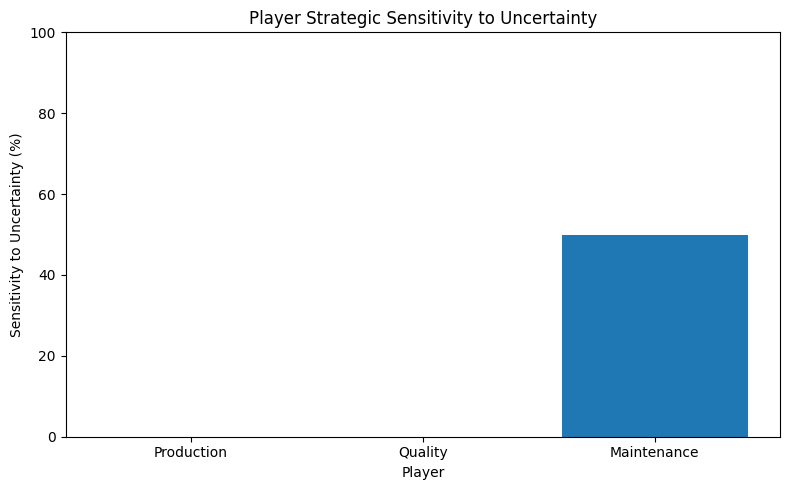

In [52]:
# ============================================================
# BLOCK 59
# PLAYER SENSITIVITY PLOT
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    sensitivity_df["Player"],
    sensitivity_df["Sensitivity %"]
)

plt.xlabel("Player")
plt.ylabel("Sensitivity to Uncertainty (%)")
plt.title(
    "Player Strategic Sensitivity to Uncertainty"
)

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

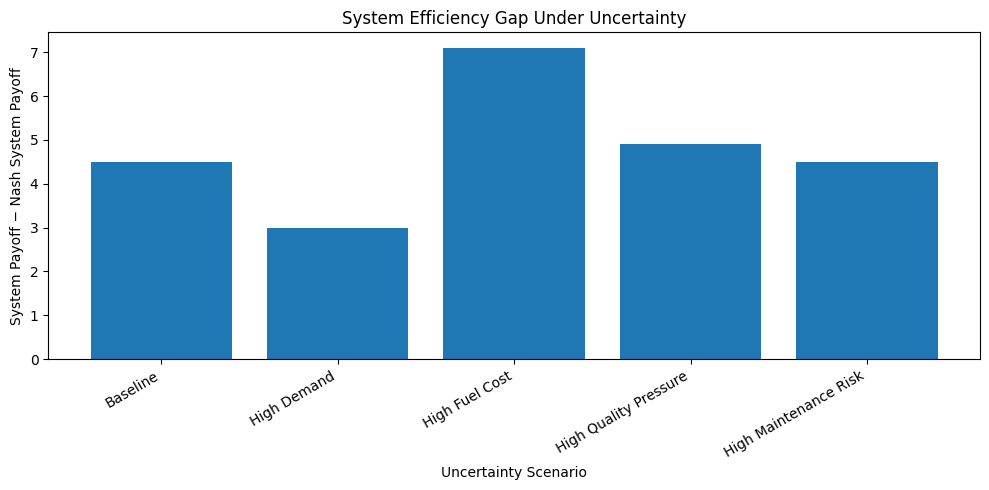

In [53]:
# ============================================================
# PAYOFF GAP PLOT
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.bar(
    scenario_results_df[
        "Scenario"
    ],
    scenario_results_df[
        "Payoff Gap"
    ]
)

plt.xlabel(
    "Uncertainty Scenario"
)

plt.ylabel(
    "System Payoff − Nash System Payoff"
)

plt.title(
    "System Efficiency Gap Under Uncertainty"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()

plt.show()

In [54]:
# ============================================================
# ALIGNMENT SUMMARY
# ============================================================

alignment_summary = scenario_results_df[
    [
        "Scenario",
        "Nash → SO Distance",
        "Payoff Gap",
        "Alignment"
    ]
].copy()

alignment_summary

,Scenario,Nash → SO Distance,Payoff Gap,Alignment
0,Baseline,1,4.5,False
1,High Demand,1,3.0,False
2,High Fuel Cost,1,7.1,False
3,High Quality Pressure,1,4.9,False
4,High Maintenance Risk,1,4.5,False


In [55]:
# ============================================================
# SAVE UNCERTAINTY EXPERIMENT
# ============================================================

uncertainty_report_path = os.path.join(
    OUTPUT_DIR,
    "uncertainty_experiment.xlsx"
)

with pd.ExcelWriter(
    uncertainty_report_path,
    engine="openpyxl"
) as writer:

    scenario_results_df.to_excel(
        writer,
        sheet_name="Scenario Results",
        index=False
    )

    strategy_movement_df.to_excel(
        writer,
        sheet_name="Strategy Movement",
        index=False
    )

    sensitivity_df.to_excel(
        writer,
        sheet_name="Player Sensitivity",
        index=False
    )

    alignment_summary.to_excel(
        writer,
        sheet_name="Alignment",
        index=False
    )

print(
    "Saved:",
    uncertainty_report_path
)

Saved: experiment_reports\uncertainty_experiment.xlsx


In [56]:
# ============================================================
# RESEARCH EXPERIMENT SUMMARY
# ============================================================

print("=" * 70)
print("UNCERTAINTY EXPERIMENT")
print("=" * 70)

for _, row in scenario_results_df.iterrows():

    print(
        f"\nScenario: {row['Scenario']}"
    )

    print(
        f"  Nash: {row['Nash']}"
    )

    print(
        f"  System Optimum: {row['System Optimum']}"
    )

    print(
        f"  Strategy Distance: "
        f"{row['Nash → SO Distance']}"
    )

    print(
        f"  Payoff Gap: "
        f"{row['Payoff Gap']}"
    )

    print(
        f"  Alignment: "
        f"{row['Alignment']}"
    )

UNCERTAINTY EXPERIMENT

Scenario: Baseline
  Nash: (P3, Q3, M3)
  System Optimum: (P2, Q3, M3)
  Strategy Distance: 1
  Payoff Gap: 4.5
  Alignment: False

Scenario: High Demand
  Nash: (P3, Q3, M3)
  System Optimum: (P2, Q3, M3)
  Strategy Distance: 1
  Payoff Gap: 3.0
  Alignment: False

Scenario: High Fuel Cost
  Nash: (P3, Q3, M2)
  System Optimum: (P2, Q3, M2)
  Strategy Distance: 1
  Payoff Gap: 7.099999999999998
  Alignment: False

Scenario: High Quality Pressure
  Nash: (P3, Q3, M3)
  System Optimum: (P2, Q3, M3)
  Strategy Distance: 1
  Payoff Gap: 4.899999999999999
  Alignment: False

Scenario: High Maintenance Risk
  Nash: (P3, Q3, M2)
  System Optimum: (P2, Q3, M2)
  Strategy Distance: 1
  Payoff Gap: 4.5
  Alignment: False


In [57]:
for scenario_name, analysis in scenario_results.items():

    print("\n" + "=" * 70)
    print("Scenario:", scenario_name)

    nash_equilibria = analysis["nash_equilibria"]
    system_optima = analysis["system_optima"]

    print("\nNash × System Optimum:")

    for nash_i, nash in enumerate(nash_equilibria, start=1):

        for so_i, optimum in enumerate(system_optima, start=1):

            distance = calculate_strategy_distance(
                nash,
                optimum,
                players
            )

            nash_payoff = calculate_system_payoff(
                nash,
                players,
                payoff
            )

            so_payoff = calculate_system_payoff(
                optimum,
                players,
                payoff
            )

            print(
                f"  Nash {nash_i} {format_profile(nash, players)}"
                f"  ↔  SO {so_i} {format_profile(optimum, players)}"
            )

            print(
                f"     Distance = {distance}"
            )

            print(
                f"     Nash Payoff = {nash_payoff}"
            )

            print(
                f"     SO Payoff = {so_payoff}"
            )


Scenario: Baseline

Nash × System Optimum:
  Nash 1 (P3, Q3, M3)  ↔  SO 1 (P2, Q3, M3)
     Distance = 1
     Nash Payoff = 29
     SO Payoff = 29

Scenario: High Demand

Nash × System Optimum:
  Nash 1 (P3, Q3, M3)  ↔  SO 1 (P2, Q3, M3)
     Distance = 1
     Nash Payoff = 29
     SO Payoff = 29

Scenario: High Fuel Cost

Nash × System Optimum:
  Nash 1 (P3, Q3, M2)  ↔  SO 1 (P2, Q3, M2)
     Distance = 1
     Nash Payoff = 27
     SO Payoff = 28

Scenario: High Quality Pressure

Nash × System Optimum:
  Nash 1 (P3, Q3, M3)  ↔  SO 1 (P2, Q3, M3)
     Distance = 1
     Nash Payoff = 29
     SO Payoff = 29

Scenario: High Maintenance Risk

Nash × System Optimum:
  Nash 1 (P3, Q3, M2)  ↔  SO 1 (P2, Q3, M2)
     Distance = 1
     Nash Payoff = 27
     SO Payoff = 28


In [58]:
# ============================================================
# COMPARE BASE PAYOFFS WITH UNCERTAIN PAYOFFS
# ============================================================

def compare_payoffs_under_uncertainty(
    base_payoffs,
    uncertain_payoffs,
    players
):

    for profile in base_payoffs:

        base = base_payoffs[profile]
        uncertain = uncertain_payoffs[profile]

        print("\nProfile:", profile)

        for i, player in enumerate(players):

            delta = uncertain[i] - base[i]

            print(
                f"  {player}: "
                f"Base={base[i]:.2f} | "
                f"Uncertain={uncertain[i]:.2f} | "
                f"Delta={delta:+.2f}"
            )

In [59]:
print(type(scenario_results))

if isinstance(scenario_results, dict):
    print("\nScenario names:")
    for name in scenario_results:
        print("-", name)

<class 'dict'>

Scenario names:
- Baseline
- High Demand
- High Fuel Cost
- High Quality Pressure
- High Maintenance Risk


In [60]:
print("\nVariables containing 'payoff':")

for name in dir():
    if "payoff" in name.lower():
        print("-", name)


Variables containing 'payoff':
- build_conflict_payoff
- build_uncertain_payoff
- calculate_system_payoff
- compare_payoffs_under_uncertainty
- create_payoff_function
- high_fuel_payoffs
- nash_payoff
- normalize_payoff_function
- payoff
- payoffs
- scenario_payoffs
- so_payoff
- system_payoff


In [61]:
compare_payoffs_under_uncertainty(
    base_payoffs=payoffs,
    uncertain_payoffs=high_fuel_payoffs,
    players=players
)


Profile: ('P1', 'Q1', 'M1')
  Production: Base=6.00 | Uncertain=5.00 | Delta=-1.00
  Quality: Base=6.00 | Uncertain=5.20 | Delta=-0.80
  Maintenance: Base=6.00 | Uncertain=7.30 | Delta=+1.30

Profile: ('P1', 'Q1', 'M2')
  Production: Base=5.00 | Uncertain=4.30 | Delta=-0.70
  Quality: Base=7.00 | Uncertain=6.20 | Delta=-0.80
  Maintenance: Base=7.00 | Uncertain=9.10 | Delta=+2.10

Profile: ('P1', 'Q1', 'M3')
  Production: Base=4.00 | Uncertain=3.80 | Delta=-0.20
  Quality: Base=5.00 | Uncertain=4.20 | Delta=-0.80
  Maintenance: Base=8.00 | Uncertain=7.40 | Delta=-0.60

Profile: ('P1', 'Q2', 'M1')
  Production: Base=7.00 | Uncertain=6.70 | Delta=-0.30
  Quality: Base=5.00 | Uncertain=5.70 | Delta=+0.70
  Maintenance: Base=7.00 | Uncertain=8.30 | Delta=+1.30

Profile: ('P1', 'Q2', 'M2')
  Production: Base=8.00 | Uncertain=8.00 | Delta=+0.00
  Quality: Base=6.00 | Uncertain=6.70 | Delta=+0.70
  Maintenance: Base=8.00 | Uncertain=10.10 | Delta=+2.10

Profile: ('P1', 'Q2', 'M3')
  Producti

In [62]:
from pprint import pprint

pprint(strategy_uncertainty_effects)

{'Maintenance': {'maintenance_risk': {'high': {'M1': 1.5,
                                               'M2': 2.0,
                                               'M3': -1.0},
                                      'normal': {'M1': 0.0,
                                                 'M2': 0.0,
                                                 'M3': 0.0}}},
 'Production': {'demand': {'high': {'P1': 0.0, 'P2': 0.5, 'P3': 2.0},
                           'low': {'P1': 0.5, 'P2': 0.0, 'P3': -2.0},
                           'normal': {'P1': 0.0, 'P2': 0.0, 'P3': 0.0}},
                'fuel_cost': {'high': {'P1': 0.0, 'P2': -0.5, 'P3': -1.5},
                              'normal': {'P1': 0.0, 'P2': 0.0, 'P3': 0.0}}},
 'Quality': {'quality_pressure': {'high': {'Q1': -0.5, 'Q2': 0.5, 'Q3': 1.5},
                                  'normal': {'Q1': 0.0, 'Q2': 0.0, 'Q3': 0.0}}}}


In [63]:
print("Variables containing 'scenario':")

for name in dir():
    if "scenario" in name.lower():
        print("-", name)

Variables containing 'scenario':
- analyze_scenario
- non_baseline_scenarios
- scenario_name
- scenario_nash
- scenario_payoffs
- scenario_results
- scenario_results_df
- scenario_rows
- scenario_strategy
- total_scenarios
- uncertainty_scenarios


In [64]:
# ============================================================
# TEST
# ============================================================

high_quality_payoffs = build_uncertain_payoff(
    base_payoffs=payoffs,
    players=players,
    uncertainty=uncertainty_scenarios[
        "High Quality Pressure"
    ]
)

print(
    "Profiles:",
    len(high_quality_payoffs)
)

print(
    "Example:",
    high_quality_payoffs[
        ("P2", "Q3", "M2")
    ]
)

Profiles: 27
Example: (9.0, 12.4, 9.0)


In [65]:
# ============================================================
# HIGH QUALITY PRESSURE ANALYSIS
# ============================================================

high_quality_analysis = calculate_full_game_analysis(
    players=players,
    strategies=strategies,
    payoff=high_quality_payoffs
)

print("\n==========================================")
print("HIGH QUALITY PRESSURE ANALYSIS")
print("==========================================")

print("\nNash Equilibria:")

for i, nash in enumerate(
    high_quality_analysis["nash_equilibria"],
    start=1
):
    print(
        f"  Nash {i}:",
        format_profile(nash, players)
    )


print("\nSystem Optima:")

for i, optimum in enumerate(
    high_quality_analysis["system_optima"],
    start=1
):
    print(
        f"  SO {i}:",
        format_profile(optimum, players)
    )


print(
    "\nNash System Payoff:",
    high_quality_analysis["nash_system_payoff"]
)

print(
    "System Payoff:",
    high_quality_analysis["system_payoff"]
)

print(
    "Nash → System Optimum Distance:",
    high_quality_analysis["strategy_distance"]
)

print(
    "Payoff Gap:",
    high_quality_analysis["payoff_gap"]
)

print(
    "Alignment:",
    high_quality_analysis["alignment"]
)


HIGH QUALITY PRESSURE ANALYSIS

Nash Equilibria:
  Nash 1: (P2, Q3, M3)

System Optima:
  SO 1: (P2, Q3, M3)

Nash System Payoff: 31.4
System Payoff: 31.4
Nash → System Optimum Distance: 0
Payoff Gap: 0.0
Alignment: True


In [66]:
for profile, values in high_fuel_payoffs.items():
    system = sum(values)

    if profile == ("P2", "Q3", "M2"):
        print("Profile:", profile)
        print("Player payoffs:", values)
        print("System payoff:", system)

Profile: ('P2', 'Q3', 'M2')
Player payoffs: (8.7, 12.4, 11.3)
System payoff: 32.4


In [67]:
print(
    "Baseline P2-Q3-M2:",
    payoffs[("P2", "Q3", "M2")]
)

print(
    "High Fuel P2-Q3-M2:",
    high_fuel_payoffs[("P2", "Q3", "M2")]
)

Baseline P2-Q3-M2: (9, 10, 9)
High Fuel P2-Q3-M2: (8.7, 12.4, 11.3)


In [68]:
print(
    "P2-Q3 externality:",
    externality_effects
    ["quality_pressure"]
    ["high"]
    ["Production"]
    [("P2", "Q3")]
)

print(
    "P2-Q3 Quality externality:",
    externality_effects
    ["quality_pressure"]
    ["high"]
    ["Quality"]
    [("P2", "Q3")]
)

P2-Q3 externality: -1.0
P2-Q3 Quality externality: 0.0


In [69]:
def build_conflict_payoff(base_payoffs, players):

    conflict_payoffs = {}

    for profile, base_values in base_payoffs.items():

        profile_dict = dict(zip(players, profile))

        p = profile_dict["Production"]
        q = profile_dict["Quality"]
        m = profile_dict["Maintenance"]

        production, quality, maintenance = base_values

        # =====================================================
        # 1. Production individual incentive
        # =====================================================

        production_incentive = {
            "P1": 0.0,
            "P2": 0.5,
            "P3": 5.0
        }

        production += production_incentive[p]

        # =====================================================
        # 2. Quality externality
        # =====================================================

        quality_externality = {

            "P1": {
                "Q1": 0.0,
                "Q2": 0.0,
                "Q3": 0.0
            },

            "P2": {
                "Q1": 0.0,
                "Q2": 0.0,
                "Q3": 0.0
            },

            "P3": {
                "Q1": -3.0,
                "Q2": -4.0,
                "Q3": -5.0
            }
        }

        quality += quality_externality[p][q]

        # =====================================================
        # 3. Maintenance externality
        # =====================================================

        maintenance_externality = {

            "P1": {
                "M1": 0.0,
                "M2": 0.0,
                "M3": 0.0
            },

            "P2": {
                "M1": 0.0,
                "M2": 0.0,
                "M3": 0.0
            },

            "P3": {
                "M1": -2.0,
                "M2": -3.0,
                "M3": -4.0
            }
        }

        maintenance += maintenance_externality[p][m]

        conflict_payoffs[profile] = (
            round(production, 3),
            round(quality, 3),
            round(maintenance, 3)
        )

    return conflict_payoffs

In [70]:
conflict_payoffs = build_conflict_payoff(
    base_payoffs=payoffs,
    players=players
)

In [71]:
conflict_payoff_function = create_payoff_function(
    conflict_payoffs,
    players
)

In [72]:
conflict_analysis = calculate_full_game_analysis(
    players=players,
    strategies=strategies,
    payoff=conflict_payoff_function
)

In [73]:
# ============================================================
# CONFLICT EXPERIMENT SUMMARY
# ============================================================

CONFLICT_EXPERIMENT_NAME = (
    "Strategic Conflict Test"
)

RESEARCHER_AR = "وسيم سعيد"
SUPERVISOR = "Dr. Mahmoud Hannawi"
SUPERVISOR_AR = "د. محمود حناوي"

THESIS_TITLE_AR = (
    "تحسين أداء خطوط الإنتاج تحت عدم اليقين باستخدام نظرية الألعاب والتوأم الرقمي"
)


def build_conflict_summary():

    nash = conflict_analysis["nash_equilibrium"]
    system_optimum = conflict_analysis["system_optimum"]

    return {

        "Experiment":
            CONFLICT_EXPERIMENT_NAME,

        "Nash":
            format_profile(
                nash,
                players
            ),

        "System Optimum":
            format_profile(
                system_optimum,
                players
            ),

        "Strategy Distance":
            conflict_analysis[
                "strategy_distance"
            ],

        "Payoff Gap":
            conflict_analysis[
                "payoff_gap"
            ],

        "Alignment":
            conflict_analysis[
                "alignment"
            ],

        "Nash System Payoff":
            conflict_analysis[
                "nash_system_payoff"
            ],

        "System Payoff":
            conflict_analysis[
                "system_payoff"
            ]
    }


conflict_summary = build_conflict_summary()

print("=" * 70)
print("CONFLICT EXPERIMENT")
print("=" * 70)

for key, value in conflict_summary.items():
    print(f"{key}: {value}")

CONFLICT EXPERIMENT
Experiment: Strategic Conflict Test
Nash: (P3, Q3, M3)
System Optimum: (P2, Q3, M3)
Strategy Distance: 1
Payoff Gap: 4.5
Alignment: False
Nash System Payoff: 25.0
System Payoff: 29.5


In [74]:
print("Nash:", conflict_analysis["nash_equilibrium"])
print("System Optimum:", conflict_analysis["system_optimum"])
print("Strategy Distance:", conflict_analysis["strategy_distance"])
print("Payoff Gap:", conflict_analysis["payoff_gap"])
print("Alignment:", conflict_analysis["alignment"])

Nash: {'Production': 'P3', 'Quality': 'Q3', 'Maintenance': 'M3'}
System Optimum: {'Production': 'P2', 'Quality': 'Q3', 'Maintenance': 'M3'}
Strategy Distance: 1
Payoff Gap: 4.5
Alignment: False


In [75]:
print("\n--- ALL CONFLICT PROFILES ---")

for profile, values in conflict_payoffs.items():

    system_payoff = sum(values)

    marker = []

    if profile in conflict_analysis["nash_equilibria"]:
        marker.append("NASH")

    if profile in conflict_analysis["system_optima"]:
        marker.append("SYSTEM OPTIMUM")

    print(
        profile,
        "→",
        values,
        "System =",
        round(system_payoff, 3),
        (" ← " + " + ".join(marker) if marker else "")
    )


--- ALL CONFLICT PROFILES ---
('P1', 'Q1', 'M1') → (6.0, 6.0, 6.0) System = 18.0 
('P1', 'Q1', 'M2') → (5.0, 7.0, 7.0) System = 19.0 
('P1', 'Q1', 'M3') → (4.0, 5.0, 8.0) System = 17.0 
('P1', 'Q2', 'M1') → (7.0, 5.0, 7.0) System = 19.0 
('P1', 'Q2', 'M2') → (8.0, 6.0, 8.0) System = 22.0 
('P1', 'Q2', 'M3') → (6.0, 7.0, 9.0) System = 22.0 
('P1', 'Q3', 'M1') → (5.0, 8.0, 6.0) System = 19.0 
('P1', 'Q3', 'M2') → (7.0, 9.0, 8.0) System = 24.0 
('P1', 'Q3', 'M3') → (6.0, 10.0, 9.0) System = 25.0 
('P2', 'Q1', 'M1') → (8.5, 6.0, 5.0) System = 19.5 
('P2', 'Q1', 'M2') → (9.5, 7.0, 7.0) System = 23.5 
('P2', 'Q1', 'M3') → (7.5, 6.0, 8.0) System = 21.5 
('P2', 'Q2', 'M1') → (9.5, 8.0, 7.0) System = 24.5 
('P2', 'Q2', 'M2') → (10.5, 9.0, 8.0) System = 27.5 
('P2', 'Q2', 'M3') → (8.5, 8.0, 9.0) System = 25.5 
('P2', 'Q3', 'M1') → (8.5, 9.0, 7.0) System = 24.5 
('P2', 'Q3', 'M2') → (9.5, 10.0, 9.0) System = 28.5 
('P2', 'Q3', 'M3') → (8.5, 11.0, 10.0) System = 29.5 
('P3', 'Q1', 'M1') → (12.0, 

In [76]:
# ============================================================
# ENGINEERING REPORT LANGUAGE
# ============================================================

PLAYER_NAMES_AR = {
    "Production": "الإنتاج",
    "Quality": "الجودة",
    "Maintenance": "الصيانة",
}


STRATEGY_ACTIONS_AR = {
    "P1": "الاستمرار في تشغيل الخط رغم الانحراف",
    "P2": "خفض سرعة الخط",
    "P3": "إيقاف الخط",

    "Q1": "قبول نسبة محدودة من العيوب",
    "Q2": "إعادة تشغيل الوحدات المعيبة",
    "Q3": "إيقاف الخط عند تكرار العيب",

    "M1": "تنفيذ صيانة تصحيحية",
    "M2": "تنفيذ صيانة وقائية",
    "M3": "تنفيذ صيانة تنبؤية",
}


UNCERTAINTY_NAMES_AR = {
    "demand": "الطلب",
    "fuel_cost": "تكلفة الوقود",
    "quality_pressure": "ضغط الجودة",
    "maintenance_risk": "مخاطر الصيانة",
}

UNCERTAINTY_AR = {

    "demand": {
        "name": "الطلب",
        "increase": "ارتفع",
        "decrease": "انخفض",
    },

    "fuel_cost": {
        "name": "تكلفة الوقود",
        "increase": "ارتفعت",
        "decrease": "انخفضت",
    },

    "quality_pressure": {
        "name": "ضغط الجودة",
        "increase": "ارتفع",
        "decrease": "انخفض",
    },

    "maintenance_risk": {
        "name": "مخاطر الصيانة",
        "increase": "ارتفعت",
        "decrease": "انخفضت",
    },
}

def player_name_ar(player):
    return PLAYER_NAMES_AR.get(player, player)


def strategy_action(strategy):
    return STRATEGY_ACTIONS_AR.get(strategy, strategy)


def uncertainty_name_ar(variable):
    return UNCERTAINTY_NAMES_AR.get(variable, variable)

In [77]:
def describe_uncertainty_change_ar(change):

    variable = UNCERTAINTY_AR[
        change["variable"]
    ]

    baseline = change["baseline"]
    scenario = change["scenario"]

    if scenario > baseline:

        verb = variable["increase"]

    else:

        verb = variable["decrease"]

    return (
        f"{verb} {variable['name']} "
        f"من {baseline:.2f} إلى {scenario:.2f}"
    )

In [78]:
# ============================================================
# UNCERTAINTY COMPARISON
# ============================================================

def compare_uncertainty(
    baseline_uncertainty,
    scenario_uncertainty
):
    changes = []

    for variable, baseline_value in baseline_uncertainty.items():

        scenario_value = scenario_uncertainty.get(
            variable,
            baseline_value
        )

        if scenario_value != baseline_value:

            changes.append({
                "variable": variable,
                "baseline": baseline_value,
                "scenario": scenario_value,
                "delta": scenario_value - baseline_value
            })

    return changes

In [79]:
# ============================================================
# UNCERTAINTY LANGUAGE
# ============================================================

def describe_uncertainty_change(change):

    variable = uncertainty_name_ar(
        change["variable"]
    )

    baseline = change["baseline"]
    scenario = change["scenario"]

    if scenario > baseline:

        return (
            f"ارتفع {variable} من "
            f"{baseline:g} إلى {scenario:g}"
        )

    else:

        return (
            f"انخفض {variable} من "
            f"{baseline:g} إلى {scenario:g}"
        )

In [80]:
# ============================================================
# OPERATIONAL STRATEGY CHANGES
# ============================================================

def detect_strategy_changes(result):

    nash = result["nash_equilibrium"]
    system = result["system_optimum"]

    changes = []

    for player in nash:

        nash_strategy = nash[player]
        system_strategy = system[player]

        if nash_strategy != system_strategy:

            changes.append({
                "player": player,
                "from": nash_strategy,
                "to": system_strategy,
                "from_action": strategy_action(
                    nash_strategy
                ),
                "to_action": strategy_action(
                    system_strategy
                )
            })

    return changes

In [81]:
# ============================================================
# OPERATING STATE DESCRIPTION
# ============================================================

def describe_operating_state(profile):

    state = []

    for player, strategy in profile.items():

        state.append({
            "player": player,
            "name": player_name_ar(player),
            "strategy": strategy,
            "action": strategy_action(strategy)
        })

    return state

In [82]:
# ============================================================
# BASELINE OPERATIONAL COMPARISON
# ============================================================

def compare_profiles(
    baseline_profile,
    scenario_profile
):
    """
    Detects operational strategy changes
    between baseline and a scenario.
    """

    changes = []

    for player in baseline_profile:

        baseline_strategy = baseline_profile[player]
        scenario_strategy = scenario_profile[player]

        if baseline_strategy != scenario_strategy:

            changes.append({
                "player": player,
                "from": baseline_strategy,
                "to": scenario_strategy,
                "from_action": strategy_action(
                    baseline_strategy
                ),
                "to_action": strategy_action(
                    scenario_strategy
                )
            })

    return changes

In [83]:
def describe_uncertainty_changes(changes):

    if not changes:
        return None

    descriptions = []

    for change in changes:

        variable = uncertainty_name_ar(
            change["variable"]
        )

        baseline = change["baseline"]
        scenario = change["scenario"]

        if scenario > baseline:

            text = (
                f"ارتفع {variable} "
                f"من {baseline:g} إلى {scenario:g}"
            )

        else:

            text = (
                f"انخفض {variable} "
                f"من {baseline:g} إلى {scenario:g}"
            )

        descriptions.append(text)

    if len(descriptions) == 1:

        return descriptions[0] + "."

    return (
        "، ".join(descriptions[:-1])
        + "، و"
        + descriptions[-1]
        + "."
    )

In [84]:
def classify_engineering_result(analysis):

    if analysis["scenario"] == "Baseline":
        return "BASELINE"

    decision_changed = len(
        analysis["decision_changes"]
    ) > 0

    aligned = analysis["aligned"]

    if decision_changed and aligned:
        return "DECISION_CHANGED_AND_ALIGNED"

    if not decision_changed and aligned:
        return "DECISION_UNCHANGED_AND_ALIGNED"

    if decision_changed and not aligned:
        return "DECISION_CHANGED_BUT_MISALIGNED"

    return "DECISION_UNCHANGED_BUT_MISALIGNED"

In [85]:
def describe_operational_changes(changes):

    if not changes:
        return None

    sentences = []

    for change in changes:

        player = player_name_ar(
            change["player"]
        )

        sentence = (
            f"تغير قرار مركز {player} "
            f"من {change['from_action']} "
            f"إلى {change['to_action']}"
        )

        sentences.append(sentence)

    return "، ".join(sentences) + "."

In [86]:
def build_engineering_analysis(result, baseline_result):

    scenario_name = result["scenario"]

    baseline_uncertainty = baseline_result["uncertainty"]
    scenario_uncertainty = result["uncertainty"]

    baseline_nash = baseline_result["nash_equilibrium"]
    current_nash = result["nash_equilibrium"]
    system_optimum = result["system_optimum"]

    # --------------------------------------------------------
    # 1. تغير ظروف التشغيل
    # --------------------------------------------------------

    uncertainty_changes = compare_uncertainty(
        baseline_uncertainty,
        scenario_uncertainty
    )

    # --------------------------------------------------------
    # 2. تغير القرارات مقارنة بحالة الأساس
    # --------------------------------------------------------

    decision_changes = compare_profiles(
        baseline_nash,
        current_nash
    )

    # --------------------------------------------------------
    # 3. الفرق بين الحالة الناتجة والحالة الأفضل
    # --------------------------------------------------------

    optimum_changes = detect_strategy_changes(result)

    # --------------------------------------------------------
    # 4. مؤشرات الأداء
    # --------------------------------------------------------

    baseline_payoff = float(
        baseline_result["nash_system_payoff"]
    )

    current_payoff = float(
        result["nash_system_payoff"]
    )

    system_payoff = float(
        result["system_payoff"]
    )

    payoff_gap = float(
        result["payoff_gap"]
    )

    performance_change = current_payoff - baseline_payoff

    strategy_distance = int(
        result["strategy_distance"]
    )

    # --------------------------------------------------------
    # 5. المراكز التي غيرت قراراتها
    # --------------------------------------------------------

    changed_centers = [
        player_name_ar(change["player"])
        for change in decision_changes
    ]

    # --------------------------------------------------------
    # 6. المراكز التي تحتاج تعديل للوصول للحالة الأفضل
    # --------------------------------------------------------

    corrective_centers = [
        player_name_ar(change["player"])
        for change in optimum_changes
    ]

    # --------------------------------------------------------
    # 7. حالة التوافق
    # --------------------------------------------------------

    aligned = (
        strategy_distance == 0
        and payoff_gap == 0
    )

    analysis = {
        "scenario": scenario_name,
    
        "uncertainty_changes": uncertainty_changes,
    
        "decision_changes": decision_changes,
    
        "optimum_changes": optimum_changes,
    
        "changed_centers": changed_centers,
    
        "corrective_centers": corrective_centers,
    
        "baseline_payoff": baseline_payoff,
    
        "current_payoff": current_payoff,
    
        "system_payoff": system_payoff,
    
        "performance_change": performance_change,
    
        "payoff_gap": payoff_gap,
    
        "strategy_distance": strategy_distance,
    
        "aligned": aligned,
    
        "baseline_state": baseline_nash,
    
        "current_state": current_nash,
    
        "system_optimum": system_optimum,
    }
    
    analysis["result_type"] = classify_engineering_result(
        analysis
    )
    
    return analysis

In [87]:
def build_experiment_record(result, baseline_result):

    analysis = build_engineering_analysis(
        result,
        baseline_result
    )

    return {
        "scenario": analysis["scenario"],

        "result_type": analysis["result_type"],

        "uncertainty_changes":
            analysis["uncertainty_changes"],

        "decision_changes":
            analysis["decision_changes"],

        "current_state":
            analysis["current_state"],

        "system_optimum":
            analysis["system_optimum"],

        "performance": {
            "baseline": analysis["baseline_payoff"],
            "current": analysis["current_payoff"],
            "system_optimum":
                analysis["system_payoff"],
            "change":
                analysis["performance_change"],
            "gap":
                analysis["payoff_gap"],
        },

        "operational_distance":
            analysis["strategy_distance"],

        "alignment":
            analysis["aligned"],

        "corrective_centers":
            analysis["corrective_centers"],
    }

In [88]:
def build_conflict_experiment_record(
    conflict_analysis,
    baseline_result
):

    baseline_nash = baseline_result["nash_equilibrium"]
    current_nash = conflict_analysis["nash_equilibrium"]
    system_optimum = conflict_analysis["system_optimum"]

    # --------------------------------------------------------
    # Baseline → Conflict Nash
    # --------------------------------------------------------

    decision_changes = compare_profiles(
        baseline_nash,
        current_nash
    )

    # --------------------------------------------------------
    # Nash → System Optimum
    # --------------------------------------------------------

    optimum_changes = []

    for player in current_nash:

        nash_strategy = current_nash[player]
        optimum_strategy = system_optimum[player]

        if nash_strategy != optimum_strategy:

            optimum_changes.append({
                "player": player,
                "from": nash_strategy,
                "to": optimum_strategy,
                "from_action": strategy_action(nash_strategy),
                "to_action": strategy_action(optimum_strategy),
            })

    # --------------------------------------------------------
    # Performance
    # --------------------------------------------------------

    baseline_payoff = round(
        float(baseline_result["nash_system_payoff"]),
        2
    )

    current_payoff = round(
        float(conflict_analysis["nash_system_payoff"]),
        2
    )

    system_payoff = round(
        float(conflict_analysis["system_payoff"]),
        2
    )

    performance_change = round(
        current_payoff - baseline_payoff,
        2
    )

    payoff_gap = round(
        float(conflict_analysis["payoff_gap"]),
        2
    )

    strategy_distance = int(
        conflict_analysis["strategy_distance"]
    )

    aligned = bool(
        conflict_analysis["alignment"]
    )

    # --------------------------------------------------------
    # Classification
    # --------------------------------------------------------

    temp_analysis = {
        "scenario": CONFLICT_EXPERIMENT_NAME,
        "decision_changes": decision_changes,
        "aligned": aligned,
    }

    result_type = classify_engineering_result(
        temp_analysis
    )

    # --------------------------------------------------------
    # Final Engineering Experiment Record
    # --------------------------------------------------------

    return {

        "scenario":
            CONFLICT_EXPERIMENT_NAME,

        "result_type":
            result_type,

        "uncertainty_changes":
            [],

        "decision_changes":
            decision_changes,

        "current_state":
            current_nash,

        "system_optimum":
            system_optimum,

        "performance": {

            "baseline":
                baseline_payoff,

            "current":
                current_payoff,

            "system_optimum":
                system_payoff,

            "change":
                performance_change,

            "gap":
                payoff_gap,
        },

        "operational_distance":
            strategy_distance,

        "alignment":
            aligned,

        "corrective_centers": [
            player_name_ar(
                change["player"]
            )
            for change in optimum_changes
        ],
    }

In [89]:
def get_corrective_strategy_changes(record):

    current = record["current_state"]
    optimum = record["system_optimum"]

    changes = []

    for player in current:

        if current[player] != optimum[player]:

            changes.append(
                f"{player_name_ar(player)}: "
                f"{current[player]} → {optimum[player]}"
            )

    return changes

In [90]:
# ============================================================
# CELL 116 — add_engineering_narrative_box
# FIX: Use arabic_reshaper directly (no bidi reorder).
# ReportLab handles RTL through wordWrap='RTL'.
# ============================================================

def add_engineering_narrative_box(
    story,
    result,
    baseline_result,
    styles
):
    """
    Add a complete engineering narrative box to the PDF story.
    Uses proper Arabic rendering (reshape only, no get_display).
    """

    paragraphs = generate_engineering_narrative(
        result,
        baseline_result
    )

    if not paragraphs:
        return

    narrative_style = ParagraphStyle(
        "EngineeringNarrative",
        parent=styles["Normal"],
        fontName="ArabicFont",
        fontSize=10.5,
        leading=20,
        alignment=TA_RIGHT,
        spaceAfter=8,
        rightIndent=0,
        leftIndent=0,
    )

    box_content = []

    for paragraph in paragraphs:

        try:
            reshaped = arabic_reshaper.reshape(
                str(paragraph)
            )
        except Exception:
            reshaped = str(paragraph)

        # Escape XML-sensitive chars AFTER reshape
        reshaped = (
            reshaped
            .replace("&", "&amp;")
            .replace("<", "&lt;")
            .replace(">", "&gt;")
        )

        box_content.append(
            Paragraph(reshaped, narrative_style)
        )

    narrative_table = Table(
        [[box_content]],
        colWidths=[450],
    )

    narrative_table.setStyle(
        TableStyle([
            ("BOX", (0, 0), (-1, -1), 1, colors.black),
            ("BACKGROUND", (0, 0), (-1, -1), colors.whitesmoke),
            ("LEFTPADDING", (0, 0), (-1, -1), 14),
            ("RIGHTPADDING", (0, 0), (-1, -1), 14),
            ("TOPPADDING", (0, 0), (-1, -1), 12),
            ("BOTTOMPADDING", (0, 0), (-1, -1), 12),
            ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ])
    )

    story.append(narrative_table)
    story.append(Spacer(1, 14))

In [91]:
# ============================================================
# CELL 92 (REPLACED)
# ENGLISH ENGINEERING NARRATIVE GENERATOR
# ============================================================

def generate_engineering_narrative(result, baseline_result):
    """
    Generate an English academic engineering narrative for a
    single uncertainty scenario.

    The narrative follows the structure:
      1. External condition
      2. Strategic response
      3. Resulting operating state
      4. System-optimal reference
      5. Strategic distance and payoff gap
      6. Engineering interpretation
    """
    analysis = build_engineering_analysis(result, baseline_result)
    paragraphs = []

    scenario = analysis["scenario"]
    uncertainty_changes = analysis["uncertainty_changes"]
    decision_changes = analysis["decision_changes"]
    optimum_changes = analysis["optimum_changes"]
    current_state = analysis["current_state"]
    current_payoff = analysis["current_payoff"]
    system_payoff = analysis["system_payoff"]
    baseline_payoff = analysis["baseline_payoff"]
    performance_change = analysis["performance_change"]
    payoff_gap = analysis["payoff_gap"]
    distance = analysis["strategy_distance"]

    # --------------------------------------------------------
    # 1. Baseline scenario
    # --------------------------------------------------------
    if scenario == "Baseline":
        paragraphs.append(
            "This scenario defines the baseline operating "
            "condition of the production line. It is used as "
            "the reference against which the effect of "
            "uncertainty on strategic behavior is measured."
        )
        return paragraphs

    # --------------------------------------------------------
    # 2. External condition
    # --------------------------------------------------------
    if uncertainty_changes:
        descriptions = []
        for change in uncertainty_changes:
            variable = change["variable"].replace("_", " ")
            b = change["baseline"]
            s = change["scenario"]
            if s > b:
                descriptions.append(
                    f"{variable} increased from {b:.2f} to {s:.2f}"
                )
            elif s < b:
                descriptions.append(
                    f"{variable} decreased from {b:.2f} to {s:.2f}"
                )
        if len(descriptions) == 1:
            unc_text = descriptions[0] + "."
        else:
            unc_text = (
                ", ".join(descriptions[:-1])
                + ", and " + descriptions[-1] + "."
            )
        paragraphs.append(
            "Under this scenario, the external operating "
            "condition changes: " + unc_text
        )

    # --------------------------------------------------------
    # 3. Strategic response
    # --------------------------------------------------------
    if decision_changes:
        sentences = []
        for change in decision_changes:
            center = change["player"]
            sentences.append(
                f"the {center} responsibility center shifted "
                f"from {change['from']} to {change['to']}"
            )
        if len(sentences) == 1:
            decision_text = sentences[0] + "."
        else:
            decision_text = "; ".join(sentences) + "."
        paragraphs.append(
            "In response to this change, " + decision_text
        )
    else:
        paragraphs.append(
            "The uncertainty condition did not change the Nash "
            "strategy of any responsibility center relative to "
            "the baseline, so the operating state remained "
            "unchanged."
        )

    # --------------------------------------------------------
    # 4. Resulting operating state
    # --------------------------------------------------------
    if current_state:
        state_parts = [
            f"{p} = {s}" for p, s in current_state.items()
        ]
        paragraphs.append(
            "The resulting Nash operating profile is: "
            + ", ".join(state_parts) + "."
        )

    # --------------------------------------------------------
    # 5. Performance change
    # --------------------------------------------------------
    if scenario != "Baseline":
        if performance_change > 0:
            paragraphs.append(
                f"The aggregate system payoff increased from "
                f"{baseline_payoff:.2f} at baseline to "
                f"{current_payoff:.2f} under this scenario "
                f"(+{performance_change:.2f})."
            )
        elif performance_change < 0:
            paragraphs.append(
                f"The aggregate system payoff decreased from "
                f"{baseline_payoff:.2f} at baseline to "
                f"{current_payoff:.2f} under this scenario "
                f"({performance_change:.2f})."
            )
        else:
            paragraphs.append(
                "The aggregate system payoff remained "
                "unchanged relative to the baseline."
            )

    # --------------------------------------------------------
    # 6. Comparison with system optimum
    # --------------------------------------------------------
    if not optimum_changes:
        paragraphs.append(
            "The Nash equilibrium coincides with the system "
            "optimum under this scenario. No corrective "
            "operational change is required."
        )
    else:
        corrections = []
        for change in optimum_changes:
            corrections.append(
                f"the {change['player']} responsibility center "
                f"should shift from {change['from']} to "
                f"{change['to']}"
            )
        correction_text = "; ".join(corrections) + "."
        paragraphs.append(
            "The Nash equilibrium does not coincide with the "
            "system optimum. To reach the system-optimal "
            "profile, " + correction_text
        )

    # --------------------------------------------------------
    # 7. Strategic distance and payoff gap
    # --------------------------------------------------------
    if payoff_gap == 0 and distance == 0:
        paragraphs.append(
            f"The Nash system payoff is {current_payoff:.2f}, "
            f"which equals the system-optimal payoff. The "
            f"strategic distance is zero."
        )
    else:
        paragraphs.append(
            f"The Nash system payoff is {current_payoff:.2f} "
            f"against a system-optimal payoff of "
            f"{system_payoff:.2f}, giving a payoff gap of "
            f"{payoff_gap:.2f}. The strategic distance "
            f"between the two profiles is {distance}."
        )

    # --------------------------------------------------------
    # 8. Engineering interpretation
    # --------------------------------------------------------
    if optimum_changes:
        affected = ", ".join(
            c["player"] for c in optimum_changes
        )
        paragraphs.append(
            f"From an engineering perspective, the "
            f"misalignment is concentrated in the {affected} "
            f"responsibility center. The external uncertainty "
            f"condition generated an individual incentive that "
            f"is not compatible with the aggregate system "
            f"objective."
        )
    else:
        paragraphs.append(
            "From an engineering perspective, the "
            "responsibility centers selected strategies that "
            "are consistent with the aggregate system "
            "objective under this uncertainty condition."
        )

    return paragraphs

In [92]:
# ============================================================
# NEW CELL — Define baseline_result BEFORE cell 93
# ============================================================
baseline_result = scenario_results["Baseline"]
print("Baseline Result Ready:")
print("  Nash:", format_profile(
    baseline_result["nash_equilibrium"], players
))
print("  System Optimum:", format_profile(
    baseline_result["system_optimum"], players
))
print("  Nash Payoff:", baseline_result["nash_system_payoff"])
print("  System Payoff:", baseline_result["system_payoff"])

Baseline Result Ready:
  Nash: (P3, Q3, M3)
  System Optimum: (P2, Q3, M3)
  Nash Payoff: 25.0
  System Payoff: 29.5


In [93]:
conflict_record = build_conflict_experiment_record(
    conflict_analysis,
    baseline_result
)

In [94]:
baseline_result = scenario_results["Baseline"]

experiment_records = {}

for scenario_name, result in scenario_results.items():
    experiment_records[scenario_name] = \
        build_experiment_record(
            result,
            baseline_result
        )

In [95]:
experiment_records["Controlled Conflict"] = conflict_record

In [96]:
import pandas as pd

experiment_rows = []

for scenario, record in experiment_records.items():

    current = record["current_state"]
    optimum = record["system_optimum"]
    performance = record["performance"]

    experiment_rows.append({

        "Scenario":
            scenario,

        "Result Type":
            record["result_type"],

        "Production":
            current["Production"],

        "Quality":
            current["Quality"],

        "Maintenance":
            current["Maintenance"],

        "System Production":
            optimum["Production"],

        "System Quality":
            optimum["Quality"],

        "System Maintenance":
            optimum["Maintenance"],

        "Baseline Performance":
            round(performance["baseline"], 2),

        "Current Performance":
            round(performance["current"], 2),

        "System Optimum Performance":
            round(performance["system_optimum"], 2),

        "Performance Change":
            round(performance["change"], 2),

        "Performance Gap":
            round(performance["gap"], 2),

        "Operational Distance":
            record["operational_distance"],

        "Alignment":
            record["alignment"],

        "Corrective Centers":
            ", ".join(
                record["corrective_centers"]
            ),
    })


experiment_df = pd.DataFrame(
    experiment_rows
)

experiment_df["Corrective Strategy Changes"] = [
    "؛ ".join(
        get_corrective_strategy_changes(record)
    )
    for record in experiment_records.values()
]

experiment_df["Corrective Centers Count"] = [
    len(
        get_corrective_strategy_changes(record)
    )
    for record in experiment_records.values()
]

experiment_df

,Scenario,Result Type,Production,Quality,Maintenance,System Production,System Quality,System Maintenance,Baseline Performance,Current Performance,System Optimum Performance,Performance Change,Performance Gap,Operational Distance,Alignment,Corrective Centers,Corrective Strategy Changes,Corrective Centers Count
0,Baseline,BASELINE,P3,Q3,M3,P2,Q3,M3,25.0,25.0,29.5,0.0,4.5,1,False,الإنتاج,الإنتاج: P3 → P2,1
1,High Demand,DECISION_UNCHANGED_BUT_MISALIGNED,P3,Q3,M3,P2,Q3,M3,25.0,27.0,30.0,2.0,3.0,1,False,الإنتاج,الإنتاج: P3 → P2,1
2,High Fuel Cost,DECISION_CHANGED_BUT_MISALIGNED,P3,Q3,M2,P2,Q3,M2,25.0,25.8,32.9,0.8,7.1,1,False,الإنتاج,الإنتاج: P3 → P2,1
3,High Quality Pressure,DECISION_UNCHANGED_BUT_MISALIGNED,P3,Q3,M3,P2,Q3,M3,25.0,27.0,31.9,2.0,4.9,1,False,الإنتاج,الإنتاج: P3 → P2,1
4,High Maintenance Risk,DECISION_CHANGED_BUT_MISALIGNED,P3,Q3,M2,P2,Q3,M2,25.0,26.0,30.5,1.0,4.5,1,False,الإنتاج,الإنتاج: P3 → P2,1
5,Controlled Conflict,DECISION_UNCHANGED_BUT_MISALIGNED,P3,Q3,M3,P2,Q3,M3,25.0,25.0,29.5,0.0,4.5,1,False,الإنتاج,الإنتاج: P3 → P2,1


In [97]:
engineering_matrix = experiment_df[
    [
        "Scenario",
        "Result Type",
        "Production",
        "Quality",
        "Maintenance",
        "System Production",
        "System Quality",
        "System Maintenance",
        "Performance Change",
        "Performance Gap",
        "Operational Distance",
        "Alignment",
        "Corrective Strategy Changes",
        "Corrective Centers Count",
    ]
]

engineering_matrix

,Scenario,Result Type,Production,Quality,Maintenance,System Production,System Quality,System Maintenance,Performance Change,Performance Gap,Operational Distance,Alignment,Corrective Strategy Changes,Corrective Centers Count
0,Baseline,BASELINE,P3,Q3,M3,P2,Q3,M3,0.0,4.5,1,False,الإنتاج: P3 → P2,1
1,High Demand,DECISION_UNCHANGED_BUT_MISALIGNED,P3,Q3,M3,P2,Q3,M3,2.0,3.0,1,False,الإنتاج: P3 → P2,1
2,High Fuel Cost,DECISION_CHANGED_BUT_MISALIGNED,P3,Q3,M2,P2,Q3,M2,0.8,7.1,1,False,الإنتاج: P3 → P2,1
3,High Quality Pressure,DECISION_UNCHANGED_BUT_MISALIGNED,P3,Q3,M3,P2,Q3,M3,2.0,4.9,1,False,الإنتاج: P3 → P2,1
4,High Maintenance Risk,DECISION_CHANGED_BUT_MISALIGNED,P3,Q3,M2,P2,Q3,M2,1.0,4.5,1,False,الإنتاج: P3 → P2,1
5,Controlled Conflict,DECISION_UNCHANGED_BUT_MISALIGNED,P3,Q3,M3,P2,Q3,M3,0.0,4.5,1,False,الإنتاج: P3 → P2,1


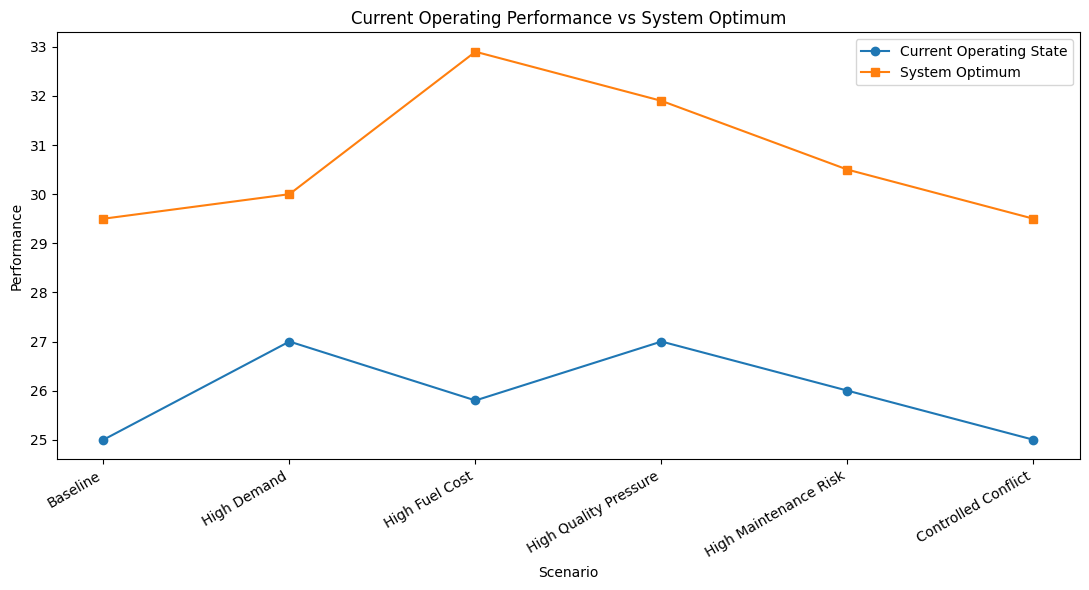

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

x = range(len(experiment_df))

plt.plot(
    x,
    experiment_df["Current Performance"],
    marker="o",
    label="Current Operating State"
)

plt.plot(
    x,
    experiment_df["System Optimum Performance"],
    marker="s",
    label="System Optimum"
)

plt.xticks(
    x,
    experiment_df["Scenario"],
    rotation=30,
    ha="right"
)

plt.xlabel("Scenario")
plt.ylabel("Performance")

plt.title(
    "Current Operating Performance vs System Optimum"
)

plt.legend()
plt.tight_layout()
plt.show()

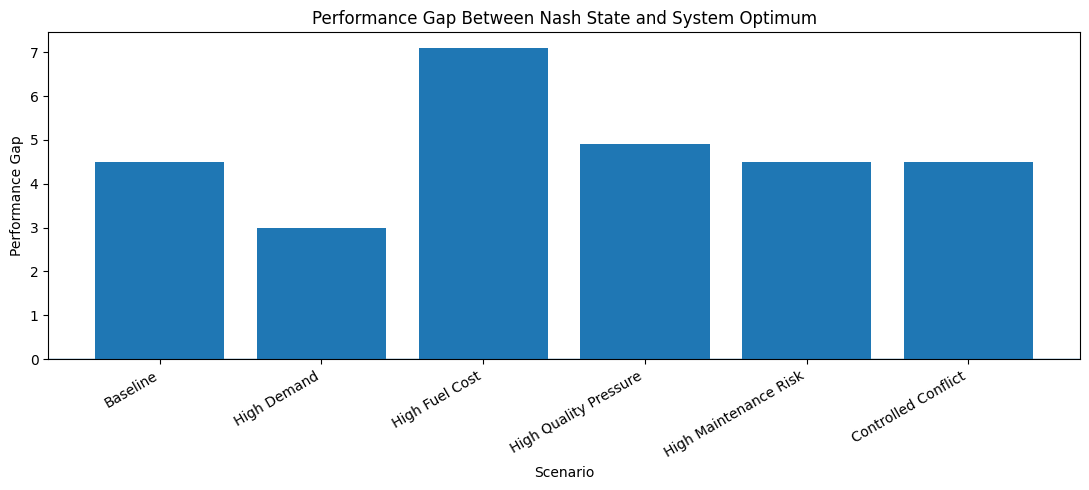

In [99]:
plt.figure(figsize=(11, 5))

plt.bar(
    experiment_df["Scenario"],
    experiment_df["Performance Gap"]
)

plt.xlabel("Scenario")
plt.ylabel("Performance Gap")

plt.title(
    "Performance Gap Between Nash State and System Optimum"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.axhline(
    0,
    linewidth=1
)

plt.tight_layout()
plt.show()

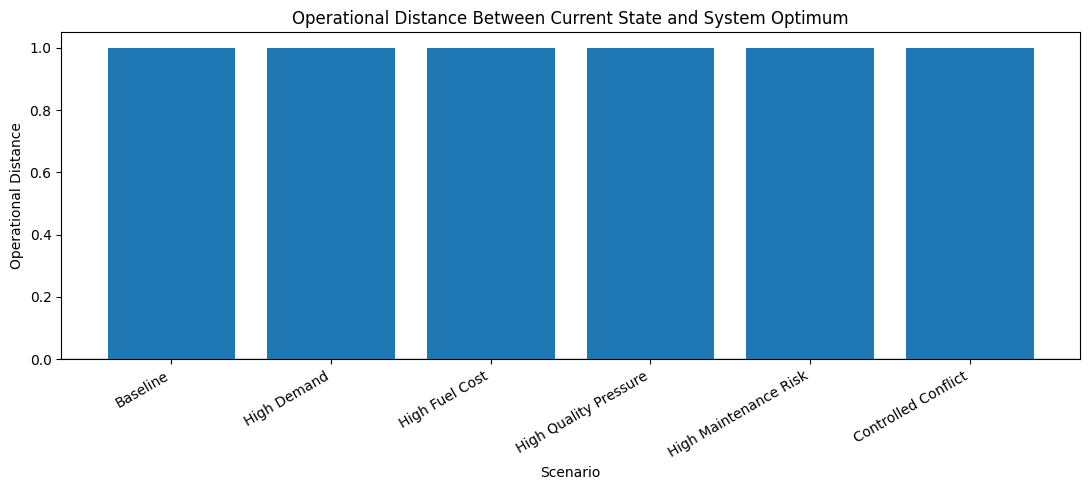

In [100]:
plt.figure(figsize=(11, 5))

plt.bar(
    experiment_df["Scenario"],
    experiment_df["Operational Distance"]
)

plt.xlabel("Scenario")
plt.ylabel("Operational Distance")

plt.title(
    "Operational Distance Between Current State and System Optimum"
)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.axhline(
    0,
    linewidth=1
)

plt.tight_layout()
plt.show()

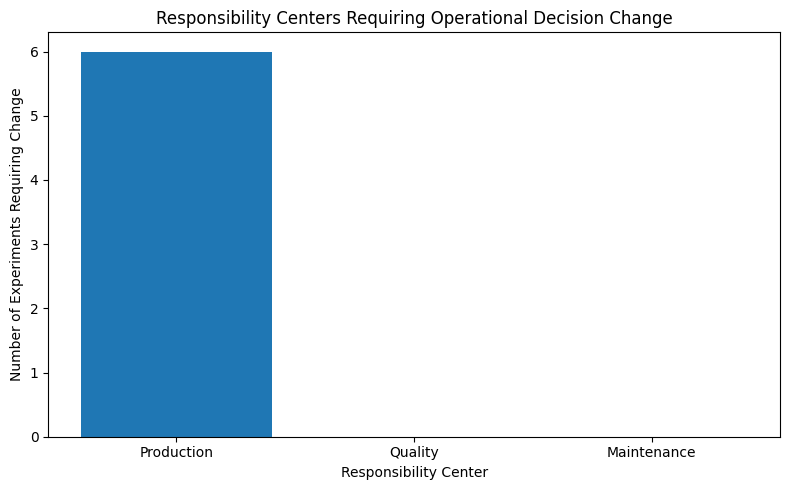

In [101]:
center_changes = {
    "Production": 0,
    "Quality": 0,
    "Maintenance": 0,
}

for record in experiment_records.values():

    current = record["current_state"]
    optimum = record["system_optimum"]

    for player in current:

        if current[player] != optimum[player]:
            center_changes[player] += 1


plt.figure(figsize=(8, 5))

plt.bar(
    center_changes.keys(),
    center_changes.values()
)

plt.xlabel("Responsibility Center")
plt.ylabel("Number of Experiments Requiring Change")

plt.title(
    "Responsibility Centers Requiring Operational Decision Change"
)

plt.tight_layout()
plt.show()

In [102]:
SOP_RULES = {

    "Production": {
        "P1": "الاستمرار في التشغيل رغم الانحراف",
        "P2": "خفض سرعة الخط",
        "P3": "إيقاف الخط",
    },

    "Quality": {
        "Q1": "قبول نسبة محدودة من العيوب",
        "Q2": "إعادة تشغيل الوحدات المعيبة",
        "Q3": "إيقاف الخط عند تكرار العيب",
    },

    "Maintenance": {
        "M1": "صيانة تصحيحية",
        "M2": "صيانة وقائية",
        "M3": "صيانة تنبؤية",
    }
}

In [103]:
def apply_sop_constraints(
    strategies,
    sop_constraints
):

    constrained_strategies = {}

    for player, player_strategies in strategies.items():

        if player in sop_constraints:

            allowed = sop_constraints[player]

            constrained_strategies[player] = [
                strategy
                for strategy in player_strategies
                if strategy in allowed
            ]

        else:

            constrained_strategies[player] = list(
                player_strategies
            )

    return constrained_strategies

In [104]:
conflict_sop = {

    "Production": ["P1", "P2"],

    "Quality": ["Q1", "Q2", "Q3"],

    "Maintenance": ["M1", "M2", "M3"],
}

In [105]:
constrained_strategies = apply_sop_constraints(
    strategies,
    conflict_sop
)

print(constrained_strategies)

{'Production': ['P1', 'P2'], 'Quality': ['Q1', 'Q2', 'Q3'], 'Maintenance': ['M1', 'M2', 'M3']}


In [106]:
from itertools import product


def calculate_game_analysis_with_sop_constraints(
    players,
    constrained_strategies,
    payoff_function
):

    profiles = list(
        product(
            *[
                constrained_strategies[player]
                for player in players
            ]
        )
    )

    # --------------------------------------------------------
    # Find Nash equilibria
    # --------------------------------------------------------

    nash_equilibria = []

    for profile in profiles:

        profile_dict = dict(
            zip(players, profile)
        )

        is_nash = True

        for player in players:

            current_strategy = profile_dict[player]

            current_payoff = payoff_function(
                profile,
                player
            )

            for alternative in constrained_strategies[player]:

                if alternative == current_strategy:
                    continue

                alternative_profile = profile_dict.copy()

                alternative_profile[player] = alternative

                alternative_tuple = tuple(
                    alternative_profile[p]
                    for p in players
                )

                alternative_payoff = payoff_function(
                    alternative_tuple,
                    player
                )

                if alternative_payoff > current_payoff:

                    is_nash = False
                    break

            if not is_nash:
                break

        if is_nash:
            nash_equilibria.append(
                profile_dict
            )

    # --------------------------------------------------------
    # System optimum
    # --------------------------------------------------------

    system_scores = []

    for profile in profiles:

        total = sum(
            payoff_function(profile, player)
            for player in players
        )

        system_scores.append(
            (profile, total)
        )

    max_system_payoff = max(
        score
        for _, score in system_scores
    )

    system_optima = [
        dict(zip(players, profile))
        for profile, score in system_scores
        if score == max_system_payoff
    ]

    system_optimum = system_optima[0]

    # --------------------------------------------------------
    # Select first Nash for MVP
    # --------------------------------------------------------

    nash_equilibrium = (
        nash_equilibria[0]
        if nash_equilibria
        else None
    )

    nash_system_payoff = None

    if nash_equilibrium:

        nash_profile = tuple(
            nash_equilibrium[player]
            for player in players
        )

        nash_system_payoff = sum(
            payoff_function(
                nash_profile,
                player
            )
            for player in players
        )

    # --------------------------------------------------------
    # Distance
    # --------------------------------------------------------

    strategy_distance = None

    if nash_equilibrium:

        strategy_distance = sum(
            nash_equilibrium[player]
            != system_optimum[player]
            for player in players
        )

    payoff_gap = None

    if nash_system_payoff is not None:

        payoff_gap = (
            max_system_payoff
            - nash_system_payoff
        )

    return {

        "nash_equilibria":
            nash_equilibria,

        "nash_equilibrium":
            nash_equilibrium,

        "system_optima":
            system_optima,

        "system_optimum":
            system_optimum,

        "system_payoff":
            max_system_payoff,

        "nash_system_payoff":
            nash_system_payoff,

        "payoff_gap":
            payoff_gap,

        "strategy_distance":
            strategy_distance,

        "alignment":
            (
                strategy_distance == 0
            ),
    }

In [107]:
sop_conflict_analysis = calculate_game_analysis_with_sop_constraints(
    players,
    constrained_strategies,
    conflict_payoff_function
)

In [108]:
print("Nash:")
print(
    sop_conflict_analysis["nash_equilibrium"]
)

print("\nSystem optimum:")
print(
    sop_conflict_analysis["system_optimum"]
)

print("\nNash system payoff:")
print(
    sop_conflict_analysis["nash_system_payoff"]
)

print("\nSystem payoff:")
print(
    sop_conflict_analysis["system_payoff"]
)

print("\nPerformance gap:")
print(
    sop_conflict_analysis["payoff_gap"]
)

print("\nOperational distance:")
print(
    sop_conflict_analysis["strategy_distance"]
)

print("\nAlignment:")
print(
    sop_conflict_analysis["alignment"]
)

Nash:
{'Production': 'P2', 'Quality': 'Q3', 'Maintenance': 'M3'}

System optimum:
{'Production': 'P2', 'Quality': 'Q3', 'Maintenance': 'M3'}

Nash system payoff:
29.5

System payoff:
29.5

Performance gap:
0.0

Operational distance:
0

Alignment:
True


In [109]:
sop_conflict_analysis = calculate_game_analysis_with_sop_constraints(
    players,
    constrained_strategies,
    conflict_payoff_function
)

print(sop_conflict_analysis)

{'nash_equilibria': [{'Production': 'P2', 'Quality': 'Q3', 'Maintenance': 'M3'}], 'nash_equilibrium': {'Production': 'P2', 'Quality': 'Q3', 'Maintenance': 'M3'}, 'system_optima': [{'Production': 'P2', 'Quality': 'Q3', 'Maintenance': 'M3'}], 'system_optimum': {'Production': 'P2', 'Quality': 'Q3', 'Maintenance': 'M3'}, 'system_payoff': 29.5, 'nash_system_payoff': 29.5, 'payoff_gap': 0.0, 'strategy_distance': 0, 'alignment': True}


In [110]:
# ============================================================
# CELL 111 (REPLACED)
# ENGLISH CONFLICT ENGINEERING NARRATIVE
# ============================================================

def generate_conflict_engineering_narrative(
    conflict_analysis,
    baseline_result
):
    """
    Generate an English engineering narrative for the controlled
    strategic conflict test.
    """
    paragraphs = []

    current_state = conflict_analysis["nash_equilibrium"]
    system_optimum = conflict_analysis["system_optimum"]

    baseline_payoff = float(
        baseline_result["nash_system_payoff"]
    )
    current_payoff = float(
        conflict_analysis["nash_system_payoff"]
    )
    system_payoff = float(
        conflict_analysis["system_payoff"]
    )
    payoff_gap = float(conflict_analysis["payoff_gap"])
    distance = int(conflict_analysis["strategy_distance"])

    # --------------------------------------------------------
    # 1. Strategic response
    # --------------------------------------------------------
    decision_changes = compare_profiles(
        baseline_result["nash_equilibrium"],
        current_state
    )

    if decision_changes:
        for change in decision_changes:
            center = change["player"]
            paragraphs.append(
                f"The conflict scenario changed the operating "
                f"decision of the {center} responsibility "
                f"center: it shifted from {change['from']} to "
                f"{change['to']}."
            )

    # --------------------------------------------------------
    # 2. Resulting operating state
    # --------------------------------------------------------
    state_text = ", ".join(
        f"{p} = {s}" for p, s in current_state.items()
    )
    paragraphs.append(
        "The Nash operating profile resulting from the "
        "independent decisions of the responsibility centers "
        "is: " + state_text + "."
    )

    # --------------------------------------------------------
    # 3. System-optimal profile
    # --------------------------------------------------------
    optimum_changes = []
    for player in current_state:
        if current_state[player] != system_optimum[player]:
            optimum_changes.append({
                "player": player,
                "from": current_state[player],
                "to": system_optimum[player],
            })

    if optimum_changes:
        for change in optimum_changes:
            paragraphs.append(
                f"To reach the system-optimal profile, the "
                f"{change['player']} responsibility center "
                f"should shift from {change['from']} to "
                f"{change['to']}."
            )

    # --------------------------------------------------------
    # 4. Performance
    # --------------------------------------------------------
    performance_change = current_payoff - baseline_payoff

    if performance_change < 0:
        paragraphs.append(
            f"The aggregate system payoff decreased from "
            f"{baseline_payoff:.2f} at baseline to "
            f"{current_payoff:.2f} under strategic conflict "
            f"({performance_change:.2f})."
        )
    elif performance_change > 0:
        paragraphs.append(
            f"The aggregate system payoff increased from "
            f"{baseline_payoff:.2f} to {current_payoff:.2f} "
            f"(+{performance_change:.2f})."
        )
    else:
        paragraphs.append(
            "The aggregate system payoff remained unchanged "
            "relative to baseline."
        )

    # --------------------------------------------------------
    # 5. Payoff gap and distance
    # --------------------------------------------------------
    paragraphs.append(
        f"The Nash system payoff is {current_payoff:.2f} "
        f"against a system-optimal payoff of "
        f"{system_payoff:.2f}, giving a payoff gap of "
        f"{payoff_gap:.2f}. The strategic distance is "
        f"{distance}."
    )

    # --------------------------------------------------------
    # 6. Engineering conclusion
    # --------------------------------------------------------
    if optimum_changes:
        centers = ", ".join(
            c["player"] for c in optimum_changes
        )
        paragraphs.append(
            f"The result indicates that the misalignment "
            f"between the Nash equilibrium and the system "
            f"optimum is concentrated in the {centers} "
            f"responsibility center. Reaching the system "
            f"optimum does not require changing all "
            f"responsibility-center decisions, only the "
            f"decision of the affected center."
        )

    return paragraphs

In [111]:
# ============================================================
# BOOTSTRAP CELL (CORRECTED — uses globals())
# ============================================================

g = globals()

# ------------------------------------------------------------
# 0. GLOBAL DICTIONARIES
# ------------------------------------------------------------

if "players" not in g:
    players = ["Production", "Quality", "Maintenance"]

if "strategies" not in g:
    strategies = {
        "Production": ["P1", "P2", "P3"],
        "Quality": ["Q1", "Q2", "Q3"],
        "Maintenance": ["M1", "M2", "M3"],
    }

if "STRATEGY_DEFINITIONS" not in g:
    STRATEGY_DEFINITIONS = {
        "Production": {
            "P1": {"name": "Continue despite deviation",
                   "description": "Continue production despite an "
                   "operational deviation to protect short-term output."},
            "P2": {"name": "Reduce line speed",
                   "description": "Reduce production speed to stabilize "
                   "the process while continuing operation."},
            "P3": {"name": "Stop the line",
                   "description": "Stop production to prevent "
                   "propagation of an identified operational problem."},
        },
        "Quality": {
            "Q1": {"name": "Accept limited defects",
                   "description": "Allow a limited level of defects to "
                   "avoid interrupting production."},
            "Q2": {"name": "Rework defective units",
                   "description": "Separate defective units and perform "
                   "rework without immediately stopping the line."},
            "Q3": {"name": "Stop line for repeated defect",
                   "description": "Stop the line when repeated defects "
                   "indicate a persistent process problem."},
        },
        "Maintenance": {
            "M1": {"name": "Corrective maintenance",
                   "description": "Intervene after equipment failure or "
                   "a significant equipment deviation."},
            "M2": {"name": "Preventive maintenance",
                   "description": "Perform planned maintenance according "
                   "to a preventive schedule."},
            "M3": {"name": "Predictive maintenance",
                   "description": "Use condition information to "
                   "intervene before a major failure occurs."},
        }
    }

if "uncertainty_scenarios" not in g:
    uncertainty_scenarios = {
        "Baseline": {"demand": 100, "fuel_cost": 1.0,
                     "quality_pressure": 1.0, "maintenance_risk": 1.0},
        "High Demand": {"demand": 130, "fuel_cost": 1.0,
                        "quality_pressure": 1.0, "maintenance_risk": 1.0},
        "High Fuel Cost": {"demand": 100, "fuel_cost": 1.5,
                           "quality_pressure": 2.0, "maintenance_risk": 2.0},
        "High Quality Pressure": {"demand": 100, "fuel_cost": 1.0,
                                  "quality_pressure": 1.5,
                                  "maintenance_risk": 1.0},
        "High Maintenance Risk": {"demand": 100, "fuel_cost": 1.0,
                                  "quality_pressure": 1.0,
                                  "maintenance_risk": 1.5},
    }

if "payoffs" not in g:
    payoffs = {
        ("P1","Q1","M1"): (6,6,6),   ("P1","Q1","M2"): (5,7,7),
        ("P1","Q1","M3"): (4,5,8),   ("P1","Q2","M1"): (7,5,7),
        ("P1","Q2","M2"): (8,6,8),   ("P1","Q2","M3"): (6,7,9),
        ("P1","Q3","M1"): (5,8,6),   ("P1","Q3","M2"): (7,9,8),
        ("P1","Q3","M3"): (6,10,9),
        ("P2","Q1","M1"): (8,6,5),   ("P2","Q1","M2"): (9,7,7),
        ("P2","Q1","M3"): (7,6,8),   ("P2","Q2","M1"): (9,8,7),
        ("P2","Q2","M2"): (10,9,8),  ("P2","Q2","M3"): (8,8,9),
        ("P2","Q3","M1"): (8,9,7),   ("P2","Q3","M2"): (9,10,9),
        ("P2","Q3","M3"): (8,11,10),
        ("P3","Q1","M1"): (7,5,6),   ("P3","Q1","M2"): (8,6,8),
        ("P3","Q1","M3"): (6,5,9),   ("P3","Q2","M1"): (8,7,7),
        ("P3","Q2","M2"): (9,8,9),   ("P3","Q2","M3"): (7,8,10),
        ("P3","Q3","M1"): (7,9,7),   ("P3","Q3","M2"): (8,10,9),
        ("P3","Q3","M3"): (7,11,11),
    }

if "PLAYER_NAMES_AR" not in g:
    PLAYER_NAMES_AR = {"Production": "الإنتاج",
                       "Quality": "الجودة",
                       "Maintenance": "الصيانة"}

if "STRATEGY_ACTIONS_AR" not in g:
    STRATEGY_ACTIONS_AR = {
        "P1": "الاستمرار في تشغيل الخط رغم الانحراف",
        "P2": "خفض سرعة الخط", "P3": "إيقاف الخط",
        "Q1": "قبول نسبة محدودة من العيوب",
        "Q2": "إعادة تشغيل الوحدات المعيبة",
        "Q3": "إيقاف الخط عند تكرار العيب",
        "M1": "تنفيذ صيانة تصحيحية",
        "M2": "تنفيذ صيانة وقائية",
        "M3": "تنفيذ صيانة تنبؤية",
    }

if "UNCERTAINTY_NAMES_AR" not in g:
    UNCERTAINTY_NAMES_AR = {
        "demand": "الطلب", "fuel_cost": "تكلفة الوقود",
        "quality_pressure": "ضغط الجودة",
        "maintenance_risk": "مخاطر الصيانة",
    }


# ------------------------------------------------------------
# 1. VERIFY HELPER FUNCTIONS
# ------------------------------------------------------------
g = globals()
_missing_helpers = []
for _fn in [
    "format_profile", "create_payoff_function",
    "calculate_full_game_analysis",
    "build_experiment_record",
    "build_conflict_experiment_record",
    "build_engineering_analysis",
    "compare_profiles", "player_name_ar", "strategy_action",
    "uncertainty_name_ar", "classify_engineering_result",
]:
    if _fn not in g:
        _missing_helpers.append(_fn)

if _missing_helpers:
    raise RuntimeError(
        "❌ Missing helper functions: "
        + ", ".join(_missing_helpers)
        + "\nPlease run the earlier cells that define them."
    )

print("✓ All helper functions present")


# ------------------------------------------------------------
# 2. STRATEGY DEFINITIONS DATAFRAME
# ------------------------------------------------------------
if "strategy_definition_df" not in g:
    rows = []
    for player in players:
        for sc in strategies[player]:
            d = STRATEGY_DEFINITIONS[player][sc]
            rows.append({"Player": player, "Strategy": sc,
                         "Operational Action": d["name"],
                         "Description": d["description"]})
    strategy_definition_df = pd.DataFrame(rows)
    print("✓ strategy_definition_df created")


# ------------------------------------------------------------
# 3. PAYOFF DATAFRAME
# ------------------------------------------------------------
if "payoff_df" not in g:
    rows = []
    for profile, values in payoffs.items():
        row = {"Profile": format_profile(profile, players)}
        for i, player in enumerate(players):
            row[player] = values[i]
        row["System Payoff"] = sum(values)
        rows.append(row)
    payoff_df = pd.DataFrame(rows)
    print("✓ payoff_df created")


# ------------------------------------------------------------
# 4. UNCERTAINTY DATAFRAME
# ------------------------------------------------------------
if "uncertainty_df" not in g:
    rows = []
    for scenario, values in uncertainty_scenarios.items():
        rows.append({
            "Scenario": scenario,
            "Demand": values["demand"],
            "Fuel Cost": values["fuel_cost"],
            "Quality Pressure": values["quality_pressure"],
            "Maintenance Risk": values["maintenance_risk"],
        })
    uncertainty_df = pd.DataFrame(rows)
    print("✓ uncertainty_df created")


# ------------------------------------------------------------
# 5. SCENARIO RESULTS DATAFRAME
# ------------------------------------------------------------
g = globals()

if "scenario_results" not in g:
    print("\n⚠ scenario_results missing — computing it now")

    # We need build_uncertain_payoff from earlier cell
    if "build_uncertain_payoff" not in g:
        raise RuntimeError(
            "❌ build_uncertain_payoff is not defined. "
            "Please run the cell that defines it."
        )

    def _analyze_scenario(scenario_name, uncertainty,
                          base_payoffs, players, strategies):
        scenario_payoffs = build_uncertain_payoff(
            base_payoffs=base_payoffs,
            players=players,
            uncertainty=uncertainty,
        )
        pf = create_payoff_function(scenario_payoffs, players)
        analysis = calculate_full_game_analysis(
            players=players,
            strategies=strategies,
            payoff=pf,
        )
        analysis["scenario"] = scenario_name
        analysis["uncertainty"] = uncertainty
        return analysis

    scenario_results = {}
    for name, unc in uncertainty_scenarios.items():
        scenario_results[name] = _analyze_scenario(
            name, unc, payoffs, players, strategies
        )
    print(f"✓ scenario_results created ({len(scenario_results)} scenarios)")


if "scenario_results_df" not in g:
    rows = []
    for name, result in scenario_results.items():
        rows.append({
            "Scenario": name,
            "Nash": format_profile(result["nash_equilibrium"], players),
            "System Optimum": format_profile(
                result["system_optimum"], players
            ),
            "Nash → SO Distance": result["strategy_distance"],
            "Nash → BR Distance":
                result["nash_best_response_distance"],
            "Nash Payoff": result["nash_system_payoff"],
            "System Payoff": result["system_payoff"],
            "Payoff Gap": result["payoff_gap"],
            "Alignment": result["alignment"],
        })
    scenario_results_df = pd.DataFrame(rows)
    print("✓ scenario_results_df created")


# ------------------------------------------------------------
# 6. BASELINE RESULT
# ------------------------------------------------------------
g = globals()

if "baseline_result" not in g:
    baseline_result = scenario_results["Baseline"]
    print("✓ baseline_result created")


# ------------------------------------------------------------
# 7. STRATEGY MOVEMENT
# ------------------------------------------------------------
g = globals()

if "strategy_movement_df" not in g:
    baseline_nash = baseline_result["nash_equilibrium"]
    rows = []
    for name, result in scenario_results.items():
        sn = result["nash_equilibrium"]
        for player in players:
            b = baseline_nash[player] if baseline_nash else None
            s = sn[player] if sn else None
            rows.append({
                "Scenario": name, "Player": player,
                "Baseline Nash Strategy": b,
                "Scenario Nash Strategy": s,
                "Changed": b != s,
            })
    strategy_movement_df = pd.DataFrame(rows)
    print("✓ strategy_movement_df created")


# ------------------------------------------------------------
# 8. SENSITIVITY
# ------------------------------------------------------------
g = globals()

if "sensitivity_df" not in g:
    rows = []
    for player in players:
        changes = strategy_movement_df[
            (strategy_movement_df["Player"] == player)
            & (strategy_movement_df["Changed"] == True)
        ]
        # We exclude the baseline from the total count as it is
        # the reference point, not a source of change.
        total = len(uncertainty_scenarios) - 1
        changed = len(changes)
        ratio = (changed / total) if total else 0.0
        rows.append({
            "Player": player,
            "Number of Changed Scenarios": changed,  # <-- CORRECTED NAME
            "Total Scenarios": total,
            "Sensitivity Ratio": ratio,
        })
    sensitivity_df = pd.DataFrame(rows)
    print("✓ sensitivity_df created")


# ------------------------------------------------------------
# 9. ALIGNMENT SUMMARY
# ------------------------------------------------------------
g = globals()

if "alignment_summary" not in g:
    alignment_summary = scenario_results_df[[
        "Scenario", "Nash → SO Distance",
        "Payoff Gap", "Alignment",
    ]].copy()
    print("✓ alignment_summary created")


# ------------------------------------------------------------
# 10. EXPERIMENT RECORDS
# ------------------------------------------------------------
g = globals()

if "experiment_records" not in g:
    experiment_records = {}
    for name, result in scenario_results.items():
        experiment_records[name] = build_experiment_record(
            result, baseline_result
        )
    print("✓ experiment_records created")


# ------------------------------------------------------------
# 11. CONFLICT ANALYSIS
# ------------------------------------------------------------
g = globals()

if "conflict_analysis" not in g:
    print("⚠ conflict_analysis missing — building it now")

    prod_inc = {"P1": 0.0, "P2": 0.5, "P3": 5.0}
    qual_ext = {
        "P1": {"Q1": 0.0, "Q2": 0.0, "Q3": 0.0},
        "P2": {"Q1": 0.0, "Q2": 0.0, "Q3": 0.0},
        "P3": {"Q1": -3.0, "Q2": -4.0, "Q3": -5.0},
    }
    maint_ext = {
        "P1": {"M1": 0.0, "M2": 0.0, "M3": 0.0},
        "P2": {"M1": 0.0, "M2": 0.0, "M3": 0.0},
        "P3": {"M1": -2.0, "M2": -3.0, "M3": -4.0},
    }

    conflict_payoffs = {}
    for profile, base_values in payoffs.items():
        pd_ = dict(zip(players, profile))
        p, q, m = pd_["Production"], pd_["Quality"], pd_["Maintenance"]
        pr, ql, mt = base_values
        pr += prod_inc[p]
        ql += qual_ext[p][q]
        mt += maint_ext[p][m]
        conflict_payoffs[profile] = (
            round(pr, 3), round(ql, 3), round(mt, 3)
        )

    conflict_payoff_function = create_payoff_function(
        conflict_payoffs, players
    )
    conflict_analysis = calculate_full_game_analysis(
        players=players, strategies=strategies,
        payoff=conflict_payoff_function,
    )
    print("✓ conflict_analysis created")


# ------------------------------------------------------------
# 12. CONFLICT SUMMARY
# ------------------------------------------------------------
g = globals()

if "conflict_summary" not in g:
    nash = conflict_analysis["nash_equilibrium"]
    so = conflict_analysis["system_optimum"]
    conflict_summary = {
        "Experiment": "Strategic Conflict Test",
        "Nash": format_profile(nash, players),
        "System Optimum": format_profile(so, players),
        "Strategy Distance": conflict_analysis["strategy_distance"],
        "Payoff Gap": conflict_analysis["payoff_gap"],
        "Alignment": conflict_analysis["alignment"],
        "Nash System Payoff":
            conflict_analysis["nash_system_payoff"],
        "System Payoff": conflict_analysis["system_payoff"],
    }
    print("✓ conflict_summary created")


# ------------------------------------------------------------
# 13. CONFLICT RECORD
# ------------------------------------------------------------
g = globals()

if "conflict_record" not in g:
    conflict_record = build_conflict_experiment_record(
        conflict_analysis, baseline_result
    )
    print("✓ conflict_record created")

if "Controlled Conflict" not in experiment_records:
    experiment_records["Controlled Conflict"] = conflict_record
    print("✓ 'Controlled Conflict' added")


# ------------------------------------------------------------
# 14. SOP-CONSTRAINED ANALYSIS
# ------------------------------------------------------------
g = globals()

if "sop_conflict_analysis" not in g:
    print("⚠ sop_conflict_analysis missing — building it now")
    from itertools import product as _product

    conflict_sop = {
        "Production": ["P1", "P2"],
        "Quality": ["Q1", "Q2", "Q3"],
        "Maintenance": ["M1", "M2", "M3"],
    }

    constrained = {}
    for pl, pl_strats in strategies.items():
        if pl in conflict_sop:
            constrained[pl] = [s for s in pl_strats
                               if s in conflict_sop[pl]]
        else:
            constrained[pl] = list(pl_strats)

    profiles = list(_product(*[constrained[p] for p in players]))

    nash_eqs = []
    for profile in profiles:
        pd_ = dict(zip(players, profile))
        is_nash = True
        for player in players:
            cur = pd_[player]
            cur_pay = conflict_payoff_function(profile, player)
            for alt in constrained[player]:
                if alt == cur:
                    continue
                alt_pd = pd_.copy()
                alt_pd[player] = alt
                alt_t = tuple(alt_pd[p] for p in players)
                if conflict_payoff_function(alt_t, player) > cur_pay:
                    is_nash = False
                    break
            if not is_nash:
                break
        if is_nash:
            nash_eqs.append(pd_)

    scores = []
    for profile in profiles:
        total = sum(conflict_payoff_function(profile, p)
                    for p in players)
        scores.append((profile, total))

    max_sys = max(s for _, s in scores)
    system_optima = [dict(zip(players, pr))
                     for pr, sc in scores if sc == max_sys]
    system_optimum = system_optima[0]
    nash_equilibrium = nash_eqs[0] if nash_eqs else None

    nash_sys = None
    if nash_equilibrium:
        nash_profile = tuple(nash_equilibrium[p] for p in players)
        nash_sys = sum(conflict_payoff_function(nash_profile, p)
                       for p in players)

    dist = None
    if nash_equilibrium:
        dist = sum(nash_equilibrium[p] != system_optimum[p]
                   for p in players)

    gap = None
    if nash_sys is not None:
        gap = max_sys - nash_sys

    sop_conflict_analysis = {
        "nash_equilibria": nash_eqs,
        "nash_equilibrium": nash_equilibrium,
        "system_optima": system_optima,
        "system_optimum": system_optimum,
        "system_payoff": max_sys,
        "nash_system_payoff": nash_sys,
        "payoff_gap": gap,
        "strategy_distance": dist,
        "alignment": (dist == 0) if dist is not None else False,
    }
    print("✓ sop_conflict_analysis created")


# ------------------------------------------------------------
# FINAL CHECK (uses globals())
# ------------------------------------------------------------
g = globals()
required_vars = [
    "scenario_results", "baseline_result", "scenario_results_df",
    "strategy_movement_df", "sensitivity_df", "alignment_summary",
    "payoff_df", "uncertainty_df", "strategy_definition_df",
    "experiment_records", "conflict_summary", "conflict_analysis",
    "sop_conflict_analysis",
]

missing = [v for v in required_vars if v not in g]

print("\n" + "=" * 60)
if missing:
    print("❌ STILL MISSING:", missing)
else:
    print("✅ ALL VARIABLES READY — run the report cell now")
print("=" * 60)

✓ All helper functions present
✓ strategy_definition_df created
✓ payoff_df created
✓ uncertainty_df created

✅ ALL VARIABLES READY — run the report cell now


In [112]:
# فحص صحيح باستخدام globals()
required = [
    "players", "strategies", "payoffs", "uncertainty_scenarios",
    "STRATEGY_DEFINITIONS",
    "scenario_results", "baseline_result", "scenario_results_df",
    "strategy_movement_df", "sensitivity_df", "alignment_summary",
    "payoff_df", "uncertainty_df", "strategy_definition_df",
    "experiment_records", "conflict_summary", "conflict_analysis",
    "sop_conflict_analysis",
    "format_profile", "create_payoff_function",
    "calculate_full_game_analysis", "build_experiment_record",
    "build_conflict_experiment_record", "build_engineering_analysis",
    "compare_profiles", "player_name_ar", "strategy_action",
    "uncertainty_name_ar", "classify_engineering_result",
]

g = globals()
for var in required:
    status = "✓" if var in g else "✗ MISSING"
    print(f"  {status}  {var}")

  ✓  players
  ✓  strategies
  ✓  payoffs
  ✓  uncertainty_scenarios
  ✓  STRATEGY_DEFINITIONS
  ✓  scenario_results
  ✓  baseline_result
  ✓  scenario_results_df
  ✓  strategy_movement_df
  ✓  sensitivity_df
  ✓  alignment_summary
  ✓  payoff_df
  ✓  uncertainty_df
  ✓  strategy_definition_df
  ✓  experiment_records
  ✓  conflict_summary
  ✓  conflict_analysis
  ✓  sop_conflict_analysis
  ✓  format_profile
  ✓  create_payoff_function
  ✓  calculate_full_game_analysis
  ✓  build_experiment_record
  ✓  build_conflict_experiment_record
  ✓  build_engineering_analysis
  ✓  compare_profiles
  ✓  player_name_ar
  ✓  strategy_action
  ✓  uncertainty_name_ar
  ✓  classify_engineering_result


In [113]:
# ============================================================
# FORCE-FIX CELL: Recreate sensitivity_df with Correct Column Name
# ============================================================

import pandas as pd

print("Checking and fixing 'sensitivity_df'...")

# Check if the DataFrame exists and has the wrong column name
if 'sensitivity_df' in locals() or 'sensitivity_df' in globals():
    if 'Number of Changed Scenarios' not in sensitivity_df.columns:
        print("  -> Found 'sensitivity_df' with incorrect columns. Fixing...")
        
        # Recreate the DataFrame from its source data
        # This assumes 'strategy_movement_df', 'players', and 'uncertainty_scenarios' are in memory
        
        rows = []
        for player in players:
            # Count scenarios where the strategy changed, excluding the baseline
            changes = strategy_movement_df[
                (strategy_movement_df["Player"] == player) &
                (strategy_movement_df["Scenario"] != "Baseline") &
                (strategy_movement_df["Changed"] == True)
            ]
            
            total_scenarios = len(uncertainty_scenarios) - 1  # Exclude baseline
            changed_count = len(changes)
            ratio = (changed_count / total_scenarios) if total_scenarios > 0 else 0.0

            rows.append({
                "Player": player,
                "Number of Changed Scenarios": changed_count,
                "Total Scenarios": total_scenarios,
                "Sensitivity Ratio": ratio,
            })
        
        sensitivity_df = pd.DataFrame(rows)
        print("  -> 'sensitivity_df' has been recreated successfully with correct columns.")
    else:
        print("  -> 'sensitivity_df' already has the correct columns.")
else:
    print("  -> 'sensitivity_df' not found. Please run the bootstrap cell first.")
    # Fallback to create it if it doesn't exist at all
    rows = []
    for player in players:
        changes = strategy_movement_df[
            (strategy_movement_df["Player"] == player) &
            (strategy_movement_df["Scenario"] != "Baseline") &
            (strategy_movement_df["Changed"] == True)
        ]
        total_scenarios = len(uncertainty_scenarios) - 1
        changed_count = len(changes)
        ratio = (changed_count / total_scenarios) if total_scenarios > 0 else 0.0
        rows.append({
            "Player": player,
            "Number of Changed Scenarios": changed_count,
            "Total Scenarios": total_scenarios,
            "Sensitivity Ratio": ratio,
        })
    sensitivity_df = pd.DataFrame(rows)
    print("  -> 'sensitivity_df' created.")


# Display the corrected DataFrame to verify
print("\nCorrected 'sensitivity_df':")
print(sensitivity_df)

Checking and fixing 'sensitivity_df'...
  -> Found 'sensitivity_df' with incorrect columns. Fixing...
  -> 'sensitivity_df' has been recreated successfully with correct columns.

Corrected 'sensitivity_df':
        Player  Number of Changed Scenarios  Total Scenarios  \
0   Production                            0                4   
1      Quality                            0                4   
2  Maintenance                            2                4   

   Sensitivity Ratio  
0                0.0  
1                0.0  
2                0.5  


In [114]:
# ============================================================
# CELL 115 — MASTER REPORT ENGINE
# ENGLISH ACADEMIC VERSION
# Strategic Conflict under Uncertainty + SOP Intervention
# ============================================================
# التعديلات:
#   1. استخدام sop_summary_df بدلاً من sop_conflict_analysis
#   2. Engineering narrative إنجليزي بالكامل
#   3. إضافة صفحة Limitations
#   4. إضافة صفحة Experimental Interpretation
#   5. تحديث SOP Analysis لتشمل Pre-SOP و Post-SOP لكل سيناريو
#   6. تحديث Cover Page ليعكس التجربة الجديدة
# ============================================================

# ------------------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------------------

import os
import math
import json
import re
from itertools import product
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt

from openpyxl import Workbook
from openpyxl.styles import (
    Font, PatternFill, Alignment, Border, Side
)
from openpyxl.utils import get_column_letter
from openpyxl.formatting.rule import CellIsRule

from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.enums import TA_CENTER, TA_LEFT, TA_RIGHT
from reportlab.lib.styles import (
    getSampleStyleSheet, ParagraphStyle
)
from reportlab.lib.units import mm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table,
    TableStyle, PageBreak, KeepTogether, Image, HRFlowable
)
from reportlab.pdfgen import canvas
from reportlab.graphics.shapes import (
    Drawing, Rect, String, Line, Polygon
)
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

# Arabic shaping imports (kept only for cover page Arabic title)
try:
    import arabic_reshaper
    from bidi.algorithm import get_display
    ARABIC_SHAPING_AVAILABLE = True
except ImportError:
    ARABIC_SHAPING_AVAILABLE = False
    print("WARNING: arabic_reshaper / python-bidi missing.")


# ------------------------------------------------------------
# 2. RTL TEXT HELPERS (kept for cover page only)
# ------------------------------------------------------------

def rtl(text):
    """Prepare Arabic text for ReportLab."""
    if text is None:
        return ""
    if not ARABIC_SHAPING_AVAILABLE:
        return str(text)
    text = str(text)
    parts = re.split(r"(<[^>]+>)", text)
    processed = []
    for part in parts:
        if part.startswith("<") and part.endswith(">"):
            processed.append(part)
        else:
            if part.strip():
                try:
                    reshaped_text = arabic_reshaper.reshape(part)
                    bidi_text = get_display(reshaped_text)
                    processed.append(bidi_text)
                except Exception:
                    processed.append(part)
            else:
                processed.append(part)
    return "".join(processed)


def find_arabic_font():
    """Locate an Arabic-capable TTF font."""
    candidates = [
        r"C:\Windows\Fonts\arial.ttf",
        r"C:\Windows\Fonts\Arial.ttf",
        r"C:\Windows\Fonts\segoeui.ttf",
        r"C:\Windows\Fonts\tahoma.ttf",
        r"C:\Windows\Fonts\DejaVuSans.ttf",
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "/usr/share/fonts/truetype/noto/NotoSansArabic-Regular.ttf",
        "/usr/share/fonts/opentype/noto/NotoSansArabic-Regular.ttf",
    ]
    for path in candidates:
        if os.path.exists(path):
            print("Arabic font selected:", path)
            return path
    return None


# ------------------------------------------------------------
# 3. REGISTER ARABIC FONT
# ------------------------------------------------------------

ARABIC_FONT_PATH = find_arabic_font()

if ARABIC_FONT_PATH:
    try:
        pdfmetrics.registerFont(
            TTFont("ArabicFont", ARABIC_FONT_PATH)
        )
        ARABIC_FONT_AVAILABLE = True
    except Exception as e:
        ARABIC_FONT_AVAILABLE = False
        print("Arabic font registration failed:", e)
else:
    ARABIC_FONT_AVAILABLE = False
    print("WARNING: Arabic font not found.")

ARABIC_FONT_NAME = (
    "ArabicFont" if ARABIC_FONT_AVAILABLE else "Helvetica"
)


# ------------------------------------------------------------
# 4. EXPERIMENT METADATA
# ------------------------------------------------------------

EXPERIMENT_NUMBER = 3
EXPERIMENT_NAME = "Strategic Conflict under Uncertainty - " + rtl("اختلاف استراتيجيات الأقسام ضمن عدم اليقين")

RESEARCH_QUESTION = (
    "How does the interaction between external uncertainty and "
    "strategic externalities affect the alignment between the "
    "Nash equilibrium of responsibility centers and the "
    "system-optimal operating profile?"
)

THESIS_TITLE = (
    "Improving Production Line Performance under Uncertainty Using Game Theory and Digital Twins"
)

RESEARCHER = "Waseem Saeed"
PROGRAM = "Master's in Industrial Engineering"
UNIVERSITY = "University of Damascus"

OUTPUT_DIR = "experiment_reports"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 5. GAME DEFINITION (fallback if not already defined)
# ------------------------------------------------------------

if "players" not in globals():
    players = ["Production", "Quality", "Maintenance"]

if "strategies" not in globals():
    strategies = {
        "Production": ["P1", "P2", "P3"],
        "Quality": ["Q1", "Q2", "Q3"],
        "Maintenance": ["M1", "M2", "M3"],
    }

if "STRATEGY_DEFINITIONS" not in globals():
    STRATEGY_DEFINITIONS = {
        "Production": {
            "P1": {
                "name": "Continue despite deviation",
                "description": (
                    "Continue production despite an operational "
                    "deviation to protect short-term output."
                ),
            },
            "P2": {
                "name": "Reduce line speed",
                "description": (
                    "Reduce production speed to stabilize the "
                    "process while continuing operation."
                ),
            },
            "P3": {
                "name": "Stop the line",
                "description": (
                    "Stop production to prevent propagation of "
                    "an identified operational problem."
                ),
            },
        },
        "Quality": {
            "Q1": {
                "name": "Accept limited defects",
                "description": (
                    "Allow a limited level of defects to avoid "
                    "interrupting production."
                ),
            },
            "Q2": {
                "name": "Rework defective units",
                "description": (
                    "Separate defective units and perform rework "
                    "without immediately stopping the line."
                ),
            },
            "Q3": {
                "name": "Stop line for repeated defect",
                "description": (
                    "Stop the line when repeated defects indicate "
                    "a persistent process problem."
                ),
            },
        },
        "Maintenance": {
            "M1": {
                "name": "Corrective maintenance",
                "description": (
                    "Intervene after equipment failure or "
                    "significant equipment deviation."
                ),
            },
            "M2": {
                "name": "Preventive maintenance",
                "description": (
                    "Perform planned maintenance according to a "
                    "preventive schedule."
                ),
            },
            "M3": {
                "name": "Predictive maintenance",
                "description": (
                    "Use condition information to intervene "
                    "before a major failure occurs."
                ),
            },
        },
    }


# ------------------------------------------------------------
# 6. PDF STYLES
# ------------------------------------------------------------

styles = getSampleStyleSheet()

PDF_TITLE = ParagraphStyle(
    "PDFTitle", parent=styles["Title"],
    fontName="Helvetica-Bold", fontSize=20, leading=24,
    alignment=TA_CENTER, spaceAfter=10
)

PDF_SUBTITLE = ParagraphStyle(
    "PDFSubtitle", parent=styles["Normal"],
    fontName="Helvetica", fontSize=11, leading=15,
    alignment=TA_CENTER, textColor=colors.HexColor("#000000")
)

PDF_H1 = ParagraphStyle(
    "PDFH1", parent=styles["Heading1"],
    fontName="Helvetica-Bold", fontSize=15, leading=18,
    spaceBefore=5, spaceAfter=9
)

PDF_H2 = ParagraphStyle(
    "PDFH2", parent=styles["Heading2"],
    fontName="Helvetica-Bold", fontSize=11, leading=14,
    spaceBefore=5, spaceAfter=6
)

PDF_H3 = ParagraphStyle(
    "PDFH3", parent=styles["Heading3"],
    fontName="Helvetica-Bold", fontSize=10, leading=13,
    spaceBefore=4, spaceAfter=4,
    textColor=colors.HexColor("#1F4E78")
)

PDF_BODY = ParagraphStyle(
    "PDFBody", parent=styles["BodyText"],
    fontName="Helvetica", fontSize=9.5, leading=13,
    alignment=TA_LEFT
)

PDF_SMALL = ParagraphStyle(
    "PDFSmall", parent=styles["BodyText"],
    fontName="Helvetica", fontSize=7.5, leading=10
)

PDF_TABLE = ParagraphStyle(
    "PDFTable", parent=styles["BodyText"],
    fontName="Helvetica", fontSize=7, leading=9
)

PDF_TABLE_HEADER = ParagraphStyle(
    "PDFTableHeader", parent=PDF_TABLE,
    fontName="Helvetica-Bold",
    textColor=colors.white, alignment=TA_CENTER
)

PDF_CENTER = ParagraphStyle(
    "PDFCenter", parent=PDF_BODY, alignment=TA_CENTER
)

PDF_ARABIC = ParagraphStyle(
    "PDFArabic", parent=PDF_BODY,
    fontName=ARABIC_FONT_NAME,
    fontSize=11, leading=20,
    alignment=TA_RIGHT,
    textColor=colors.HexColor("#EAF2F8")
)

PDF_ARABIC_DARK = ParagraphStyle(
    "PDFArabicDark", parent=PDF_BODY,
    fontName=ARABIC_FONT_NAME,
    fontSize=10, leading=18,
    alignment=TA_RIGHT,
    textColor=colors.HexColor("#17202A")
)

PDF_KEY_RESULT = ParagraphStyle(
    "PDFKeyResult", parent=PDF_BODY,
    fontName="Helvetica-Bold", fontSize=16, leading=20,
    alignment=TA_CENTER, textColor=colors.HexColor("#FFFFFF")
)

PDF_KEY_LABEL = ParagraphStyle(
    "PDFKeyLabel", parent=PDF_BODY,
    fontName="Helvetica-Bold", fontSize=8, leading=10,
    alignment=TA_CENTER, textColor=colors.HexColor("#DCE6F1")
)

PDF_KEY_VALUE = ParagraphStyle(
    "PDFKeyValue", parent=PDF_BODY,
    fontName="Helvetica-Bold", fontSize=13, leading=16,
    alignment=TA_CENTER, textColor=colors.white
)


# ------------------------------------------------------------
# 7. PDF HELPERS
# ------------------------------------------------------------

def pdf_text(value, style=PDF_TABLE):
    """Render text safely for ReportLab Paragraph."""
    if value is None:
        value = ""
    text_value = str(value)

    contains_arabic = bool(
        re.search(r"[\u0600-\u06FF]", text_value)
    )

    if contains_arabic:
        text_value = rtl(text_value)

    text_value = (
        text_value
        .replace("&", "&amp;")
        .replace("<", "&lt;")
        .replace(">", "&gt;")
    )

    if contains_arabic:
        if style is PDF_TABLE:
            style = PDF_ARABIC_DARK
        elif style is PDF_BODY:
            style = PDF_ARABIC_DARK

    return Paragraph(text_value, style)


def make_safe_table(data, col_widths, header=True,
                    repeat_rows=1, font_size=7, row_padding=4):
    """Create a table with safe text rendering."""
    processed_data = []
    for row_index, row in enumerate(data):
        processed_row = []
        for value in row:
            if row_index == 0 and header:
                processed_row.append(
                    pdf_text(value, PDF_TABLE_HEADER)
                )
            else:
                processed_row.append(pdf_text(value, PDF_TABLE))
        processed_data.append(processed_row)

    table = Table(
        processed_data,
        colWidths=col_widths,
        repeatRows=(repeat_rows if header else 0),
        hAlign="LEFT"
    )

    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#1F4E78")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("GRID", (0, 0), (-1, -1), 0.35,
         colors.HexColor("#B7C9D6")),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), row_padding),
        ("RIGHTPADDING", (0, 0), (-1, -1), row_padding),
        ("TOPPADDING", (0, 0), (-1, -1), row_padding),
        ("BOTTOMPADDING", (0, 0), (-1, -1), row_padding),
    ]))

    return table


def add_page_number(canvas, doc):
    """Add page numbers to every page."""
    canvas.saveState()
    canvas.setFont("Helvetica", 7)
    canvas.setFillColor(colors.HexColor("#6B7280"))
    canvas.drawRightString(
        A4[0] - 15 * mm, 10 * mm, f"Page {doc.page}"
    )
    canvas.drawString(
        15 * mm, 10 * mm, "Master's Thesis Experiment"
    )
    canvas.restoreState()

# ------------------------------------------------------------
# 7.b PAGE HEADER (identical on every page)
# ------------------------------------------------------------

HEADER_LOGO_PATH = "univ_logo.jpg"   # نفس مسار اللوغو المستخدم في الغلاف

# نصوص الهيدر بالعربية
HEADER_TITLE_AR      = "تحسين أداء خطوط الإنتاج تحت عدم اليقين باستخدام نظرية الألعاب والتوأم الرقمي"
HEADER_SUPERVISOR_AR = "د. محمود حناوي"
HEADER_RESEARCHER_AR = "م. وسيم سعيد"

HEADER_TITLE_EN      = "Improving Production Line Performance under Uncertainty Using Game Theory and Digital Twins"
HEADER_SUPERVISOR_EN = "Dr. Mahmoud Hannawi"
HEADER_RESEARCHER_EN = "Eng. Waseem Saeed"


def draw_page_header(canvas, doc):
    """
    رسم هيدر متماثل أعلى كل صفحة مع تحكم كامل في الـ padding.
    """
    canvas.saveState()

    page_w, page_h = A4
    margin_x = 15 * mm

    # ============================================================
    # (1) إعدادات الـ PADDING  ← عدّل هذه القيم حسب الحاجة
    # ============================================================
    header_top_padding    = 4 * mm   # من حافة الورقة إلى أعلى عنصر
    header_bottom_padding = 4 * mm   # من أسفل عنصر إلى الخط السفلي
    header_content_height = 14 * mm  # ارتفاع محتوى الهيدر (لوغو/نص)

    # الارتفاع الكلي للهيدر (محسوب تلقائياً)
    header_h = header_top_padding + header_content_height + header_bottom_padding

    # ============================================================
    # (2) خلفية الهيدر
    # ============================================================
    canvas.setFillColor(colors.HexColor("#F2F6FA"))
    canvas.rect(0, page_h - header_h, page_w, header_h, fill=1, stroke=0)

    # خط سفلي أزرق
    canvas.setStrokeColor(colors.HexColor("#1F4E78"))
    canvas.setLineWidth(0.8)
    canvas.line(0, page_h - header_h, page_w, page_h - header_h)

    # ============================================================
    # (3) الإحداثيات الأساسية داخل الهيدر
    # ============================================================
    # أعلى منطقة المحتوى داخل الهيدر
    content_top    = page_h - header_top_padding
    # أسفل منطقة المحتوى داخل الهيدر
    content_bottom = page_h - header_top_padding - header_content_height
    # منتصف المحتوى عمودياً
    content_mid_y  = (content_top + content_bottom) / 2.0

    # ============================================================
    # (4) اللوغو (يسار) — يتمركز عمودياً في منطقة المحتوى
    # ============================================================
    logo_size = 12 * mm
    logo_y = content_mid_y - logo_size / 2.0

    if os.path.exists(HEADER_LOGO_PATH):
        try:
            canvas.drawImage(
                HEADER_LOGO_PATH,
                margin_x, logo_y,
                width=logo_size, height=logo_size,
                preserveAspectRatio=True, mask="auto"
            )
        except Exception:
            pass

    # ============================================================
    # (5) عنوان البحث بالعربية (وسط) — أعلى منطقة المحتوى
    # ============================================================
    canvas.setFont(ARABIC_FONT_NAME, 9)
    canvas.setFillColor(colors.HexColor("#0B1F33"))
    canvas.drawCentredString(
        page_w / 2.0,
        content_top - 4 * mm,     # ← padding علوي داخلي للنص
        rtl(HEADER_TITLE_AR)
    )

    # العنوان الإنجليزي الصغير تحته
    canvas.setFont("Helvetica-Oblique", 6.5)
    canvas.setFillColor(colors.HexColor("#4A6572"))
    canvas.drawCentredString(
        page_w / 2.0,
        content_top - 8.5 * mm,   # ← padding داخلي بين السطرين
        HEADER_TITLE_EN
    )

    # ============================================================
    # (6) اسم المشرف + اسم الباحث (يمين)
    # ============================================================
    right_x = page_w - margin_x

    # اسم المشرف
    canvas.setFont(ARABIC_FONT_NAME, 8)
    canvas.setFillColor(colors.HexColor("#0B1F33"))
    canvas.drawRightString(
        right_x,
        content_top - 4 * mm,
        rtl(HEADER_SUPERVISOR_AR)
    )

    # اسم الباحث
    canvas.drawRightString(
        right_x,
        content_top - 9 * mm,
        rtl(HEADER_RESEARCHER_AR)
    )

    # التسميات الإنجليزية الصغيرة
    canvas.setFont("Helvetica-Oblique", 6)
    canvas.setFillColor(colors.HexColor("#7B8A99"))
    canvas.drawRightString(
        right_x,
        content_top - 6.7 * mm,
        HEADER_SUPERVISOR_EN
    )
    canvas.drawRightString(
        right_x,
        content_top - 11.7 * mm,
        HEADER_RESEARCHER_EN
    )

    canvas.restoreState()

def draw_first_page(canvas, doc):
    """الغلاف: لا هيدر، فقط ترقيم الصفحة."""
    add_page_number(canvas, doc)


def draw_later_pages(canvas, doc):
    """باقي الصفحات: هيدر + ترقيم."""
    draw_page_header(canvas, doc)
    add_page_number(canvas, doc)

# ------------------------------------------------------------
# 8. DIAGRAMS
# ------------------------------------------------------------

def create_production_system_diagram():
    width, height = 500, 230
    d = Drawing(width, height)
    boxes = [
        (15, 135, 85, 42, "Materials", "#EAF2F8"),
        (120, 135, 100, 42, "Production /\nProcessing", "#D6EAF8"),
        (240, 135, 100, 42, "Quality /\nInspection", "#FCF3CF"),
        (360, 135, 100, 42, "Final Test /\nOutput", "#D5F5E3"),
    ]
    for x, y, w, h, label, fill in boxes:
        d.add(Rect(x, y, w, h, rx=7, ry=7,
                   fillColor=colors.HexColor(fill),
                   strokeColor=colors.HexColor("#607D8B")))
        lines = label.split("\n")
        if len(lines) == 1:
            d.add(String(x + w/2, y + h/2 - 3, lines[0],
                         fontName="Helvetica-Bold", fontSize=8,
                         textAnchor="middle"))
        else:
            d.add(String(x + w/2, y + h/2 + 5, lines[0],
                         fontName="Helvetica-Bold", fontSize=8,
                         textAnchor="middle"))
            d.add(String(x + w/2, y + h/2 - 7, lines[1],
                         fontName="Helvetica-Bold", fontSize=8,
                         textAnchor="middle"))
    for x1, x2 in [(100, 120), (220, 240), (340, 360)]:
        d.add(Line(x1, 156, x2, 156,
                   strokeColor=colors.HexColor("#546E7A"),
                   strokeWidth=1.5))
        d.add(Polygon([x2, 156, x2-6, 160, x2-6, 152],
                      fillColor=colors.HexColor("#546E7A"),
                      strokeColor=None))
    d.add(Rect(120, 70, 340, 35, rx=6, ry=6,
               fillColor=colors.HexColor("#F5EEF8"),
               strokeColor=colors.HexColor("#7D5BA6")))
    d.add(String(290, 84, "Maintenance Support Layer",
                 fontName="Helvetica-Bold", fontSize=9,
                 textAnchor="middle"))
    d.add(String(290, 73,
                 "Corrective  •  Preventive  •  Predictive",
                 fontName="Helvetica", fontSize=7,
                 textAnchor="middle"))
    d.add(Line(410, 135, 410, 115,
               strokeColor=colors.HexColor("#7B7B7B"), strokeWidth=1))
    d.add(Line(410, 115, 55, 115,
               strokeColor=colors.HexColor("#7B7B7B"), strokeWidth=1))
    d.add(Line(55, 115, 55, 135,
               strokeColor=colors.HexColor("#7B7B7B"), strokeWidth=1))
    d.add(String(235, 108, "Operational feedback",
                 fontName="Helvetica", fontSize=7,
                 textAnchor="middle"))
    d.add(Rect(70, 15, 390, 38, rx=7, ry=7,
               fillColor=colors.HexColor("#E8F8F5"),
               strokeColor=colors.HexColor("#2E8B83")))
    d.add(String(265, 39, "DIGITAL TWIN",
                 fontName="Helvetica-Bold", fontSize=10,
                 textAnchor="middle"))
    d.add(String(265, 25,
                 "Uncertainty → Strategic Response → Payoffs → "
                 "Nash / System Optimum",
                 fontName="Helvetica", fontSize=7,
                 textAnchor="middle"))
    return d


def create_player_interaction_diagram():
    width, height = 500, 210
    d = Drawing(width, height)
    nodes = [
        (70, 115, 110, 50, "Production", "P1  P2  P3", "#D6EAF8"),
        (195, 35, 110, 50, "Quality", "Q1  Q2  Q3", "#FCF3CF"),
        (320, 115, 110, 50, "Maintenance", "M1  M2  M3", "#F5EEF8"),
    ]
    for x, y, w, h, name, codes, fill in nodes:
        d.add(Rect(x, y, w, h, rx=8, ry=8,
                   fillColor=colors.HexColor(fill),
                   strokeColor=colors.HexColor("#607D8B")))
        d.add(String(x + w/2, y + 31, name,
                     fontName="Helvetica-Bold", fontSize=9,
                     textAnchor="middle"))
        d.add(String(x + w/2, y + 15, codes,
                     fontName="Helvetica", fontSize=8,
                     textAnchor="middle"))
    d.add(Line(180, 130, 320, 130,
               strokeColor=colors.HexColor("#7A7A7A"), strokeWidth=1.3))
    d.add(Line(125, 115, 220, 85,
               strokeColor=colors.HexColor("#7A7A7A"), strokeWidth=1.3))
    d.add(Line(375, 115, 280, 85,
               strokeColor=colors.HexColor("#7A7A7A"), strokeWidth=1.3))
    d.add(String(250, 178, "Responsibility-Center Game",
                 fontName="Helvetica-Bold", fontSize=10,
                 textAnchor="middle"))
    d.add(String(250, 15,
                 "Each center chooses a strategy; the combined "
                 "profile determines operational outcomes.",
                 fontName="Helvetica", fontSize=7,
                 textAnchor="middle"))
    return d


def create_payoff_mechanism_diagram():
    width, height = 500, 150
    d = Drawing(width, height)
    labels = [
        (15, "Strategy\nProfile", "#EAF2F8"),
        (135, "Operational\nConditions", "#FDF2E9"),
        (255, "Player\nPayoffs", "#FCF3CF"),
        (375, "Game\nOutcome", "#D5F5E3"),
    ]
    for x, label, fill in labels:
        d.add(Rect(x, 55, 90, 50, rx=7, ry=7,
                   fillColor=colors.HexColor(fill),
                   strokeColor=colors.HexColor("#607D8B")))
        first, second = label.split("\n")
        d.add(String(x + 45, 83, first,
                     fontName="Helvetica-Bold", fontSize=8,
                     textAnchor="middle"))
        d.add(String(x + 45, 69, second,
                     fontName="Helvetica-Bold", fontSize=8,
                     textAnchor="middle"))
    for x1, x2 in [(105, 135), (225, 255), (345, 375)]:
        d.add(Line(x1, 80, x2, 80,
                   strokeColor=colors.HexColor("#546E7A"),
                   strokeWidth=1.4))
    d.add(String(250, 130, "Payoff-generation mechanism",
                 fontName="Helvetica-Bold", fontSize=10,
                 textAnchor="middle"))
    d.add(String(420, 45, "Nash / SO",
                 fontName="Helvetica-Bold", fontSize=8,
                 textAnchor="middle"))
    return d


# ------------------------------------------------------------
# 9. OVERVIEW PAGE
# ------------------------------------------------------------

def build_overview_page():
    story = []
    story.append(Paragraph(
        "How the Experimental Model Works", PDF_H1
    ))
    story.append(Paragraph(
        "The production system is represented as a digital twin "
        "in which Production, Quality, and Maintenance are "
        "modeled as interacting responsibility centers. Each "
        "center selects an operational strategy. The combined "
        "strategy profile produces player-specific payoffs, "
        "while uncertainty modifies the operational conditions "
        "and therefore the resulting game.",
        PDF_BODY
    ))
    story.append(Spacer(1, 8))
    story.append(create_production_system_diagram())
    story.append(Spacer(1, 8))
    story.append(Paragraph(
        "Responsibility Centers and Strategies", PDF_H2
    ))
    strategy_table = [[
        "Responsibility Center", "Strategies",
        "Operational Meaning"
    ]]
    for player in players:
        codes = ", ".join(strategies[player])
        meanings = "; ".join(
            f"{code}: {STRATEGY_DEFINITIONS[player][code]['name']}"
            for code in strategies[player]
        )
        strategy_table.append([player, codes, meanings])
    story.append(make_safe_table(
        strategy_table, [120, 70, 310]
    ))
    story.append(Spacer(1, 10))
    story.append(create_player_interaction_diagram())
    story.append(Spacer(1, 6))
    story.append(Paragraph("Payoff Relationship", PDF_H2))
    story.append(create_payoff_mechanism_diagram())
    story.append(Spacer(1, 8))
    story.append(Paragraph(
        "<b>Important modeling principle:</b> The numerical "
        "payoffs are not generated from the textual strategy "
        "descriptions. They come from the defined payoff matrix "
        "and are then modified by the strategic-conflict "
        "structure and by the uncertainty model. This keeps "
        "the strategic interpretation separate from the "
        "numerical experiment.",
        PDF_BODY
    ))
    return story


# ------------------------------------------------------------
# 10. STRATEGY PAGE
# ------------------------------------------------------------

def build_strategy_page():
    story = []
    story.append(Paragraph(
        "Operational Strategy Definitions", PDF_H1
    ))
    data = [[
        "Player", "Code", "Operational Action", "Description"
    ]]
    for player in players:
        for code in strategies[player]:
            definition = STRATEGY_DEFINITIONS[player][code]
            data.append([
                player, code,
                definition["name"],
                definition["description"]
            ])
    story.append(make_safe_table(
        data, [85, 45, 135, 235]
    ))
    story.append(Spacer(1, 10))
    story.append(Paragraph(
        "These strategies represent operational choices that "
        "can be associated with standard operating procedures "
        "or work instructions in the production environment.",
        PDF_BODY
    ))
    return story


# ------------------------------------------------------------
# 11. PAYOFF PAGE
# ------------------------------------------------------------

def build_payoff_page():
    story = []
    story.append(Paragraph(
        "Base Payoff Profiles", PDF_H1
    ))
    story.append(Paragraph(
        "The table below contains all 27 base strategy "
        "profiles. These base payoffs are then modified by "
        "the strategic-conflict structure before the "
        "uncertainty adjustments are applied.",
        PDF_BODY
    ))
    story.append(Spacer(1, 8))

    # Build payoff table from the payoffs dict
    data = [[
        "Profile", "Production", "Quality",
        "Maintenance", "System Payoff"
    ]]
    for profile, values in payoffs.items():
        total = sum(values)
        data.append([
            format_profile(profile, players),
            values[0], values[1], values[2], total
        ])
    story.append(make_safe_table(
        data, [125, 85, 85, 90, 100]
    ))
    return story


# ------------------------------------------------------------
# 12. ENGINEERING ANALYSIS PAGES (ENGLISH)
# ------------------------------------------------------------

def build_engineering_analysis_pages(
    scenario_results,
    baseline_result,
    experiment_records
):
    """
    Engineering analysis for each scenario.
    Uses the English generate_engineering_narrative function
    defined in Cell 92.
    """
    story = []
    story.append(Paragraph(
        "Strategic Conflict under Uncertainty", PDF_H1
    ))
    story.append(Paragraph(
        "This section presents the main experimental result: "
        "for each uncertainty scenario, the Nash equilibrium "
        "of the responsibility-center game is compared with "
        "the system-optimal profile. The misalignment is "
        "characterised in terms of strategic distance and "
        "payoff gap.",
        PDF_BODY
    ))
    story.append(Spacer(1, 10))

    for scenario_name, result in scenario_results.items():
        record = experiment_records.get(scenario_name, {})
        result_type = record.get("result_type", "UNKNOWN")

        story.append(Paragraph(
            f"Scenario: {scenario_name}", PDF_H2
        ))

        type_labels = {
            "DECISION_CHANGED_AND_ALIGNED":
                "Decision changed; aligned with system optimum",
            "DECISION_UNCHANGED_AND_ALIGNED":
                "Decision unchanged; aligned with system optimum",
            "DECISION_CHANGED_BUT_MISALIGNED":
                "Decision changed; misaligned with system optimum",
            "DECISION_UNCHANGED_BUT_MISALIGNED":
                "Decision unchanged; misaligned with system optimum",
            "BASELINE": "Baseline reference case",
        }
        type_label = type_labels.get(result_type, result_type)

        summary_data = [
            ["Metric", "Value"],
            ["Result Type", type_label],
            ["Nash Equilibrium",
             format_profile(result["nash_equilibrium"], players)],
            ["System Optimum",
             format_profile(result["system_optimum"], players)],
            ["Nash System Payoff",
             f"{result['nash_system_payoff']:.2f}"],
            ["System Payoff",
             f"{result['system_payoff']:.2f}"],
            ["Payoff Gap",
             f"{result['payoff_gap']:.2f}"],
            ["Strategy Distance",
             str(result["strategy_distance"])],
            ["Alignment",
             str(result["alignment"])],
        ]

        if record.get("corrective_centers"):
            summary_data.append([
                "Corrective Centers",
                ", ".join(record["corrective_centers"])
            ])

        story.append(make_safe_table(
            summary_data, [140, 140]
        ))
        story.append(Spacer(1, 6))

        narrative = generate_engineering_narrative(
            result, baseline_result
        )
        for paragraph in narrative:
            story.append(Paragraph(paragraph, PDF_BODY))
            story.append(Spacer(1, 4))

        story.append(Spacer(1, 12))
        story.append(HRFlowable(
            width="100%", thickness=0.5,
            color=colors.HexColor("#B7C9D6")
        ))
        story.append(Spacer(1, 8))

    return story


# ------------------------------------------------------------
# 13. SOP ANALYSIS PAGE (PER-SCENARIO)
# ------------------------------------------------------------

def build_sop_analysis_page(sop_summary_df):
    """
    SOP intervention analysis using per-scenario pre/post
    comparison. This page uses the sop_summary_df produced
    in the SOP-analysis cell.
    """
    story = []
    story.append(Paragraph(
        "SOP Intervention Analysis", PDF_H1
    ))
    story.append(Paragraph(
        "This section analyses the effect of applying a "
        "standard operating procedure (SOP) constraint on the "
        "Production responsibility center. Under the SOP, the "
        "Production center is not allowed to stop the line "
        "(P3 is removed from its feasible strategy set).",
        PDF_BODY
    ))
    story.append(Spacer(1, 4))
    story.append(Paragraph(
        "<b>Important:</b> The SOP does not modify the "
        "external uncertainty inputs (demand, fuel cost, "
        "quality pressure, maintenance risk). It modifies the "
        "feasible decision space of the responsibility "
        "center. This is a decision-space constraint, not an "
        "input-level adjustment.",
        PDF_BODY
    ))
    story.append(Spacer(1, 10))

    # Per-scenario SOP summary table
    data = [sop_summary_df.columns.tolist()]
    for _, row in sop_summary_df.iterrows():
        data.append(row.tolist())

    story.append(make_safe_table(
        data,
        [55, 55, 55, 55, 45, 45, 45, 45, 50],
        font_size=6
    ))
    story.append(Spacer(1, 10))

    # Compute aggregate effect
    total_pre_gap = sop_summary_df["Pre-SOP Gap"].sum()
    total_post_gap = sop_summary_df["Post-SOP Gap"].sum()

    if total_post_gap < 1e-9:
        story.append(Paragraph(
            f"<b>Key finding:</b> The SOP constraint eliminates "
            f"the strategic distance and the payoff gap in all "
            f"tested uncertainty scenarios. The aggregate "
            f"pre-SOP payoff gap of {total_pre_gap:.2f} is "
            f"reduced to {total_post_gap:.2f} after the SOP is "
            f"applied.",
            PDF_BODY
        ))
    else:
        story.append(Paragraph(
            f"<b>Finding:</b> The SOP constraint reduces the "
            f"aggregate payoff gap from {total_pre_gap:.2f} "
            f"to {total_post_gap:.2f}, but does not fully "
            f"eliminate misalignment in all scenarios.",
            PDF_BODY
        ))

    story.append(Spacer(1, 8))
    story.append(Paragraph(
        "In the tested conflict structure, restricting the "
        "Production center to P1 and P2 eliminates the "
        "P3-driven strategic deviation. The resulting "
        "constrained Nash equilibrium coincides with the "
        "system optimum across the tested uncertainty "
        "scenarios. This demonstrates that the tested SOP "
        "resolves the tested strategic conflict; it does not "
        "imply that any SOP would resolve any conflict.",
        PDF_BODY
    ))

    return story


# ------------------------------------------------------------
# 14. CORRECTIVE RECOMMENDATIONS PAGE
# ------------------------------------------------------------

def build_corrective_recommendations_page(experiment_records):
    """
    Consolidated corrective recommendations by responsibility
    center across all tested uncertainty scenarios.
    """
    story = []
    story.append(Paragraph(
        "Corrective Recommendations", PDF_H1
    ))
    story.append(Paragraph(
        "This section consolidates the corrective actions "
        "required at each responsibility center to reach the "
        "system-optimal operating state across all tested "
        "uncertainty scenarios.",
        PDF_BODY
    ))
    story.append(Spacer(1, 10))

    center_summary = {
        "Production": [],
        "Quality": [],
        "Maintenance": [],
    }

    for scenario_name, record in experiment_records.items():
        if scenario_name == "Baseline":
            continue
        current = record.get("current_state")
        optimum = record.get("system_optimum")
        if not current or not optimum:
            continue
        for player in players:
            if current[player] != optimum[player]:
                action_change = (
                    f"{scenario_name}: "
                    f"{current[player]} → {optimum[player]}"
                )
                center_summary[player].append(action_change)

    data = [[
        "Responsibility Center", "Number of Scenarios",
        "Required Corrective Actions"
    ]]

    for player in players:
        actions = center_summary[player]
        if actions:
            data.append([
                player,
                str(len(actions)),
                "; ".join(actions)
            ])
        else:
            data.append([
                player, "0",
                "No corrective action required"
            ])

    story.append(make_safe_table(
        data, [100, 70, 220]
    ))
    story.append(Spacer(1, 12))

    story.append(Paragraph(
        "Interpretation", PDF_H2
    ))
    story.append(Paragraph(
        "The corrective recommendations above show which "
        "responsibility centers need to adjust their operating "
        "decision to reach the system-optimal profile. The "
        "recommendations are derived from the difference "
        "between the Nash equilibrium and the system optimum "
        "in each tested scenario.",
        PDF_BODY
    ))

    return story


# ------------------------------------------------------------
# 15. LIMITATIONS PAGE
# ------------------------------------------------------------

def build_limitations_page():
    story = []
    story.append(Paragraph("Limitations", PDF_H1))

    story.append(Paragraph(
        "1. Synthetic Payoff Structure", PDF_H3
    ))
    story.append(Paragraph(
        "The current experiment uses a synthetic payoff "
        "structure rather than empirically calibrated plant "
        "data. The numerical payoffs are calibrated inputs "
        "designed to produce a controlled strategic conflict; "
        "they are not measurements from a real production "
        "line. The magnitudes of the payoff gap should "
        "therefore be interpreted as illustrative, not as "
        "empirical estimates.",
        PDF_BODY
    ))
    story.append(Spacer(1, 6))

    story.append(Paragraph(
        "2. Simplified Uncertainty Model", PDF_H3
    ))
    story.append(Paragraph(
        "The uncertainty model is a simplified parameterisation "
        "of four external variables (demand, fuel cost, "
        "quality pressure, maintenance risk). Real plant "
        "uncertainty is multi-dimensional and may include "
        "correlated shocks that are not represented here. "
        "The tested scenarios should be read as controlled "
        "uncertainty conditions, not as exhaustive coverage "
        "of the operational uncertainty space.",
        PDF_BODY
    ))
    story.append(Spacer(1, 6))

    story.append(Paragraph(
        "3. Single SOP Structural Form", PDF_H3
    ))
    story.append(Paragraph(
        "The SOP constraint is tested in a single structural "
        "form (removal of P3 from the Production feasible set). "
        "Other SOP designs may produce different alignment "
        "outcomes. The finding that the tested SOP resolves "
        "the tested conflict should not be generalised to "
        "arbitrary SOP structures.",
        PDF_BODY
    ))
    story.append(Spacer(1, 6))

    story.append(Paragraph(
        "4. Nash Rationality Assumption", PDF_H3
    ))
    story.append(Paragraph(
        "The Nash equilibrium concept assumes rational, "
        "best-responding responsibility centers. In practice, "
        "organisational decision-making may deviate from this "
        "assumption due to bounded rationality, incomplete "
        "information, or organisational constraints.",
        PDF_BODY
    ))
    story.append(Spacer(1, 6))

    story.append(Paragraph(
        "5. Static Game Structure", PDF_H3
    ))
    story.append(Paragraph(
        "The game is analysed as a static one-shot game. "
        "Repeated interaction, learning, and reputation "
        "effects are not modelled. These dynamics could "
        "modify both the observed Nash equilibrium and the "
        "effectiveness of the SOP constraint.",
        PDF_BODY
    ))
    return story


# ------------------------------------------------------------
# 16. EXPERIMENTAL INTERPRETATION PAGE
# ------------------------------------------------------------

def build_experimental_interpretation_page():
    story = []
    story.append(Paragraph(
        "Experimental Interpretation", PDF_H1
    ))

    story.append(Paragraph(
        "What the Experiment Demonstrates", PDF_H2
    ))
    story.append(Paragraph(
        "The experiment demonstrates a clear causal chain "
        "across three layers:",
        PDF_BODY
    ))
    story.append(Spacer(1, 4))
    story.append(Paragraph(
        "<b>Layer 1 — External uncertainty alone:</b> "
        "Uncertainty changes the operational condition, and "
        "may change the Nash equilibrium of the game. However, "
        "in the tested scenarios, uncertainty alone does not "
        "create systematic misalignment between the Nash "
        "equilibrium and the system optimum.",
        PDF_BODY
    ))
    story.append(Spacer(1, 4))
    story.append(Paragraph(
        "<b>Layer 2 — Strategic externalities:</b> When a "
        "strategic externality is introduced (a strong "
        "individual incentive combined with negative effects "
        "on other responsibility centers), the Nash "
        "equilibrium diverges from the system optimum. This "
        "is the mechanism that creates the measurable "
        "strategic distance and payoff gap.",
        PDF_BODY
    ))
    story.append(Spacer(1, 4))
    story.append(Paragraph(
        "<b>Layer 3 — SOP intervention:</b> When the SOP "
        "constrains the feasible strategy set of the affected "
        "responsibility center, the constrained Nash "
        "equilibrium shifts toward the system optimum. In the "
        "tested structure, the SOP eliminates the strategic "
        "distance entirely.",
        PDF_BODY
    ))

    story.append(Spacer(1, 10))
    story.append(Paragraph(
        "What the Experiment Does Not Demonstrate", PDF_H2
    ))
    story.append(Paragraph(
        "• The experiment does not demonstrate that any SOP "
        "would resolve any strategic conflict. It demonstrates "
        "that the specific tested SOP resolves the specific "
        "tested conflict under the specific tested uncertainty "
        "scenarios.",
        PDF_BODY
    ))
    story.append(Paragraph(
        "• The experiment does not provide empirical estimates "
        "of the payoff gap in a real production line. The "
        "reported magnitudes are illustrative of the "
        "mechanism, not of a measured plant.",
        PDF_BODY
    ))
    story.append(Paragraph(
        "• The experiment does not prove that strategic "
        "externalities are present in all responsibility-center "
        "games. It demonstrates that, when such externalities "
        "are present, the game-theoretic framework used here "
        "can detect them and quantify their effect.",
        PDF_BODY
    ))

    story.append(Spacer(1, 10))
    story.append(Paragraph(
        "Implications for SOP Design", PDF_H2
    ))
    story.append(Paragraph(
        "The results suggest a design principle: an SOP that "
        "restricts the feasible decision space of the "
        "responsibility center which carries the conflicting "
        "individual incentive can eliminate strategic "
        "misalignment. The SOP does not need to modify "
        "external uncertainty; it operates on the internal "
        "decision structure of the responsibility-center "
        "system.",
        PDF_BODY
    ))

    story.append(Spacer(1, 10))
    story.append(Paragraph(
        "Implications for Digital Twin Design", PDF_H2
    ))
    story.append(Paragraph(
        "The experiment supports the use of game-theoretic "
        "digital twins as a design tool for SOPs. A digital "
        "twin that represents responsibility-center decisions "
        "as strategies, uncertainty as external inputs, and "
        "SOPs as feasible-strategy constraints can test "
        "alternative SOP designs before they are deployed in "
        "the physical line.",
        PDF_BODY
    ))

    return story


# ------------------------------------------------------------
# 17. PROFESSIONAL COVER
# ------------------------------------------------------------

def build_professional_cover(conflict_summary):
    """
    Build the professional cover page.
    English-first, with an Arabic subtitle for the thesis title.
    """
    story = []

    thesis_title_ar = (
        "تحسين أداء خطوط الإنتاج تحت عدم اليقين باستخدام نظرية الألعاب والتوأم الرقمي"
    )

    story.append(Spacer(1, 0 * mm))
    story.append(Paragraph(
        "UNIVERSITY OF DAMASCUS",
        ParagraphStyle(
            "CoverInstitution", parent=PDF_SUBTITLE,
            fontName="Helvetica-Bold", fontSize=10, leading=13,
            textColor=colors.blue
        )
    ))
    story.append(Paragraph(
        "MASTER'S PROGRAM IN INDUSTRIAL ENGINEERING",
        ParagraphStyle(
            "CoverProgram", parent=PDF_SUBTITLE,
            fontSize=8, leading=11,
            textColor=colors.blue
        )
    ))
    story.append(Spacer(1, 0 * mm))

    logo_path = "univ_logo.jpg"

    if os.path.exists(logo_path):
        logo = Image(
            logo_path,
            width=35 * mm,      # عرض اللوغو
            height=35 * mm      # ارتفاع اللوغو (حافظ على النسبة)
        )
        logo.hAlign = "CENTER"  # محاذاة أفقية في المنتصف
        story.append(logo)
        story.append(Spacer(1, 6 * mm))
    else:
        print(f"WARNING: Logo file not found at {logo_path}")

    
    story.append(Paragraph(
        "Improving Production Line Performance under Uncertainty Using Game Theory and Digital Twins",
        ParagraphStyle(
            "CoverSubtitle", parent=PDF_SUBTITLE,
            fontSize=12, leading=16,
            textColor=colors.black
        )
    ))
    story.append(Spacer(1, 8))

    story.append(Paragraph(
        rtl(thesis_title_ar),
        ParagraphStyle(
            "CoverArabic", parent=PDF_ARABIC,
            fontSize=11, leading=20,
            alignment=TA_CENTER,
            textColor=colors.black
        )
    ))
    story.append(Spacer(1, 5 * mm))

    # Experiment badge
    badge = Table(
        [[Paragraph(
            rtl("التجربة رقم " + str(EXPERIMENT_NUMBER)),
            ParagraphStyle(
                "Badge", parent=PDF_BODY,
                fontName=ARABIC_FONT_NAME,      # ⬅️ التغيير هنا
                fontSize=10,
                textColor=colors.white,
                alignment=TA_CENTER
            )
        )]],
        colWidths=[50 * mm]
    )
    badge.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, -1),
         colors.blue),
        ("BOX", (0, 0), (-1, -1), 1,
         colors.HexColor("#6FC2CF")),
        ("TOPPADDING", (0, 0), (-1, -1), 7),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 7),
    ]))
    story.append(badge)
    story.append(Spacer(1, 2))

    story.append(Paragraph(
        EXPERIMENT_NAME,
        ParagraphStyle(
            "CoverExpName", parent=PDF_SUBTITLE,
            fontSize=12, leading=16,
            fontName=ARABIC_FONT_NAME,
            textColor=colors.blue
        )
    ))
    story.append(Spacer(1, 10 * mm))

    # Researcher / Supervisor
    researcher_ar = "م. وسيم سعيد"
    supervisor_ar = "د. محمود حناوي"

    people_data = [[
        Paragraph(
            "SUPERVISOR<br/><br/>"
            "<b>Dr. Mahmoud Hannawi</b><br/>"
            + rtl(supervisor_ar),
            ParagraphStyle(
                "CoverSupervisor", parent=PDF_BODY,
                fontName=ARABIC_FONT_NAME,
                fontSize=10, leading=18,
                alignment=TA_CENTER,
                textColor=colors.white
            )
        ),
        Paragraph(
            "RESEARCHER<br/><br/>"
            "<b>Waseem Saeed</b><br/>"
            + rtl(researcher_ar),
            ParagraphStyle(
                "CoverPerson", parent=PDF_BODY,
                fontName=ARABIC_FONT_NAME,
                fontSize=10, leading=18,
                alignment=TA_CENTER,
                textColor=colors.white
            )
        )
    ]]

    people_table = Table(
        people_data, colWidths=[70 * mm, 70 * mm]
    )
    people_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, -1),
         colors.HexColor("#173B57")),
        ("BOX", (0, 0), (-1, -1), 0.8,
         colors.HexColor("#4D718B")),
        ("INNERGRID", (0, 0), (-1, -1), 0.5,
         colors.HexColor("#4D718B")),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("TOPPADDING", (0, 0), (-1, -1), 4),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
    ]))
    story.append(people_table)
    story.append(Spacer(1, 8 * mm))

    # Key finding box (English)
    conflict = conflict_summary

    finding_style = ParagraphStyle(
        "KeyFindingEnglish",
        parent=styles["Normal"],
        fontName="Helvetica",
        fontSize=9.5,
        leading=14,
        alignment=TA_LEFT,
        textColor=colors.black,
        spaceAfter=6,
    )

    finding_rows = [
        [Paragraph(
            "<b>KEY EXPERIMENTAL FINDING</b>",
            ParagraphStyle(
                "KeyFindingHeader",
                parent=finding_style,
                fontSize=11,
                textColor=colors.HexColor("#1F4E78"),
                alignment=TA_CENTER,
                spaceAfter=8,
            )
        )],
        [Paragraph(
            "The controlled strategic-conflict experiment "
            "produced a Nash equilibrium that differs from "
            "the system optimum.",
            finding_style
        )],
        [Paragraph(
            f"<b>Nash equilibrium:</b> "
            f"{conflict['Nash']}<br/>"
            f"<b>System optimum:</b> "
            f"{conflict['System Optimum']}<br/>"
            f"<b>Strategic distance:</b> "
            f"{conflict['Strategy Distance']}<br/>"
            f"<b>Payoff gap:</b> "
            f"{conflict['Payoff Gap']:.2f}",
            finding_style
        )],
        [Paragraph(
            "When the SOP constraint is applied to the "
            "Production center (removing P3 from its feasible "
            "strategy set), the constrained Nash equilibrium "
            "shifts to the system optimum. This demonstrates "
            "that a decision-space SOP can eliminate the "
            "strategic misalignment under the tested "
            "uncertainty scenarios.",
            finding_style
        )],
    ]

    finding_box = Table(
        finding_rows,
        colWidths=[400],
        repeatRows=0,
    )
    finding_box.setStyle(TableStyle([
        ("BOX", (0, 0), (-1, -1), 1.2,
         colors.HexColor("#1F4E78")),
        ("BACKGROUND", (0, 0), (-1, -1),
         colors.whitesmoke),
        ("LEFTPADDING", (0, 0), (-1, -1), 15),
        ("RIGHTPADDING", (0, 0), (-1, -1), 15),
        ("TOPPADDING", (0, 0), (-1, -1), 10),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 10),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
    ]))

    story.append(finding_box)
    story.append(Spacer(1, 8 * mm))

    story.append(Paragraph(
        "Experimental report • " + datetime.now().strftime("%Y"),
        ParagraphStyle(
            "CoverFooter", parent=PDF_SUBTITLE,
            fontSize=7.5,
            textColor=colors.HexColor("#829BAD")
        )
    ))

    return story


# ------------------------------------------------------------
# 18. COVER BACKGROUND
# ------------------------------------------------------------

def draw_cover_page(canvas, doc):
    width, height = A4
    canvas.saveState()
    canvas.setFillColor(colors.HexColor("#0B1F33"))
    canvas.rect(0, 0, width, height, fill=1, stroke=0)
    canvas.setFillColor(colors.HexColor("#173B57"))
    canvas.rect(0, height - 55 * mm, width, 55 * mm,
                fill=1, stroke=0)
    canvas.setFillColor(colors.HexColor("#287B8A"))
    canvas.saveState()
    canvas.translate(width - 25 * mm, height - 45 * mm)
    canvas.rotate(45)
    canvas.rect(-15 * mm, -15 * mm, 30 * mm, 30 * mm,
                fill=1, stroke=0)
    canvas.restoreState()
    canvas.setFillColor(colors.HexColor("#173B57"))
    canvas.rect(0, 0, width, 8 * mm, fill=1, stroke=0)
    canvas.restoreState()


# ------------------------------------------------------------
# 19. MAIN PDF EXPORT
# ------------------------------------------------------------

def export_pdf_report(experiment_folder, figure_paths):
    pdf_path = os.path.join(
        experiment_folder,
        f"Experiment_{EXPERIMENT_NUMBER}_Report.pdf"
    )

    doc = SimpleDocTemplate(
        pdf_path,
        pagesize=A4,
        leftMargin=25 * mm,
        rightMargin=25 * mm,
        topMargin=30 * mm,
        bottomMargin=18 * mm,
        title=f"Experiment {EXPERIMENT_NUMBER} Report",
        author=RESEARCHER
    )

    story = []

    # ---------------------------------------------
    # Cover
    # ---------------------------------------------
    story.extend(build_professional_cover(conflict_summary))
    story.append(PageBreak())

    # ---------------------------------------------
    # Overview
    # ---------------------------------------------
    story.extend(build_overview_page())
    story.append(PageBreak())

    # ---------------------------------------------
    # Strategy definitions
    # ---------------------------------------------
    story.extend(build_strategy_page())
    story.append(PageBreak())

    # ---------------------------------------------
    # Base payoff profiles
    # ---------------------------------------------
    story.extend(build_payoff_page())
    story.append(PageBreak())

    # ---------------------------------------------
    # Strategic Conflict test (summary)
    # ---------------------------------------------
    story.append(Paragraph(
        "Strategic Conflict Test — Summary", PDF_H1
    ))
    story.append(Paragraph(
        "A controlled strategic conflict was introduced to "
        "test whether the model can distinguish between the "
        "individual Nash equilibrium of the responsibility "
        "centers and the system-optimal operating profile.",
        PDF_BODY
    ))
    story.append(Spacer(1, 8))

    conflict_data = [
        ["Measure", "Observed Result"],
        ["Nash Equilibrium", conflict_summary["Nash"]],
        ["System Optimum", conflict_summary["System Optimum"]],
        ["Strategy Distance", conflict_summary["Strategy Distance"]],
        ["Nash System Payoff",
         f"{conflict_summary['Nash System Payoff']:.2f}"],
        ["System Payoff",
         f"{conflict_summary['System Payoff']:.2f}"],
        ["Payoff Gap",
         f"{conflict_summary['Payoff Gap']:.2f}"],
        ["Alignment", str(conflict_summary["Alignment"])],
    ]
    conflict_table = make_safe_table(
        conflict_data, [75, 75]
    )
    conflict_table.setStyle(TableStyle([
        ("BACKGROUND", (0, 1), (-1, -1),
         colors.HexColor("#F7F9FB")),
        ("BACKGROUND", (0, 3), (-1, 3),
         colors.HexColor("#FFF2CC")),
        ("BACKGROUND", (0, 6), (-1, 6),
         colors.HexColor("#FCE4D6")),
        ("BACKGROUND", (0, 7), (-1, 7),
         colors.HexColor("#F4CCCC")),
        ("FONTNAME", (0, 3), (-1, 3), "Helvetica-Bold"),
        ("FONTNAME", (0, 6), (-1, 7), "Helvetica-Bold"),
    ]))
    story.append(conflict_table)
    story.append(Spacer(1, 10))

    conflict_highlight = Table(
        [[Paragraph(
            "<b>KEY RESULT</b><br/><br/>"
            "The controlled strategic-conflict experiment "
            "produced a Nash equilibrium different from the "
            "system optimum.<br/><br/>"
            f"<b>Distance = "
            f"{conflict_summary['Strategy Distance']}</b>"
            " &nbsp;&nbsp;&nbsp; "
            f"<b>Payoff Gap = "
            f"{conflict_summary['Payoff Gap']:.2f}</b>"
            "<br/><br/>"
            "This demonstrates that the implemented game can "
            "represent strategic misalignment between "
            "responsibility centers and the system objective.",
            ParagraphStyle(
                "Highlight", parent=PDF_BODY,
                fontSize=9, leading=13,
                textColor=colors.HexColor("#5B1A1A"),
                alignment=TA_CENTER
            )
        )]],
        colWidths=[150 * mm]
    )
    conflict_highlight.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, -1),
         colors.HexColor("#FDE9E7")),
        ("BOX", (0, 0), (-1, -1), 1.2,
         colors.HexColor("#C0504D")),
        ("LEFTPADDING", (0, 0), (-1, -1), 10),
        ("RIGHTPADDING", (0, 0), (-1, -1), 10),
        ("TOPPADDING", (0, 0), (-1, -1), 10),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 10),
    ]))
    story.append(conflict_highlight)
    story.append(PageBreak())

    # ---------------------------------------------
    # Scenario summary table
    # ---------------------------------------------
    story.append(Paragraph(
        "Scenario Summary", PDF_H1
    ))
    scenario_data = [[
        "Scenario", "Nash", "System Optimum", "Nash→SO",
        "Nash Payoff", "System Payoff", "Gap"
    ]]
    for _, row in scenario_results_df.iterrows():
        scenario_data.append([
            row["Scenario"], row["Nash"], row["System Optimum"],
            row["Nash → SO Distance"],
            f"{row['Nash Payoff']:.2f}",
            f"{row['System Payoff']:.2f}",
            f"{row['Payoff Gap']:.2f}"
        ])
    story.append(make_safe_table(
        scenario_data, [38, 60, 65, 42, 48, 48, 40]
    ))
    story.append(Spacer(1, 12))
    story.append(Paragraph(
        "The Nash → System Optimum distance is a Hamming-style "
        "measure: it counts the number of responsibility "
        "centers whose selected strategies differ between the "
        "two profiles.",
        PDF_BODY
    ))
    story.append(PageBreak())

    # ---------------------------------------------
    # Engineering analysis per scenario
    # ---------------------------------------------
    story.extend(build_engineering_analysis_pages(
        scenario_results, baseline_result, experiment_records
    ))
    story.append(PageBreak())

    # ---------------------------------------------
    # SOP Intervention Analysis
    # ---------------------------------------------
    try:
        story.extend(build_sop_analysis_page(sop_summary_df))
        story.append(PageBreak())
    except NameError:
        print("⚠ sop_summary_df not found — skipping SOP page.")

    # ---------------------------------------------
    # Corrective Recommendations
    # ---------------------------------------------
    story.extend(build_corrective_recommendations_page(
        experiment_records
    ))
    story.append(PageBreak())

    # ---------------------------------------------
    # Figures
    # ---------------------------------------------
    story.append(Paragraph(
        "Nash Strategy Movement", PDF_H1
    ))
    if "nash_movement" in figure_paths:
        story.append(Image(
            figure_paths["nash_movement"],
            width=145 * mm, height=72 * mm
        ))
    story.append(PageBreak())

    story.append(Paragraph(
        "Responsibility-Center Sensitivity", PDF_H1
    ))
    story.append(Paragraph(
        "Sensitivity Ratio represents the proportion of "
        "uncertainty scenarios in which the responsibility "
        "center changed its Nash strategy relative to the "
        "baseline. The vertical axis is scaled dynamically "
        "to the observed values.",
        PDF_BODY
    ))
    story.append(Spacer(1, 8))
    if "sensitivity" in figure_paths:
        story.append(Image(
            figure_paths["sensitivity"],
            width=145 * mm, height=80 * mm
        ))
    story.append(PageBreak())

    # Sensitivity table
    story.append(Paragraph(
        "Responsibility-Center Sensitivity Table", PDF_H1
    ))
    sensitivity_data = [[
        "Player", "Changed Scenarios",
        "Total Scenarios", "Sensitivity Ratio"
    ]]
    for _, row in sensitivity_df.iterrows():
        sensitivity_data.append([
            row["Player"],
            row["Number of Changed Scenarios"],
            row["Total Scenarios"],
            f"{row['Sensitivity Ratio']:.2f}"
        ])
    story.append(make_safe_table(
        sensitivity_data, [80, 100, 90, 100]
    ))
    story.append(Spacer(1, 12))
    story.append(Paragraph(
        "Interpretation should remain descriptive: a higher "
        "ratio means that the corresponding responsibility "
        "center changed its selected strategy in more tested "
        "uncertainty scenarios.",
        PDF_BODY
    ))
    story.append(PageBreak())

    # Payoff comparison
    story.append(Paragraph(
        "Nash vs System Payoff", PDF_H1
    ))
    if "payoff_comparison" in figure_paths:
        story.append(Image(
            figure_paths["payoff_comparison"],
            width=145 * mm, height=75 * mm
        ))
    story.append(PageBreak())

    # Strategy distance
    story.append(Paragraph(
        "Nash → System Optimum Strategy Distance", PDF_H1
    ))
    if "strategy_distance" in figure_paths:
        story.append(Image(
            figure_paths["strategy_distance"],
            width=145 * mm, height=75 * mm
        ))
    story.append(PageBreak())

    # Payoff gap
    story.append(Paragraph(
        "System Efficiency Gap", PDF_H1
    ))
    if "payoff_gap" in figure_paths:
        story.append(Image(
            figure_paths["payoff_gap"],
            width=145 * mm, height=75 * mm
        ))
    story.append(PageBreak())

    # Uncertainty inputs
    story.append(Paragraph(
        "Uncertainty Scenarios", PDF_H1
    ))
    uncertainty_data = [[
        "Scenario", "Demand", "Fuel Cost",
        "Quality Pressure", "Maintenance Risk"
    ]]
    for _, row in uncertainty_df.iterrows():
        uncertainty_data.append([
            row["Scenario"], row["Demand"], row["Fuel Cost"],
            row["Quality Pressure"], row["Maintenance Risk"]
        ])
    story.append(make_safe_table(
        uncertainty_data, [90, 65, 65, 85, 90]
    ))
    story.append(Spacer(1, 12))
    story.append(Paragraph(
        "These inputs are classified into operational states "
        "by the uncertainty-state classifier and then "
        "translated into strategy-specific payoff adjustments.",
        PDF_BODY
    ))
    story.append(PageBreak())

    # Strategy movement
    story.append(Paragraph(
        "Strategy Movement by Scenario", PDF_H1
    ))
    movement_data = [[
        "Scenario", "Player", "Baseline", "Scenario", "Changed"
    ]]
    for _, row in strategy_movement_df.iterrows():
        movement_data.append([
            row["Scenario"], row["Player"],
            row["Baseline Nash Strategy"],
            row["Scenario Nash Strategy"],
            str(row["Changed"])
        ])
    story.append(make_safe_table(
        movement_data, [90, 75, 65, 65, 55]
    ))
    story.append(PageBreak())

    # ---------------------------------------------
    # Limitations
    # ---------------------------------------------
    story.extend(build_limitations_page())
    story.append(PageBreak())

    # ---------------------------------------------
    # Experimental Interpretation
    # ---------------------------------------------
    story.extend(build_experimental_interpretation_page())
    story.append(PageBreak())

    # ---------------------------------------------
    # Final Results
    # ---------------------------------------------
    story.append(Paragraph(
        "Observed Experimental Results", PDF_H1
    ))
    for _, row in scenario_results_df.iterrows():
        story.append(Paragraph(
            f"<b>{row['Scenario']}</b>", PDF_H2
        ))
        story.append(Paragraph(
            f"Nash equilibrium: {row['Nash']}<br/>"
            f"System optimum: {row['System Optimum']}<br/>"
            f"Nash → SO strategy distance: "
            f"{row['Nash → SO Distance']}<br/>"
            f"Nash system payoff: {row['Nash Payoff']:.2f}<br/>"
            f"System payoff: {row['System Payoff']:.2f}<br/>"
            f"Payoff gap: {row['Payoff Gap']:.2f}<br/>"
            f"Alignment: {row['Alignment']}",
            PDF_BODY
        ))
        story.append(Spacer(1, 6))

    story.append(Spacer(1, 10))
    story.append(Paragraph(
        "<b>Note:</b> The experiment report describes the "
        "observed outputs of the implemented model. "
        "Coincidence between Nash equilibrium and system "
        "optimum after the SOP constraint is an empirical "
        "result of the tested payoff structure and the "
        "tested SOP design; it is not imposed as a "
        "theoretical assumption.",
        PDF_BODY
    ))
    story.append(PageBreak())

    # ---------------------------------------------
    # Conclusion
    # ---------------------------------------------
    story.append(Paragraph("Conclusion", PDF_H1))
    story.append(Paragraph(
        "The experiment demonstrates a clear causal chain "
        "across three layers. First, external uncertainty "
        "alone can change the Nash equilibrium of the "
        "responsibility-center game without creating "
        "systematic misalignment. Second, when a strategic "
        "externality is introduced, the Nash equilibrium "
        "diverges measurably from the system optimum, "
        "producing a non-zero strategic distance and payoff "
        "gap. Third, when a decision-space SOP constraint is "
        "applied to the affected responsibility center, the "
        "constrained Nash equilibrium shifts to the system "
        "optimum across all tested scenarios.",
        PDF_BODY
    ))
    story.append(Spacer(1, 6))
    story.append(Paragraph(
        "The experiment therefore supports the use of "
        "game-theoretic digital twins as a systematic design "
        "tool for standard operating procedures in "
        "production-line responsibility-center systems. It "
        "does not claim that any SOP will resolve any "
        "conflict; it demonstrates that the tested SOP "
        "resolves the tested conflict under the tested "
        "uncertainty scenarios.",
        PDF_BODY
    ))

    doc.build(
        story,
        onFirstPage=draw_first_page,
        onLaterPages=draw_later_pages
    )

    return pdf_path


# ------------------------------------------------------------
# 20. EXCEL EXPORT
# ------------------------------------------------------------

def format_excel_sheet(ws, freeze_panes="A2"):
    ws.freeze_panes = freeze_panes
    thin_border = Border(
        left=Side(style="thin", color="D9E1F2"),
        right=Side(style="thin", color="D9E1F2"),
        top=Side(style="thin", color="D9E1F2"),
        bottom=Side(style="thin", color="D9E1F2")
    )
    header_fill = PatternFill(fill_type="solid", fgColor="1F4E78")
    header_font = Font(color="FFFFFF", bold=True)
    for cell in ws[1]:
        cell.fill = header_fill
        cell.font = header_font
        cell.alignment = Alignment(
            horizontal="center", vertical="center", wrap_text=True
        )
        cell.border = thin_border
    for row in ws.iter_rows():
        for cell in row:
            cell.alignment = Alignment(
                vertical="top", wrap_text=True
            )
            cell.border = thin_border
    for column_cells in ws.columns:
        max_length = 0
        column_letter = get_column_letter(column_cells[0].column)
        for cell in column_cells:
            if cell.value is not None:
                max_length = max(max_length, len(str(cell.value)))
        width = min(max(max_length + 2, 10), 32)
        ws.column_dimensions[column_letter].width = width
    ws.auto_filter.ref = ws.dimensions


def export_excel_report(experiment_folder):
    path = os.path.join(
        experiment_folder,
        f"Experiment_{EXPERIMENT_NUMBER}_Report.xlsx"
    )
    wb = Workbook()
    ws = wb.active
    ws.title = "Summary"
    summary_rows = [
        ["Experiment", EXPERIMENT_NUMBER],
        ["Experiment Name", EXPERIMENT_NAME],
        ["Research Question", RESEARCH_QUESTION],
        ["Researcher", RESEARCHER],
        ["University", UNIVERSITY],
        ["Program", PROGRAM],
        ["Thesis Title", THESIS_TITLE],
        ["Date", datetime.now().strftime("%Y-%m-%d %H:%M:%S")]
    ]
    for row in summary_rows:
        ws.append(row)
    ws.column_dimensions["A"].width = 30
    ws.column_dimensions["B"].width = 70
    for row in ws.iter_rows():
        for cell in row:
            cell.alignment = Alignment(
                vertical="top", wrap_text=True
            )

    # Scenario Results
    ws_scenario = wb.create_sheet("Scenario Results")
    for row in ([scenario_results_df.columns.tolist()]
                + scenario_results_df.values.tolist()):
        ws_scenario.append(list(row))
    format_excel_sheet(ws_scenario)

    # Strategy Movement
    ws_movement = wb.create_sheet("Strategy Movement")
    for row in ([strategy_movement_df.columns.tolist()]
                + strategy_movement_df.values.tolist()):
        ws_movement.append(list(row))
    format_excel_sheet(ws_movement)

    # Sensitivity
    ws_sensitivity = wb.create_sheet("Player Sensitivity")
    for row in ([sensitivity_df.columns.tolist()]
                + sensitivity_df.values.tolist()):
        ws_sensitivity.append(list(row))
    format_excel_sheet(ws_sensitivity)

    # Alignment
    ws_alignment = wb.create_sheet("Alignment")
    for row in ([alignment_summary.columns.tolist()]
                + alignment_summary.values.tolist()):
        ws_alignment.append(list(row))
    format_excel_sheet(ws_alignment)

    # Strategy Definitions
    ws_strategy = wb.create_sheet("Strategy Definitions")
    for row in ([strategy_definition_df.columns.tolist()]
                + strategy_definition_df.values.tolist()):
        ws_strategy.append(list(row))
    format_excel_sheet(ws_strategy)

    # Payoff Profiles
    ws_payoff = wb.create_sheet("Payoff Profiles")
    for row in ([payoff_df.columns.tolist()]
                + payoff_df.values.tolist()):
        ws_payoff.append(list(row))
    format_excel_sheet(ws_payoff)

    # Uncertainty
    ws_uncertainty = wb.create_sheet("Uncertainty Inputs")
    for row in ([uncertainty_df.columns.tolist()]
                + uncertainty_df.values.tolist()):
        ws_uncertainty.append(list(row))
    format_excel_sheet(ws_uncertainty)

    # Engineering Records
    ws_eng = wb.create_sheet("Engineering Analysis")
    eng_header = [
        "Scenario", "Result Type", "Current State",
        "System Optimum", "Performance Change",
        "Payoff Gap", "Operational Distance", "Alignment",
        "Corrective Centers"
    ]
    ws_eng.append(eng_header)
    for scenario, record in experiment_records.items():
        perf = record.get("performance", {})
        current = record.get("current_state", {})
        optimum = record.get("system_optimum", {})
        ws_eng.append([
            scenario,
            record.get("result_type", ""),
            format_profile(current, players) if current else "",
            format_profile(optimum, players) if optimum else "",
            round(perf.get("change", 0), 2),
            round(perf.get("gap", 0), 2),
            record.get("operational_distance", 0),
            str(record.get("alignment", "")),
            ", ".join(record.get("corrective_centers", []))
        ])
    format_excel_sheet(ws_eng)

    # SOP Analysis per scenario
    try:
        ws_sop = wb.create_sheet("SOP Analysis")
        for row in ([sop_summary_df.columns.tolist()]
                    + sop_summary_df.values.tolist()):
            ws_sop.append(list(row))
        format_excel_sheet(ws_sop)
    except NameError:
        print("⚠ sop_summary_df not found — skipping SOP Excel sheet.")

    # Sensitivity percentage
    ratio_column = None
    for cell in ws_sensitivity[1]:
        if cell.value == "Sensitivity Ratio":
            ratio_column = cell.column
    if ratio_column:
        for row in range(2, ws_sensitivity.max_row + 1):
            ws_sensitivity.cell(
                row=row, column=ratio_column
            ).number_format = "0.0%"

    wb.save(path)
    return path


# ------------------------------------------------------------
# 21. METADATA + HISTORY + CSV
# ------------------------------------------------------------

def build_experiment_metadata():
    baseline = scenario_results["Baseline"]
    return {
        "Experiment": EXPERIMENT_NUMBER,
        "Experiment Name": EXPERIMENT_NAME,
        "Research Question": RESEARCH_QUESTION,
        "Researcher": RESEARCHER,
        "University": UNIVERSITY,
        "Program": PROGRAM,
        "Thesis Title": THESIS_TITLE,
        "Date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "Baseline Nash": format_profile(
            baseline["nash_equilibrium"], players
        ),
        "Baseline System Optimum": format_profile(
            baseline["system_optimum"], players
        ),
        "Baseline Nash → SO Distance":
            baseline["strategy_distance"],
        "Baseline Nash Payoff":
            baseline["nash_system_payoff"],
        "Baseline System Payoff":
            baseline["system_payoff"],
        "Baseline Payoff Gap":
            baseline["payoff_gap"]
    }


def save_metadata(experiment_folder):
    metadata = build_experiment_metadata()
    metadata_path = os.path.join(
        experiment_folder, "experiment_metadata.json"
    )
    with open(metadata_path, "w", encoding="utf-8") as f:
        json.dump(
            metadata, f, ensure_ascii=False,
            indent=4, default=str
        )
    return metadata_path


def update_experiment_history():
    history_path = os.path.join(
        OUTPUT_DIR, "experiment_history.xlsx"
    )
    rows = []
    for scenario_name, result in scenario_results.items():
        rows.append({
            "Experiment": EXPERIMENT_NUMBER,
            "Experiment Name": EXPERIMENT_NAME,
            "Date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
            "Scenario": scenario_name,
            "Nash": format_profile(
                result["nash_equilibrium"], players
            ),
            "System Optimum": format_profile(
                result["system_optimum"], players
            ),
            "Nash → SO Distance": result["strategy_distance"],
            "Nash → BR Distance":
                result["nash_best_response_distance"],
            "Nash Payoff": result["nash_system_payoff"],
            "System Payoff": result["system_payoff"],
            "Payoff Gap": result["payoff_gap"],
            "Alignment": result["alignment"]
        })
    current_history = pd.DataFrame(rows)
    if os.path.exists(history_path):
        old = pd.read_excel(history_path)
        history = pd.concat(
            [old, current_history], ignore_index=True
        )
    else:
        history = current_history
    history.to_excel(history_path, index=False)
    return history_path


def save_csv_tables(experiment_folder):
    tables = {
        "scenario_results.csv": scenario_results_df,
        "strategy_movement.csv": strategy_movement_df,
        "responsibility_center_sensitivity.csv": sensitivity_df,
        "alignment_summary.csv": alignment_summary,
        "payoff_profiles.csv": payoff_df,
        "uncertainty_inputs.csv": uncertainty_df,
    }
    for name, df in tables.items():
        df.to_csv(
            os.path.join(experiment_folder, name),
            index=False, encoding="utf-8-sig"
        )
    # Also save SOP summary if available
    try:
        sop_summary_df.to_csv(
            os.path.join(experiment_folder, "sop_summary.csv"),
            index=False, encoding="utf-8-sig"
        )
    except NameError:
        pass


# ------------------------------------------------------------
# 22. FIGURES
# ------------------------------------------------------------

def create_figures(experiment_folder):
    figures_dir = os.path.join(experiment_folder, "figures")
    os.makedirs(figures_dir, exist_ok=True)
    paths = {}

    if scenario_results_df.empty:
        raise ValueError("scenario_results_df is empty.")

    scenario_plot_df = scenario_results_df.copy()
    for column in ["Nash Payoff", "System Payoff",
                   "Nash → SO Distance", "Payoff Gap"]:
        scenario_plot_df[column] = pd.to_numeric(
            scenario_plot_df[column], errors="coerce"
        )

    # 1. Nash movement
    fig, ax = plt.subplots(figsize=(10, 5))
    scenario_names = scenario_plot_df["Scenario"].tolist()
    x = list(range(len(scenario_names)))
    for player in players:
        values = []
        for scenario_name in scenario_names:
            profile = scenario_results[scenario_name]["nash_equilibrium"]
            strategy = profile[player] if profile else None
            if strategy is None:
                values.append(float("nan"))
            else:
                values.append(strategies[player].index(strategy) + 1)
        ax.plot(x, values, marker="o", label=player)
    ax.set_xlabel("Uncertainty Scenario")
    ax.set_ylabel("Strategy Index")
    ax.set_title("Nash Strategy Movement Under Uncertainty")
    ax.set_xticks(x)
    ax.set_xticklabels(scenario_names, rotation=30, ha="right")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    p = os.path.join(figures_dir, "01_nash_strategy_movement.png")
    fig.savefig(p, dpi=200, bbox_inches="tight")
    plt.close(fig)
    paths["nash_movement"] = p

    # 2. Sensitivity
    fig, ax = plt.subplots(figsize=(9, 5))
    x = list(range(len(sensitivity_df)))
    values = pd.to_numeric(
        sensitivity_df["Sensitivity Ratio"], errors="coerce"
    ).fillna(0).tolist()
    bars = ax.bar(x, values)
    ax.set_xticks(x)
    ax.set_xticklabels(sensitivity_df["Player"].tolist())
    ax.set_xlabel("Responsibility Center")
    ax.set_ylabel("Sensitivity Ratio (0–1)")
    ax.set_title("Responsibility-Center Sensitivity to Uncertainty")
    max_value = max(values) if values else 0
    if max_value <= 0:
        y_max = 0.10
    else:
        y_max = max(max_value * 1.25, 0.10)
        y_max = math.ceil(y_max * 10) / 10
    ax.set_ylim(0, y_max)
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + y_max * 0.025,
            f"{value:.2f}",
            ha="center", va="bottom", fontsize=9
        )
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    p = os.path.join(
        figures_dir, "02_responsibility_center_sensitivity.png"
    )
    fig.savefig(p, dpi=200, bbox_inches="tight")
    plt.close(fig)
    paths["sensitivity"] = p

    # 3. Nash vs System
    payoff_plot_df = scenario_plot_df[
        ["Scenario", "Nash Payoff", "System Payoff"]
    ].dropna()
    scenario_names = payoff_plot_df["Scenario"].astype(str).tolist()
    nash_values = payoff_plot_df["Nash Payoff"].astype(float).tolist()
    system_values = (
        payoff_plot_df["System Payoff"].astype(float).tolist()
    )
    fig, ax = plt.subplots(figsize=(10, 5))
    x = list(range(len(scenario_names)))
    width = 0.35
    bars_nash = ax.bar(
        [i - width/2 for i in x], nash_values,
        width=width, label="Nash System Payoff"
    )
    bars_system = ax.bar(
        [i + width/2 for i in x], system_values,
        width=width, label="System Optimum Payoff"
    )
    ax.set_xticks(x)
    ax.set_xticklabels(scenario_names, rotation=30, ha="right")
    ax.set_xlabel("Uncertainty Scenario")
    ax.set_ylabel("System Payoff")
    ax.set_title("Nash System Payoff vs System Optimum Payoff")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    for bar, value in zip(bars_nash, nash_values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(), f"{value:.2f}",
            ha="center", va="bottom", fontsize=8
        )
    for bar, value in zip(bars_system, system_values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(), f"{value:.2f}",
            ha="center", va="bottom", fontsize=8
        )
    max_payoff = max(max(nash_values), max(system_values))
    min_payoff = min(min(nash_values), min(system_values))
    margin = max((max_payoff - min_payoff) * 0.20, 1.0)
    ax.set_ylim(
        max(0, min_payoff - margin),
        max_payoff + margin
    )
    fig.tight_layout()
    p = os.path.join(figures_dir, "03_nash_vs_system_payoff.png")
    fig.savefig(p, dpi=200, bbox_inches="tight")
    plt.close(fig)
    paths["payoff_comparison"] = p

    # 4. Strategy distance
    distance_values = pd.to_numeric(
        scenario_plot_df["Nash → SO Distance"], errors="coerce"
    ).fillna(0).tolist()
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(scenario_names, distance_values)
    ax.set_xlabel("Uncertainty Scenario")
    ax.set_ylabel("Nash → System Optimum Strategy Distance")
    ax.set_title("Strategic Distance Under Uncertainty")
    ax.tick_params(axis="x", rotation=30)
    max_distance = max(distance_values) if distance_values else 0
    ax.set_ylim(0, max(1, max_distance + 0.5))
    for bar, value in zip(bars, distance_values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.03, f"{value:.0f}", ha="center"
        )
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    p = os.path.join(figures_dir, "04_strategy_distance.png")
    fig.savefig(p, dpi=200, bbox_inches="tight")
    plt.close(fig)
    paths["strategy_distance"] = p

    # 5. Payoff gap
    gap_values = pd.to_numeric(
        scenario_plot_df["Payoff Gap"], errors="coerce"
    ).fillna(0).tolist()
    fig, ax = plt.subplots(figsize=(10, 5))
    bars = ax.bar(scenario_names, gap_values)
    ax.set_xlabel("Uncertainty Scenario")
    ax.set_ylabel("System Payoff − Nash System Payoff")
    ax.set_title("System Efficiency Gap Under Uncertainty")
    ax.tick_params(axis="x", rotation=30)
    max_gap = max(gap_values) if gap_values else 0
    ax.set_ylim(0, max(1, max_gap + 0.5))
    for bar, value in zip(bars, gap_values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.03, f"{value:.2f}", ha="center"
        )
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    p = os.path.join(figures_dir, "05_payoff_gap.png")
    fig.savefig(p, dpi=200, bbox_inches="tight")
    plt.close(fig)
    paths["payoff_gap"] = p

    return paths


# ------------------------------------------------------------
# 23. RUN EXPERIMENT
# ------------------------------------------------------------

def run_experiment():
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    experiment_folder = os.path.join(
        OUTPUT_DIR,
        f"Experiment_{EXPERIMENT_NUMBER}_{timestamp}"
    )
    os.makedirs(experiment_folder, exist_ok=True)

    print("\nExperiment directory:")
    print(os.path.abspath(experiment_folder))

    figure_paths = create_figures(experiment_folder)
    excel_path = export_excel_report(experiment_folder)
    pdf_path = export_pdf_report(experiment_folder, figure_paths)
    metadata_path = save_metadata(experiment_folder)
    save_csv_tables(experiment_folder)
    history_path = update_experiment_history()

    return {
        "experiment_folder": experiment_folder,
        "figure_paths": figure_paths,
        "excel_path": excel_path,
        "pdf_path": pdf_path,
        "metadata_path": metadata_path,
        "history_path": history_path
    }


# ------------------------------------------------------------
# 24. RUN
# ------------------------------------------------------------

experiment_result = run_experiment()


# ------------------------------------------------------------
# 25. FINAL SUMMARY
# ------------------------------------------------------------

print("\n")
print("=" * 75)
print("STRATEGIC CONFLICT UNDER UNCERTAINTY — EXPERIMENT 3")
print("=" * 75)

for _, row in scenario_results_df.iterrows():
    print(f"\nScenario: {row['Scenario']}")
    print(f"  Nash: {row['Nash']}")
    print(f"  System Optimum: {row['System Optimum']}")
    print(f"  Strategy Distance: {row['Nash → SO Distance']}")
    print(f"  Nash Payoff: {row['Nash Payoff']}")
    print(f"  System Payoff: {row['System Payoff']}")
    print(f"  Payoff Gap: {row['Payoff Gap']}")
    print(f"  Alignment: {row['Alignment']}")

print("\n")
print("=" * 75)
print("SOP SUMMARY (PER SCENARIO)")
print("=" * 75)
try:
    print(sop_summary_df.to_string(index=False))
except NameError:
    print("⚠ sop_summary_df not available.")

print("\n")
print("=" * 75)
print("REPORT FILES")
print("=" * 75)
print("\nExperiment folder:",
      experiment_result["experiment_folder"])
print("\nExcel:", experiment_result["excel_path"])
print("\nPDF:", experiment_result["pdf_path"])
print("\nMetadata:", experiment_result["metadata_path"])
print("\nHistory:", experiment_result["history_path"])

print("\nResponsibility-Center Sensitivity:")
print(sensitivity_df)

print("\nExperiment completed.")

Arabic font selected: C:\Windows\Fonts\arial.ttf

Experiment directory:
C:\Users\Toahiba\Desktop\thesis\experiment_reports\Experiment_3_20261018_214302
⚠ sop_summary_df not found — skipping SOP Excel sheet.
⚠ sop_summary_df not found — skipping SOP page.


STRATEGIC CONFLICT UNDER UNCERTAINTY — EXPERIMENT 3

Scenario: Baseline
  Nash: (P3, Q3, M3)
  System Optimum: (P2, Q3, M3)
  Strategy Distance: 1
  Nash Payoff: 25.0
  System Payoff: 29.5
  Payoff Gap: 4.5
  Alignment: False

Scenario: High Demand
  Nash: (P3, Q3, M3)
  System Optimum: (P2, Q3, M3)
  Strategy Distance: 1
  Nash Payoff: 27.0
  System Payoff: 30.0
  Payoff Gap: 3.0
  Alignment: False

Scenario: High Fuel Cost
  Nash: (P3, Q3, M2)
  System Optimum: (P2, Q3, M2)
  Strategy Distance: 1
  Nash Payoff: 25.8
  System Payoff: 32.9
  Payoff Gap: 7.099999999999998
  Alignment: False

Scenario: High Quality Pressure
  Nash: (P3, Q3, M3)
  System Optimum: (P2, Q3, M3)
  Strategy Distance: 1
  Nash Payoff: 27.0
  System Payoff: 3